In [ ]:
# Run this cell to install the required packages
# import Pkg
# packages = [
#     "MathieuFunctions",
#     "DataFrames",
#     "CSV",
#     "LinearAlgebra",
#     "Random",
#     "Distributions",
#     "Interpolations",
#     "ProgressMeter",
#     "FFTW",
#     "DSP",
#     "Colors",
#     "NonlinearSolve",
#     "Printf",
#     "FileIO",
#     "NaNMath",
#     "GeometryBasics",
#     "Makie",
#     "GLMakie",
#     "CairoMakie",
# ]
# Pkg.add(packages)

In [405]:
using MathieuFunctions, 
DataFrames, 
CSV,
LinearAlgebra, 
Random, 
Distributions, 
Interpolations, 
ProgressMeter,
FFTW,
DSP,
Colors,
NonlinearSolve,
Printf, 
FileIO,
NaNMath

using GeometryBasics
using Distributions: Normal

using Makie; using Makie: Axis
import GLMakie, CairoMakie
CairoMakie.activate!()

##  Functions

### general

In [112]:
function plotStabilityRegion(V_RF, V_EC; M=1.0, Ω=1.0, z₀=1.0, r₀=1.0, Q=1.0, κ=1.0, η=1.0, ϵ=0.5)
    ξ = -M*Ω^2*z₀^2 / (8*Q*κ*ϵ)
    ϐ = M*Ω^2*r₀^2 / (2*Q*η)

    qs = LinRange(0.0, 1.5, 1000)
    a_x0 = ξ.*[charA(q, k=0:0)[1] for q in qs]
    b_x1 = ξ.*[charB(q, k=1:1)[1] for q in qs]
    
    # ideal 3D trap
    # a_y0 = [-2*charA(q/2, k=0:0)[1] for q in qs]  # a_z = -2 * a_x
    # b_y1 = [-2*charB(q/2, k=1:1)[1] for q in qs]  # q_x = 1/2 * q_z

    # ideal linear trap
    # a_y0 = [-charA(q, k=0:0)[1] for q in qs]  # a_y = -2 * a_x
    # b_y1 = [-charB(q, k=1:1)[1] for q in qs]  # q_x = q_y

    # our trap
    a_y0 = ξ.*[(1/ϵ - 1)*charA(q, k=0:0)[1] for q in qs] # a_y = a_x * (1/ϵ - 1)
    b_y1 = ξ.*[(1/ϵ - 1)*charB(q, k=1:1)[1] for q in qs] # q_x = q_y
    a_z0 = ξ.*[(-1/ϵ)*charA(q*0, k=0:0)[1] for q in qs] # a_z = a_x * -1/ϵ
    b_z1 = ξ.*[(-1/ϵ)*charB(q*0, k=1:1)[1] for q in qs] # q_z = 0
    
    qs = ϐ.*qs

    fig = Figure(); 
    ax  = CairoMakie.Axis(
        fig[1, 1],
        title = "Stability region, ϵ = $ϵ", titlesize= 20,
        xlabel = L"V_{RF}", xlabelsize= 25,
        ylabel = L"V_{EC}", ylabelsize= 25,
    )
    lines!(ax, qs, a_x0, color=:firebrick1, label="x stability")
    lines!(ax, qs, b_x1, color=:firebrick1)

    lines!(ax, qs, a_y0, color=:forestgreen, label="y stability")
    lines!(ax, qs, b_y1, color=:forestgreen)

    lines!(ax, qs, a_z0, color=:dodgerblue3, label="z stability")
    lines!(ax, qs, b_z1, color=:dodgerblue3)

    z_high = max.(a_x0, b_x1)
    y_high = max.(a_y0, b_y1)
    a_high = min.(z_high, y_high)

    z_low = min.(a_x0, b_x1)
    y_low = min.(a_y0, b_y1)
    a_low = max.(z_low, y_low)

    # only for our trap
    a_low = max.(a_low, a_z0)

    mask = a_low .> a_high
    a_low[mask] .= NaN
    a_high[mask] .= NaN

    band!(ax, qs, a_low, a_high, color="#546865", alpha=0.6)

    axislegend(ax, position = :lt)

    scatter!(ax, V_RF, V_EC, color=:black, markersize=10)
    ylims!(-0.4*ϐ, 0.8*ϐ)

    return fig, ax
end

function simulate(ts, t_total, r₀, v₀, γ, M, k_b, T, F)
    Δt = step(ts); n_t = length(ts)
    r_t = zeros(n_t, 3)
    v_t = zeros(n_t, 3)

    r_t[1,:] = r₀
    v_t[1,:] = v₀

    a = (1-γ*Δt/(2*M))/(1+γ*Δt/(2*M))
    b = 1/(1+γ*Δt/(2*M))
    σ = sqrt(2*γ*k_b*T*Δt)
    Δη_all = rand(Normal(0,σ), (n_t-1, 3))

    @showprogress for i = 1 : n_t-1
        t = ts[i]
        Fᵢ = F(r_t[i,:], t)
        r_t[i+1,:] = r_t[i,:] + v_t[i,:]*b*Δt  + b/(2*M)*Fᵢ*Δt^2 + b/(2*M)*Δη_all[i,:]*Δt 
        
        Fᵢ₊₁ = F(r_t[i+1,:], t+Δt)
        v_t[i+1,:] = a*v_t[i,:] + 1/(2*M)*(a*Fᵢ + Fᵢ₊₁)*Δt + b/M*Δη_all[i,:]
    end

    return r_t, v_t
end

function importComsolField3D(nx, ny, nz, path, cols=3; start=1, skipto=10, type="spreadsheet")
    if type == "spreadsheet"
        raw_data = Matrix(
            CSV.read(
                path,
                DataFrame;
                delim = ';',
                header = false,
                skipto = skipto
            )
        )

        Fs = zeros(nx, ny, nz, cols)

        row = 1
        for k = 1:nz, j = 1:ny, i = 1:nx
            for col in 1:cols
                Fs[i, j, k, col] = raw_data[row, start+col-1]
            end
            row += 1
        end
    elseif type == "grid" 
    end

    return Fs
end

function getPSD(r_t, Δt; fs_obj=nothing, fmin=1.0, fmax=nothing,
                fs_use=nothing, winlen=nothing, start_idx=nothing,
                window_type::Symbol = :hann)

    fs_real = fs_use === nothing ? 1/Δt : fs_use
    if fs_obj === nothing
        fs_obj = fs_real
    end
    step = floor(Int, fs_real / fs_obj)
    fs = fs_real / step

    x_full = r_t[1:step:end, 1]
    y_full = r_t[1:step:end, 2]
    z_full = r_t[1:step:end, 3]

    N_total = length(x_full)

    if winlen === nothing
        winlen = N_total
    end
    winlen = min(winlen, N_total)

    if start_idx === nothing
        start_idx = N_total - winlen + 1
    end
    start_idx = max(1, start_idx)
    end_idx = min(start_idx + winlen - 1, N_total)

    x = x_full[start_idx:end_idx]
    y = y_full[start_idx:end_idx]
    z = z_full[start_idx:end_idx]

    N_used = length(x)

    w = window_type === :hann ? DSP.hann(N_used) : ones(eltype(x), N_used)

    px = periodogram(x .* w; fs=fs)
    py = periodogram(y .* w; fs=fs)
    pz = periodogram(z .* w; fs=fs)

    freqs = freq(px)
    psd_x = power(px)
    psd_y = power(py)
    psd_z = power(pz)

    if fmax === nothing
        fmax = maximum(freqs)
    end

    freq_mask = (freqs .>= fmin) .& (freqs .<= fmax)
    freqs_filtered = freqs[freq_mask]
    psd_x_filtered = psd_x[freq_mask]
    psd_y_filtered = psd_y[freq_mask]
    psd_z_filtered = psd_z[freq_mask]

    psds = hcat(psd_x_filtered, psd_y_filtered, psd_z_filtered)

    Δf = fs / N_used
    println("FFT Δf = $(Δf) Hz, muestras totales = $(N_total), usadas = $(N_used)")

    return freqs_filtered, psds
end

function importTrackerData(path; show_missing=false)
    missing_lines = [];
    raw_data = Matrix(
        CSV.read(
            path,
            DataFrame;
            delim = ';',
            header = false,
            skipto = 3
        )
    )

    ts = raw_data[:, 1]
    rs = raw_data[:, 2]
    for i in eachindex(rs)
        if ismissing(rs[i])
            missing_lines = push!(missing_lines, i)

            prev_idx = findprev(!ismissing, rs, i)
            next_idx = findnext(!ismissing, rs, i)
            prev = isnothing(prev_idx) ? (isnothing(next_idx) ? 0.0 : rs[next_idx]) : rs[prev_idx]
            next = isnothing(next_idx) ? prev : rs[next_idx]
            rs[i] = (prev + next)/2
        end
    end
    if length(missing_lines) > 0
        @warn "Found $(length(missing_lines)) missing lines in $(path). Filled by linear interpolation."
        if show_missing
            for i in missing_lines
                @info "  - Line $i"
            end
        end
        rs = convert(Vector{Float64}, rs)
    end
    return ts, rs
end

function getFFT(ts, rs; N = nothing, fs_obj = nothing, show_details=false, window=w(n,N)=1.0.+0.0.*n*N)   
    Δt = (ts[2] - ts[1])
    fs_real = 1/Δt

    if fs_obj === nothing
        fs_obj = fs_real
    elseif fs_obj > fs_real
        @warn "fs_obj ($fs_obj Hz) > fs_real ($fs_real Hz). Using fs_real instead."
        fs_obj = fs_real
    end
    
    step = floor(Int, fs_real / fs_obj)
    fs = fs_real / step

    rs = rs[1:step:end]
    n_available = size(rs, 1)
    
    if N === nothing
        N = n_available
    elseif N > n_available
        @warn "Window ($N) > available points ($n_available). Using $n_available"
        N = n_available
    end

    w = window(0:N-1, N)
    CG = sum(w) / N  # coherent gain
    r_fft = fft(w .* rs[end-N+1:end])
    freqs = (0:div(N,2))*(fs/N)
    amps  = abs.(r_fft[1:div(N,2)+1]).*2/N ./ CG
    if show_details
        println("fs_real = $fs_real Hz (Nyquist = $(fs_real/2) Hz)")
        println("fs_effective = $fs Hz (Nyquist = $(fs/2) Hz)")
        println("window = $N points")
        println("freq. resolution = $(fs/N) Hz")
    end
    return freqs, amps
end

function getEfficiencyFactor(type, V, us, Φs, u₀; u_0=[[1/2,0], [1/2,0]], return_fig=false)
    if type == "κ"
        Φ_EC⁽ᶻ⁾(z, κ, V_EC, z₀) = κ * V_EC / z₀^2 * z^2
        p = (V_EC=V, z₀=u₀, zs=us, Φs=Φs)

        function residuals(u, p)
            κ = u[1]
            offset = u[2]
            return Φ_EC⁽ᶻ⁾.(p.zs, κ, p.V_EC, p.z₀) .- p.Φs .+ offset
        end

        LSQ_problem = NonlinearLeastSquaresProblem(residuals, u_0[1], p)
        sol = solve(LSQ_problem)
        κ_est = sol.u[1]

        fig, ax = plotEfficiencyFactor(type, "z", us, Φs, Φ_EC⁽ᶻ⁾.(us, κ_est, V, u₀) .+ sol.u[2], κ_est)
        display(fig)
        if return_fig
            return κ_est, fig, ax
        else
            return κ_est
        end
    elseif type == "η"
        Φs_x = Φs[1]; Φs_y = Φs[2]
        xs   = us[1]; ys   = us[2]

        Φ_RF⁽ˣ⁾(x, η, V_RF, r₀) =  η * V_RF / 2r₀^2 * x^2
        Φ_RF⁽ʸ⁾(y, η, V_RF, r₀) = -η * V_RF / 2r₀^2 * y^2
        px = (V_RF=V, r₀=u₀, xs=xs, Φs_x=Φs_x)
        py = (V_RF=V, r₀=u₀, ys=ys, Φs_y=Φs_y)

        function residualsX(u, p)
            η = u[1]
            offset = u[2]
            return Φ_RF⁽ˣ⁾.(p.xs, η, p.V_RF, p.r₀) .- p.Φs_x .+ offset
        end
        function residualsY(u, p)
            η = u[1]
            offset = u[2]
            return Φ_RF⁽ʸ⁾.(p.ys, η, p.V_RF, p.r₀) .- p.Φs_y .+ offset
        end

        LSQ_problem_x = NonlinearLeastSquaresProblem(residualsX, u_0[2], px)
        LSQ_problem_y = NonlinearLeastSquaresProblem(residualsY, u_0[2], py)
        sol_x = solve(LSQ_problem_x); sol_y = solve(LSQ_problem_y)
        η_est_x = sol_x.u[1]; η_est_y = sol_y.u[1]
        fig, ax = plotEfficiencyFactor("x: η", "Position", xs, Φs_x, Φ_RF⁽ˣ⁾.(xs, η_est_x, V, u₀) .+ sol_x[2], η_est_x)
        fig, ax = plotEfficiencyFactor("y: η", "", ys, Φs_y, Φ_RF⁽ʸ⁾.(ys, η_est_y, V, u₀) .+ sol_y[2], η_est_y; 
                                        hold=true, fig=fig, ax=ax, title = "Curve Fitting to Obtain $(type)",
                                        color1=Makie.wong_colors()[3], color2=Makie.wong_colors()[4])
        display(fig)
        if return_fig
            return mean([η_est_x, η_est_y]), fig, ax
        else
            return mean([η_est_x, η_est_y])
        end
    else
        @warn "Invalid type \"$(type)\""
        return
    end
end

function movMean(x, k)
    n = length(x);
    xₘ = Array{Float64}(undef, n)
    start = k%2==1 ? Integer((k-1)/2 + 1) : ceil(Integer, (k-1)/2); # round up to start just ahead of an even number of samples
    stop  = k%2==0 ? n-(start+1) : n-start
    for i in start:stop
        iₓ = i - start+1
        xₘ[i] = mean(@view x[iₓ:iₓ+(k-1)])
    end
    for i in 1:start-1
        xₘ[i] = mean(@view x[1:i])
    end
    for i in stop+1:n
        xₘ[i] = mean(@view x[i:end])
    end
    return xₘ
end

"""
root directory should be analysis/
"""
function processZOscData(start, step, N; path="", filename="", post_filename="", 
                        show_fft=false, show_traj=false, mov_mean=false, returnFigures=false,
                        show_missing=false, k=5, alpha=0.12, offset=0.0, window=w(n,N)=1.0.+0.0*n*N)

    freqs_, amps_ = Array{Array{Float64}}(undef, N), Array{Array{Float64}}(undef, N)
    means = Array{Float64}(undef, N)
    
    if show_fft
        fig_fft = Figure()
        gl2 = GridLayout(fig_fft[2, 1], tellwidth=false)
        subgl2 = GridLayout(gl2[1, 1])
        cbs2 = [Checkbox(subgl2[2, i], checked=true) for i in 1:N]
        ax_fft  = Axis(fig_fft[1, 1];
                    xlabel = "Frequency (mHz)", ylabel = "Amplitude (mm)",
                    title  = "Detected Amplitudes", 
                    aspect = 2)
    end

    if show_traj
        fig_traj = Figure()
        gl = GridLayout(fig_traj[2, 1], tellwidth=false)
        subgl = GridLayout(gl[1, 1])
        cbs = [Checkbox(subgl[2, i], checked=false) for i in 1:N]
        ax_traj = Axis(fig_traj[1, 1];
                    xlabel = "Time (ms)", ylabel = "Position (mm)",
                    title = "Trajectory of the Particle")
    end

    for i in 1:N
        freq = start+step*(i-1); T₀ = 1/(freq*1e-3)
        ts, rs = importTrackerData("../analysis/$(path)$(filename)$(freq)$(post_filename).txt"; show_missing=show_missing); rs .-= offset;
        
        if mov_mean
            fₛ = 1/(ts[2]-ts[1]); Tₘ = k*T₀; Nₘ = ceil(Integer, Tₘ*fₛ)
            baseline = movMean(rs, Nₘ)
            rs .-= baseline
            means[i] = mean(baseline)
        elseif do_mean
            means[i] = mean(rs)
            rs .-= means[i]
        else
            means[i] = mean(rs)
        end

        freqs, amps = getFFT(ts, rs; window=window)
        freqs_[i], amps_[i] = freqs, amps
        
        if show_traj
            label = "$(freq) mHz "
            Label(subgl[1, i], label, halign=:left)
            lines!(ax_traj, ts.*1000, rs.*1000, label=label, alpha=@lift($(cbs[i].checked) ? 1.0 : alpha))
        end

        if show_fft
            label = "$(freq) mHz "
            Label(subgl2[1, i], label, halign=:left)
            lines!(ax_fft, freqs.*1000, amps.*1000, linewidth=2, label=label, alpha=@lift($(cbs2[i].checked) ? 1.0 : alpha))
        end
    end

    if show_traj    
        rowgap!(subgl, 8);
        colgap!(subgl, 8);
        axislegend(ax_traj);
        display(GLMakie.Screen(), fig_traj.scene)
    end

    if show_fft
        rowgap!(subgl2, 8);
        colgap!(subgl2, 8);
        # axislegend(ax_fft);
        display(GLMakie.Screen(), fig_fft.scene)
    end

    if returnFigures
        return freqs_, amps_, means, fig_fft, fig_traj
    else
        return freqs_, amps_, means
    end
end

function getEstimatedQ╱M(ωs, As, E, R, ρ, ηᵥ, Vp, u_0=[Q/M]; hold=false, fig=nothing, ax=nothing, show_plot=true)
    A(ω, Q╱M, E, R, ρ, ηᵥ) = Q╱M * (2R^2 * ρ * E)/(9ηᵥ * ω)
    p = (E=E, R=R, ρ=ρ, ηᵥ=ηᵥ, ωs=ωs, As=As)

    function residuals(u, p)
        Q╱M = u[1]
        return A.(p.ωs, Q╱M, p.E, p.R, p.ρ, p.ηᵥ) .- p.As
    end

    LSQ_problem = NonlinearLeastSquaresProblem(residuals, [u_0[1]], p)
    sol = solve(LSQ_problem)
    Q╱M_est = sol.u[1]

    A_curve(ω)=A(ω, Q╱M_est, E, R, ρ, ηᵥ)
    if ~hold
        fig, ax = plotEstimatedQ╱M(ωs, As, A_curve, Q╱M_est, Vp; show_plot=show_plot)
    else 
        @assert fig!=nothing && ax!=nothing
        fig, ax = plotEstimatedQ╱M(ωs, As, A_curve, Q╱M_est, Vp; hold=true, fig=fig, ax=ax, show_plot=show_plot)
    end
    return Q╱M_est, fig, ax
end

function getEstimatedτ(path;
                         t_min=0.0, t_max=Inf, u_0=[1.0], frac_tail=0.2, offset=0.0,
                         show_plot=true, hold=false, fig=nothing, ax=nothing)

    ts, rs = importTrackerData(path); rs .-= offset;
    mask = (ts .>= t_min) .& (ts .<= t_max)
    ts = ts[mask]
    rs = rs[mask]

    ts .-= ts[1]

    n = length(rs)
    n_tail = max(1, Int(round(frac_tail*n)))
    z∞ = mean(rs[end-n_tail+1:end])
    z0 = rs[1]

    z_model(t, τ) = z∞ + (z0 - z∞)*exp(-t/τ)

    p = (ts=ts, rs=rs)

    function residuals(u, p)
        τ = u[1]
        return z_model.(p.ts, τ) .- p.rs
    end

    LSQ_problem = NonlinearLeastSquaresProblem(residuals, [u_0[1]], p)
    sol = solve(LSQ_problem)
    τ_est = sol.u[1]

    if show_plot
        t_plot = range(first(ts), last(ts), length=200)
        z_fit = z_model.(t_plot, τ_est)

        if ~hold
            fig = Figure()
            ax  = Axis(fig[1, 1];
                       xlabel="Time (s)", ylabel="z (mm)",
                       title="Relaxation fit for τ")
        else
            @assert fig!=nothing && ax!=nothing
        end

        lines!(ax, ts, rs.*1e3, label="Data", color=:dodgerblue3)
        lines!(ax, t_plot, z_fit.*1e3, label="Fit", color=:firebrick, linewidth=2, linestyle=:dash)
        # axislegend(ax; 
        #     labelsize = 24, 
        #     backgroundcolor = :white,
        #     framevisible = true,
        #     framewidth = 1.0,
        #     patchsize = (30, 15),
        #     margin = (10, 10, 10, 10)
        # )
        display(fig)
    end
    print("time range: [$(0), $(ts[end])] s, initial z: $(rs[1].*1e3) mm")
    return τ_est, fig, ax
end

getEstimatedτ (generic function with 1 method)

In [113]:
function getPSD(r_t, Δt;
        fs_obj       = nothing,
        fmin         = 1.0,
        fmax         = nothing,
        fs_use       = nothing,
        winlen       = nothing,
        overlap      = 0.5,          # fracción de solapamiento para Welch
        start_idx    = nothing,
        window_type  :: Symbol = :hann,
        method       :: Symbol = :welch,   # :welch | :periodogram
        detrend      :: Bool   = true,
    )

    # ── Frecuencia de muestreo efectiva ────────────────────────────────────
    fs_real = fs_use === nothing ? 1/Δt : fs_use
    fs_obj  = fs_obj === nothing ? fs_real : fs_obj
    step    = max(1, floor(Int, fs_real / fs_obj))
    fs      = fs_real / step

    # ── Submuestreo ────────────────────────────────────────────────────────
    x_full = r_t[1:step:end, 1]
    y_full = r_t[1:step:end, 2]
    z_full = r_t[1:step:end, 3]
    N_total = length(x_full)

    # ── Selección de segmento ──────────────────────────────────────────────
    winlen    = min(winlen === nothing ? N_total : winlen, N_total)
    start_idx = max(1, start_idx === nothing ? N_total - winlen + 1 : start_idx)
    end_idx   = min(start_idx + winlen - 1, N_total)

    x = x_full[start_idx:end_idx]
    y = y_full[start_idx:end_idx]
    z = z_full[start_idx:end_idx]
    N_used = length(x)

    # ── Detrend ────────────────────────────────────────────────────────────
    if detrend
        x .-= mean(x); y .-= mean(y); z .-= mean(z)
    end

    # ── Ventana con normalización de potencia ──────────────────────────────
    w_raw  = window_type === :hann    ? DSP.hann(N_used)    :
             window_type === :hamming ? DSP.hamming(N_used) :
             window_type === :flattop ? DSP.flattopwin(N_used) :
             ones(eltype(x), N_used)
    w = w_raw ./ sqrt(mean(w_raw.^2))   # normalización de potencia

    # ── Estimación espectral ───────────────────────────────────────────────
    noverlap = floor(Int, N_used * overlap)

    function estimate(sig)
        if method === :welch
            # n = tamaño de cada segmento interno de Welch
            # Si no se especifica, DSP usa N÷8 por defecto — forzamos uno razonable
            n_seg = N_used ÷ 4   # 4 segmentos, ajustá según resolución deseada
            noverlap_samples = floor(Int, n_seg * overlap)
            
            # Ventana del tamaño correcto: n_seg, no N_used
            w_seg = window_type === :hann    ? DSP.hann(n_seg)    :
                    window_type === :hamming ? DSP.hamming(n_seg) :
                    ones(eltype(sig), n_seg)
            
            welch_pgram(sig; fs=fs, n=n_seg, noverlap=noverlap_samples, window=w_seg)
        else
            periodogram(sig .* w; fs=fs)
        end
    end

    px, py, pz = estimate(x), estimate(y), estimate(z)

    # ── Filtrado de frecuencias ────────────────────────────────────────────
    freqs  = freq(px)
    fmax   = fmax === nothing ? maximum(freqs) : fmax
    mask   = (freqs .>= fmin) .& (freqs .<= fmax)

    Δf = fs / N_used
    n_seg = method === :welch ?
            floor(Int, (N_used - noverlap) / (N_used - noverlap)) : 1
    @printf("Δf = %.3f Hz | N_total = %d | N_used = %d | método = %s\n",
            Δf, N_total, N_used, method)

    freqs_filtered = freqs[mask]
    psds = hcat(power(px)[mask], power(py)[mask], power(pz)[mask])

    return freqs_filtered, psds
end

getPSD (generic function with 1 method)

### graphics

In [ ]:
function plot3dTraj(r_t; step=50, r₀=nothing, lw=3, showTrap=false, r_0=nothing, z_0=nothing, r_e=nothing, θ₀=0, trap_path=nothing)
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis3(fig[1, 1];
        viewmode = :free, 
        aspect = :data,
        zoommode = :cursor,
        xlabel = "x (mm)", ylabel = "y (mm)", zlabel = "z (mm)",
        title = "Trajectory of the particle")
    if r₀ !== nothing
        scatter!(ax, [r₀[1]*1000], [r₀[2]*1000], [r₀[3]*1000], color=:red, markersize=10)
    end

    t = (0:step:size(r_t, 1)-1) / size(r_t, 1)
    lines!(ax, r_t[1:step:end,:].*1000, color=t, linewidth=lw, colormap=:viridis)

    if showTrap && r_0 !== nothing  && r_e !== nothing && trap_path == nothing
        if z_0 === nothing
            z_0 = 5*maximum(abs.(r_t[:, 3]))
        end
        r_0 *= 1000; z_0 *= 1000; r_e *= 1000;
        rc = r_0 + r_e
        col_i = 0;
        for θ in (θ₀ .+ [0, π/2, π, 3π/2])
            𝒪 = Point3(rc*cos(θ), rc*sin(θ), -z_0)
            ℰ = Point3(rc*cos(θ), rc*sin(θ),  z_0)
            cyl = Cylinder(𝒪, ℰ, r_e)
            cyL = GeometryBasics.mesh(cyl)

            col_i+=1
            col = col_i%2==0 ? :dodgerblue3 : :firebrick1
            mesh!(ax, cyl; color=col, alpha=0.5, transparency=true)
        end
    elseif showTrap && trap_path !== nothing
        trap = load(trap_path)
        mesh!(ax, trap; alpha=0.5, transparency=true)
    end
    
    
    display(GLMakie.Screen(), fig.scene)
    return fig, ax
end

function plot1dTraj(r_t, ts; step=50, dim="position", extra="", hold=false, fig=nothing, ax=nothing)
    CairoMakie.activate!()
    if ~hold
    fig = Figure()
    ax = Axis(fig[1, 1];
        xlabel = "Time (ms)", ylabel = "$(dim) (mm)",
        title = "Trajectory of the Particle $(extra)")
    else
        @assert fig!=nothing && ax!=nothing "You must provide existing fig and ax"
    end
    lines!(ax, ts[1:step:end].*1000, r_t[1:step:end].*1000)
    display(fig)
    return fig, ax    
end

function plot2dTraj(r_t, ts, dims; step=50, dimx="position", dimy="position", limits=(nothing, nothing))
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis(fig[1, 1];
        xlabel = "$(dimx) (mm)", ylabel = "$(dimy) (mm)",
        title = "Trajectory of the Particle",
        limits = limits)

    t = ts[1:step:end] / ts[end]
    lines!(ax, r_t[1:step:end, dims[1]].*1000, r_t[1:step:end, dims[2]].*1000; color = t, colormap=:viridis)
    display(fig)
    return fig, ax    
end

function plotPSD(freqs, psds; step=100)
    CairoMakie.activate!()
    fmin = minimum(freqs)
    fmax = maximum(freqs)

    # Create plot
    fig = Figure()
    ax = Axis(fig[1, 1],
        xscale=log10, yscale=log10,
        xlabel="Frequency [Hz]",
        ylabel="PSD [m²/Hz]",
        title="Power Spectral Density of Particle Trajectory"
    )
    
    # Plot PSD for each dimension
    lines!(ax, freqs[1:step:end], psds[1:step:end, 1], color=:firebrick1, linewidth=2, label="x")
    lines!(ax, freqs[1:step:end], psds[1:step:end, 2], color=:forestgreen, linewidth=2, label="y") 
    lines!(ax, freqs[1:step:end], psds[1:step:end, 3], color=:dodgerblue3, linewidth=2, label="z")
    
    # Add legend
    axislegend(ax, position=:rt)
    
    # Set limits
    xlims!(ax, fmin, fmax)
    
    display(fig)
    return fig, ax
end

function plotFieldSlice(xs, ys, field; title="Field Magnitude at z=0 mm", xlabel="x (mm)", ylabel="y (mm)", colormap = :viridis)
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis(fig[1, 1],
        title=title,
        xlabel=xlabel,
        ylabel=ylabel,
        aspect=DataAspect()
    )
    hm = heatmap!(ax, xs.*1000, ys.*1000, field'; colormap=colormap)
    Colorbar(fig[1, 2], hm; label="Field Magnitude", width=15)
    display(fig)
    return fig, ax
end

function plotFFT(freqs, amps)
    CairoMakie.activate!()
    fig = Figure()
    ax = Axis(fig[1, 1];
        xlabel="Frequency (Hz)",
        ylabel="Amplitude (mm)",
        title="FFT"
    )

    lines!(ax, freqs, amps.*1000, color=:dodgerblue3, linewidth=2)
    display(fig)
    return fig, ax
end

function plotEfficiencyFactor(type, dim, us, Φs, Φ_curve, est; 
                                markersize = 5, hold=false, fig=nothing, ax=nothing,
                                color1=:dodgerblue3, color2=:firebrick1, title="Multiple plots")
    CairoMakie.activate!()
    if ~hold
        fig = Figure()
        ax  = Axis(fig[1, 1];
                xlabel = "$(dim) (mm)", xlabelsize=20,
                ylabel = "Electric potential (V)", ylabelsize=20,
                title = "Curve Fitting to Obtain $(type)", titlesize=20)
    else 
        @assert fig!=nothing && ax!=nothing && title!=nothing "You must provide existing fig and ax"
        ax.title = title
    end
    scatter!(ax, us.*1e3, Φs, markersize=markersize, label="COMSOL data", color=color1)
    lines!(ax, us.*1e3, Φ_curve, label="$(type) = $(round(est, digits=3))", color=color2)
    axislegend(ax);
    return fig, ax
end

function plotEstimatedQ╱M(ωs, As, A_curve, Q╱M_est, Vp; markersize = 10, hold=false, fig=nothing, ax=nothing, show_plot=true)
    CairoMakie.activate!()
    if ~hold
        fig = Figure()
        ax  = Axis(fig[1, 1];
                xlabel = L"Angular frequency ω (rad/s)", ylabel = "Amplitude (mm)",
                title = "Curve Fitting to Estimate Q/M")
    else
        @assert fig!=nothing && ax!=nothing
    end

    scatter!(ax, ωs, As.*1e3, markersize=markersize, label="$(2*Vp) Vₚₚ")
    ωs = LinRange(ωs[1], ωs[end], 300)
    lines!(ax, ωs, A_curve.(ωs).*1e3, label=@sprintf("Q/M = %.3e C/kg", Q╱M_est), linestyle=:dash)
    axislegend(ax)
    if show_plot
        display(fig)
    end

    return fig, ax
end

function plotfvsV_RF(f_range, V_RF_range, Q╱M, η, κ, r_0, z_0, V_EC, V_RF, f; 
            colormap=:viridis, 
            res=500, 
            interactive=true,
            r_0_range=(0.5:0.01:2),
            Q╱M_range=((8.7e-8)*1e3:(1e-8):(0.0076)*1e3),
            V_EC_range=(0:1:100)
            )
    GLMakie.activate!()
    fs = LinRange(f_range[1], f_range[2], res)
    V_RFs = LinRange(V_RF_range[1], V_RF_range[2], res)

    # Observables
    ## Sliders
    r_0_obs = Observable(r_0)
    Q╱M_obs  = Observable(Q╱M)
    V_EC_obs = Observable(V_EC)

    ## Frequency map of q_x
    qs_obs = @lift begin
        q = [2V_RF*η / ((2π*f)^2 * $r_0_obs^2) * $Q╱M_obs
             for V_RF in V_RFs, f in fs]
        q[q .> 0.908] .= NaN
        q'
    end

    ## Isocurves of adiabatic limit and ω_x=0
    adiab_obs = @lift @. ((2V_RFs*η)/((0.2)*$r_0_obs^2)*$Q╱M_obs)^(1/2)/2π * 1e-3
    ω_0_obs = @lift @. ((2*$V_EC_obs*κ)/(z_0^2*$Q╱M_obs))^(1/2)*$r_0_obs^2/η * 2π * fs

    ## Frequency map of ω_x
    ω_x_obs = @lift begin
        a_x(f) = -(4*$Q╱M_obs*$V_EC_obs*κ)/((2π*f)^2*z_0^2)
        q_x(f, V_RF) = (2*$Q╱M_obs*V_RF*η)/((2π*f)^2*$r_0_obs^2)
        ω_x =  [(2π*f)/2 * NaNMath.sqrt(a_x(f) + q_x(f, V_RF)^2/2) for V_RF in V_RFs, f in fs] / 2π * 1e-3
        ω_x[isnan.($qs_obs')] .= NaN
        ω_x'
    end

    ## Current operating point info
    ### Label
    V_RF_obs = Observable(V_RF)
    f_obs = Observable(f)
    a_x_obs = @lift -(4*$Q╱M_obs*$V_EC_obs*κ)/((2π*$f_obs)^2*z_0^2)
    q_x_obs = @lift  (2*$Q╱M_obs*$V_RF_obs*η)/((2π*$f_obs)^2*$r_0_obs^2)
    ω_x_here_obs = @lift (2π*$f_obs)/2 * NaNMath.sqrt($a_x_obs + $q_x_obs^2/2)
    info_obs = @lift @sprintf("\n\n\n\n\n\n\n\n\n Current Operating Point:
                            \nV_RF = %.2f kV
                            \nΩ/2π = %.2f kHz
                            \nωₓ/2π = %.3f kHz
                            \naₓ = %.3f
                            \nqₓ = %.3f", 
                            $V_RF_obs*1e-3, $f_obs*1e-3,
                            $ω_x_here_obs / 2π * 1e-3, 
                            $a_x_obs, $q_x_obs)
    ### Draggable point
    cursor = Observable([Point2f(f_obs[]*1e-3, V_RF_obs[])])
    cursor_color = Observable(:black)

    # Figure
    fig = Figure()
    ax = Axis(fig[1, 1],
        title="Operation Parameters Map (η=$(round(η, digits=3)), κ=$(round(κ, digits=3)), z₀=$(round(z_0, digits=3)))", titlesize=15,
        xlabel=L"\Omega/2\pi\,\, \mathrm{(kHz)}", xlabelsize=20,
        ylabel=L"V_{RF}\,\, \mathrm{(V)}", ylabelsize=20
    )
    
    # Contour plot of q_x
    hm = contourf!(ax, fs.*1e-3, V_RFs, qs_obs; colormap=colormap, levels=0:0.1:0.9)
    Colorbar(fig[1, 2], hm; label=L"q_x", labelsize=20, ticks=0:0.1:1)

    # Isocurves of adiabatic limit and ω_x=0
    lines!(ax, adiab_obs, V_RFs; color=:red, linewidth=1.5, linestyle=:dash, label="Adiabatic Limit")
    lines!(ax, fs.*1e-3, ω_0_obs; color=:white, linewidth=1.5, linestyle=:dash, label="ωₓ/2π (kHz)")

    # Isocurves of ω_x
    valid_ω_x = filter(!isnan, ω_x_obs[])
    levels_ω_x = quantile(valid_ω_x, LinRange(0.05, 0.95, 10))
    ctr = contour!(ax, fs.*1e-3, V_RFs, ω_x_obs; levels=levels_ω_x, color=:white, labels=true, linestyle=:dash, linewidth=1.5, labelfont = :bold, labelsize = 15)

    # Current operating point
    sc = scatter!(ax, cursor, color=cursor_color, markersize=15, label="Current Point")

    # Set limits and legend
    xlims!(ax, f_range[1]*1e-3, f_range[2]*1e-3)
    ylims!(ax, V_RF_range[1], V_RF_range[2])
    axislegend(ax, position=:lt, backgroundcolor=:gray85, framecolor=(:gray85, 0.5));

    # Interactive
    if interactive
        resize!(fig.scene, (3000, 2000))

        # Right panel for sliders and info
        right_panel = GridLayout(fig[1, 3]; tellheight=false)
        Label(right_panel[1, 1], info_obs;
            tellwidth=false,
            fontsize=15,
            font=:bold,
            halign=:center, valign=:center,
            color=:gray30,
            padding=(10, 0, 8, 8),
        )

        # Sliders
        sg = SliderGrid(
            right_panel[2, 1],
            (label = "r_0", range = r_0_range, format = "{:.2f} mm", startvalue = r_0*1e3),
            (label = "Q/M", range = Q╱M_range, format = "{:.2f} mC/kg", startvalue = Q╱M*1e3),
            (label = "V_EC", range = V_EC_range, format = "{:.2f} V", startvalue = V_EC),
            width = 350,
            tellheight = false
        )
        on(sg.sliders[1].value) do val
            r_0_obs[] = val * 1e-3   # mm -> m
        end
        on(sg.sliders[2].value) do val
            Q╱M_obs[] = val * 1e-3   # mC/kg -> C/kg
        end
        on(sg.sliders[3].value) do Val
            V_EC_obs[] = Val
        end

        # Draggable point to adjust current operating point
        dragging = Ref(false)
        idx = Ref(1)
        on(events(fig).mousebutton, priority=2) do event
            if event.button == Mouse.left
                if event.action == Mouse.press
                    plt, i = pick(fig)
                    dragging[] = plt == sc
                    idx[] = i
                    cursor_color[] = dragging[] ? :gray40 : :black
                    return Consume(dragging[])
                elseif event.action == Mouse.release
                    dragging[] = false
                    cursor_color[] = :black
                    return Consume(false)
                end
            end
            return Consume(false)
        end
        on(events(fig).mouseposition, priority=2) do mp
            if dragging[]
                pt = mouseposition(ax)
                cursor[][idx[]] = pt
                notify(cursor)
        
                f_obs[]    = pt[1] * 1e3  
                V_RF_obs[] = pt[2]        
                return Consume(true)
            end
            return Consume(false)
        end
        
        # Button to reset sliders
        btt = Button(right_panel[3, 1]; label="Reset", tellwidth=false)
        on(btt.clicks) do _
            set_close_to!(sg.sliders[1], r_0 * 1e3)
            set_close_to!(sg.sliders[2], Q╱M * 1e3)
            set_close_to!(sg.sliders[3], V_EC)
            V_RF_obs[] = V_RF
            f_obs[] = f
            cursor[][1] = Point2f(f_obs[]*1e-3, V_RF_obs[]) 
            notify(cursor)
        end

        # Show fig
        display(GLMakie.Screen(), fig.scene)
    else
        CairoMakie.activate!()
        display(fig)
    end
end     

function plotf_secvsV_RF(f_range, V_RF_range, Q╱M, η, κ, r_0, z_0, V_EC, V_RF, f; 
            colormap=:viridis, 
            res=500, 
            interactive=true,
            r_0_range=(0.5:0.01:2),
            Q╱M_range=((8.7e-8)*1e3:(1e-8):(0.0076)*1e3),
            V_EC_range=(0:1:100)
            )
    GLMakie.activate!()
    fs = LinRange(f_range[1], f_range[2], res)
    V_RFs = LinRange(V_RF_range[1], V_RF_range[2], res)

    # Observables
    ## Sliders
    r_0_obs = Observable(r_0)
    Q╱M_obs  = Observable(Q╱M)
    V_EC_obs = Observable(V_EC)

    ## Frequency map of q_x
    qs_obs = @lift begin
        q = [4*$r_0_obs^2*((2π*f)^2*z_0^2+$Q╱M_obs*$V_EC_obs*κ) / ($Q╱M_obs*V_RF*η*z_0^2)
             for V_RF in V_RFs, f in fs]
        q[q .> 0.908] .= NaN
        q
    end

    ## Frequency map of Ω
    Ω_obs = @lift begin
        q_x(f, V_RF) = 4*$r_0_obs^2*((2π*f)^2*z_0^2+$Q╱M_obs*$V_EC_obs*κ) / ($Q╱M_obs*V_RF*η*z_0^2)
        Ω =  [NaNMath.sqrt((2*$Q╱M_obs*V_RF*η)/(q_x(f, V_RF)*$r_0_obs^2))
             for V_RF in V_RFs, f in fs] / 2π * 1e-3
        Ω[isnan.($qs_obs)] .= NaN
        Ω
    end

    ## Current operating point info
    ### Label
    V_RF_obs = Observable(V_RF)
    f_obs = Observable(f)
    q_x_obs = @lift 4*$r_0_obs^2*((2π*$f_obs)^2*z_0^2+$Q╱M_obs*$V_EC_obs*κ) / ($Q╱M_obs*$V_RF_obs*η*z_0^2)
    Ω_here_obs = @lift (NaNMath.sqrt((2*$Q╱M_obs*$V_RF_obs*η)/($q_x_obs*$r_0_obs^2)))
    a_x_obs = @lift -(4*$Q╱M_obs*$V_EC_obs*κ)/(($Ω_here_obs)^2*z_0^2)
    info_obs = @lift @sprintf("\n\n\n\n\n\n\n\n\n Current Operating Point:
                            \nV_RF = %.2f kV
                            \nΩ/2π = %.2f kHz
                            \nωₓ/2π = %.3f kHz
                            \naₓ = %.3f
                            \nqₓ = %.3f", 
                            $V_RF_obs * 1e-3, $Ω_here_obs / 2π * 1e-3, 
                            $f_obs * 1e-3, $a_x_obs, $q_x_obs)
    ### Draggable point
    cursor = Observable([Point2f(V_RF_obs[], f_obs[]*1e-3)])
    cursor_color = Observable(:black)

    # Figure
    fig = Figure()
    ax = Axis(fig[1, 1],
        title="Operation Parameters Map (η=$(round(η, digits=3)), κ=$(round(κ, digits=3)), z₀=$(round(z_0, digits=3)))", titlesize=15,
        ylabel=L"\omega_x/2\pi\,\, \mathrm{(kHz)}", xlabelsize=20,
        xlabel=L"V_{RF}\,\, \mathrm{(V)}", ylabelsize=20
    )

    # Contour plot of q_x
    hm = contourf!(ax, V_RFs, fs.*1e-3, qs_obs; colormap=colormap, levels=0:0.1:0.9)
    Colorbar(fig[1, 2], hm; label=L"q_x", labelsize=20, ticks=0:0.1:1)

    # Isocurves of Ω
    valid_Ω = filter(!isnan, Ω_obs[])
    levels_Ω = quantile(valid_Ω, LinRange(0.05, 0.95, 10))
    ctr = contour!(ax, V_RFs, fs.*1e-3, Ω_obs; levels=levels_Ω, color=:white, labels=true, linestyle=:dash, linewidth=1.5, labelfont = :bold, labelsize = 15)
    lines!(ax, [0,0], [1,1]; color=:white, linestyle=:dash, label="Ω/2π (kHz)", linewidth=1.5)

    # Current operating point
    sc = scatter!(ax, cursor, color=cursor_color, markersize=15, label="Current Point")

    # Set limits and legend
    ylims!(ax, f_range[1]*1e-3, f_range[2]*1e-3)
    xlims!(ax, V_RF_range[1], V_RF_range[2])
    axislegend(ax, position=:lt, backgroundcolor=:gray85, framecolor=(:gray85, 0.5));

    # Interactive
    if interactive
        resize!(fig.scene, (3000, 2000))

        # Right panel for sliders and info
        right_panel = GridLayout(fig[1, 3]; tellheight=false)
        Label(right_panel[1, 1], info_obs;
            tellwidth=false,
            fontsize=15,
            font=:bold,
            halign=:center, valign=:center,
            color=:gray30,
            padding=(10, 0, 8, 8),
        )

        # Sliders
        sg = SliderGrid(
            right_panel[2, 1],
            (label = "r_0", range = r_0_range, format = "{:.2f} mm", startvalue = r_0*1e3),
            (label = "Q/M", range = Q╱M_range, format = "{:.2f} mC/kg", startvalue = Q╱M*1e3),
            (label = "V_EC", range = V_EC_range, format = "{:.2f} V", startvalue = V_EC),
            width = 350,
            tellheight = false
        )
        on(sg.sliders[1].value) do val
            r_0_obs[] = val * 1e-3   # mm → m
        end
        on(sg.sliders[2].value) do val
            Q╱M_obs[] = val * 1e-3   # mC/kg → C/kg
        end
        on(sg.sliders[3].value) do Val
            V_EC_obs[] = Val
        end

        # Draggable point to adjust current operating point
        dragging = Ref(false)
        idx = Ref(1)
        on(events(fig).mousebutton, priority=2) do event
            if event.button == Mouse.left
                if event.action == Mouse.press
                    plt, i = pick(fig)
                    dragging[] = plt == sc
                    idx[] = i
                    cursor_color[] = dragging[] ? :gray40 : :black
                    return Consume(dragging[])
                elseif event.action == Mouse.release
                    dragging[] = false
                    cursor_color[] = :black
                    return Consume(false)
                end
            end
            return Consume(false)
        end
        on(events(fig).mouseposition, priority=2) do mp
            if dragging[]
                pt = mouseposition(ax)
                cursor[][idx[]] = pt
                notify(cursor)
        
                f_obs[]    = pt[2] * 1e3
                V_RF_obs[] = pt[1]          
                return Consume(true)
            end
            return Consume(false)
        end

        # Button to reset sliders
        btt = Button(right_panel[3, 1]; label="Reset", tellwidth=false)
        on(btt.clicks) do _
            set_close_to!(sg.sliders[1], r_0 * 1e3)
            set_close_to!(sg.sliders[2], Q╱M * 1e3)
            set_close_to!(sg.sliders[3], V_EC)
            V_RF_obs[] = V_RF
            f_obs[] = f
            cursor[][1] = Point2f(V_RF_obs[], f_obs[]*1e-3) 
            notify(cursor)
        end

        # Show fig
        display(GLMakie.Screen(), fig.scene)
    else
        CairoMakie.activate!()
        display(fig)
    end
end

plotf_secvsV_RF (generic function with 1 method)

## Simulation with exact potential

Let 
$x(t) = X(t) + \xi(t)$


### nice plots

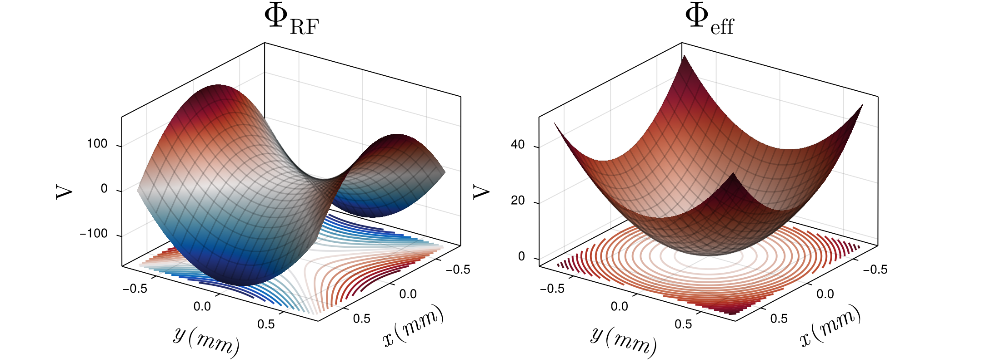

(Scene(2 children, 0 plots), Axis3 (15 plots), Axis3 (15 plots))

In [115]:
function plotRealvsEff(r_0, V_RF, q_x, q_y, Ω, M, Q, η; colormap=:balance, azim=pi/5, elev=pi/8, gap_factor=0.05, step=14)
    xs = LinRange(-r_0, r_0, 300)
    ys = LinRange(-r_0, r_0, 300)

    Φ_RF = (η * V_RF) / (2r_0^2) .* (xs'.^2 .- ys.^2); z1_min, z1_max = minimum(Φ_RF), maximum(Φ_RF); gap_1 = (z1_max - z1_min) * gap_factor
    Φ_eff = ((M * Ω^2 / 16) .* ((q_x .* xs').^2 .+ (q_y .* ys).^2)) / Q; z2_min, z2_max = minimum(Φ_eff), maximum(Φ_eff); gap_2 = (z2_max - z2_min) * gap_factor

    fig = Figure(size=(1100,400))
    ax1 = Axis3(fig[1, 1],
        xlabel = L"x\, (mm)", xlabelsize=25,
        ylabel = L"y\, (mm)", ylabelsize=25,
        zlabel = L"\text{V}", zlabelsize=25,
        title = L"\Phi_{\mathrm{RF}}", titlesize=40,
        azimuth = azim, elevation = elev  
    )
    ax2 = Axis3(fig[1, 2],
        xlabel = L"x\, (mm)", xlabelsize=25,
        ylabel = L"y\, (mm)", ylabelsize=25,
        zlabel = L"\text{V}", zlabelsize=25,
        title = L"\Phi_{\mathrm{eff}}", titlesize=40,
        azimuth = azim, elevation = elev
    )

    surface!(ax1, xs*1e3, ys*1e3, Φ_RF; colormap=colormap, transparency = true)
    xm, ym, zm = minimum(ax1.finallimits[]);
    contour!(ax1, xs*1e3, ys*1e3, Φ_RF; levels = 20, colormap=colormap, linewidth = 2,
    colorrange = (z1_min, z1_max), transformation = (:xy, z1_min-gap_1),
    transparency = false)
    wireframe!(ax1, xs[1:step:end]*1e3, ys[1:step:end]*1e3, Φ_RF[1:step:end, 1:step:end]; overdraw = false, transparency = false,
    color = (:black, 0.1), depth_shift = -1.0f-2)

    surface!(ax2, xs*1e3, ys*1e3, Φ_eff; colormap=colormap, transparency = true, colorrange = (-z2_max, z2_max))
    xm, ym, zm = minimum(ax2.finallimits[]);
    contour!(ax2, xs*1e3, ys*1e3, Φ_eff; levels = 20, colormap=colormap, linewidth = 2,
    colorrange = (-z2_max, z2_max), transformation = (:xy, z2_min-gap_2),
    transparency = false)
    wireframe!(ax2, xs[1:step:end]*1e3, ys[1:step:end]*1e3, Φ_eff[1:step:end, 1:step:end]; overdraw = false, transparency = false,
    color = (:black, 0.1), depth_shift = -1.0f-2)

    colgap!(fig.layout, -150)
    display(fig)
    return fig, ax1, ax2
end

plotRealvsEff(r_0, V_RF, q_x, q_y, Ω, M, Q, η)

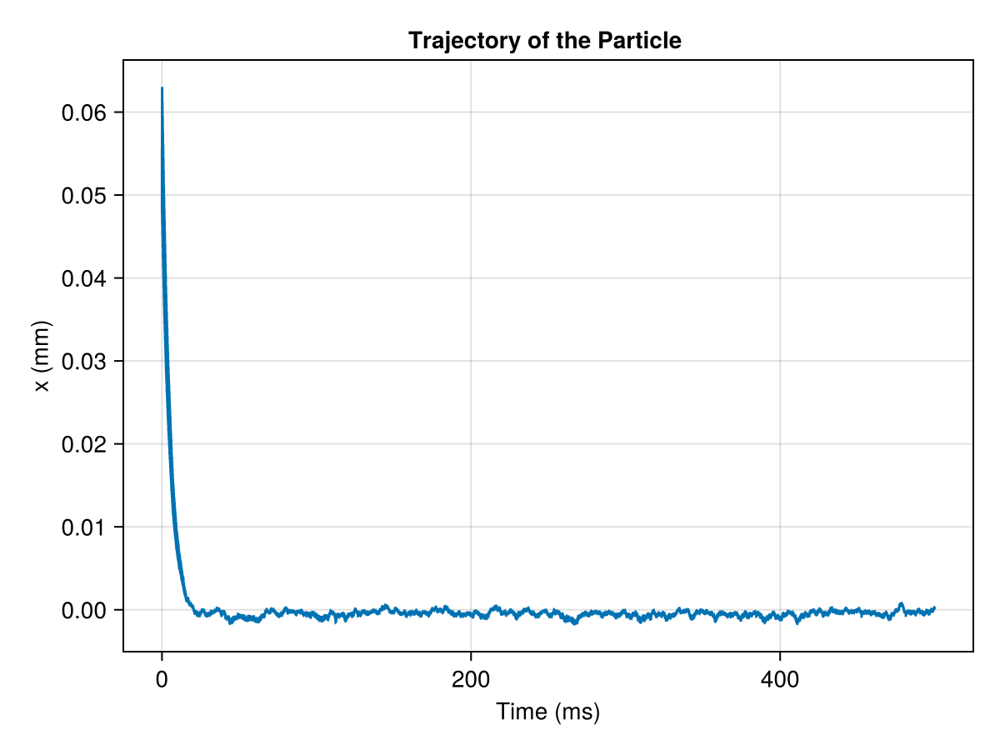

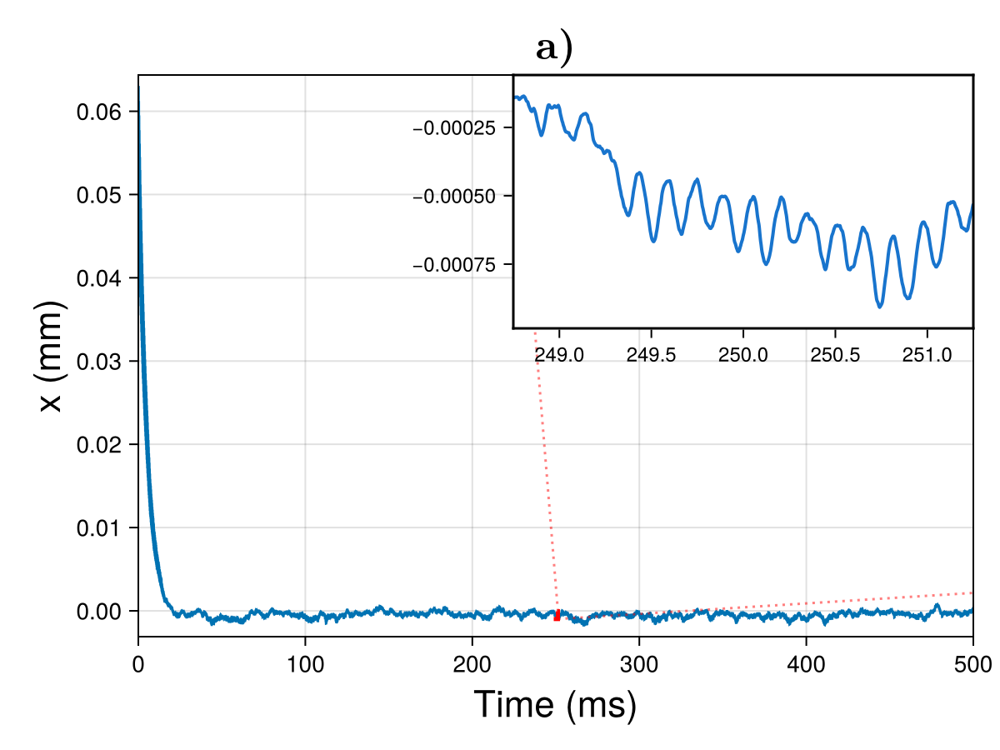

SystemError: SystemError: opening file "c:\\Users\\chris\\OneDrive\\Proyectos\\trap\\reports\\figures\\x_traj_zoom.png": No such file or directory

In [116]:
fig, ax = plot1dTraj(r_t[:,1], ts; step=10, dim="x")
ax.title = L"\textbf{a)}"
ax.titlesize = 24
ax.xlabelsize = 22
ax.ylabelsize = 22
ax.xticklabelsize = 14
ax.yticklabelsize = 14

n_points = length(ts)
center_idx = div(n_points, 2) 
span = 2500

idx_min = max(1, center_idx - span)
idx_max = min(n_points, center_idx + span)

t_z = ts[idx_min:idx_max].*1e3
y_z = r_t[idx_min:idx_max, 1].*1e3

tz_min, tz_max = t_z[1], t_z[end]
yz_min, yz_max = minimum(y_z), maximum(y_z)
y_margin = (yz_max - yz_min) * 0.1

color_ref = :red

lines!(ax, 
    [tz_min, tz_max, tz_max, tz_min, tz_min], 
    [yz_min-y_margin, yz_min-y_margin, yz_max+y_margin, yz_max+y_margin, yz_min-y_margin],
    color = color_ref, linewidth = 2.5, linestyle = :dash
)

x_main_max = ts[end].*1e3
x_main_min = ts[1].*1e3

data_max = maximum(r_t[:,1].*1e3)
data_min = minimum(r_t[:,1].*1e3)
data_span = data_max - data_min

y_limit_max = data_max + data_span * 0.02
y_limit_min = data_min - data_span * 0.02

limits!(ax, x_main_min, x_main_max, y_limit_min, y_limit_max)

rel_height = 0.45
rel_width = 0.55

x_span = x_main_max - x_main_min
y_span = y_limit_max - y_limit_min

x_inset_left = x_main_max - (x_span * rel_width)
y_inset_bottom = y_limit_max - (y_span * rel_height)

lines!(ax, [tz_max, x_inset_left], [yz_max+y_margin, y_limit_max], 
    color = (:red, 0.5), linewidth = 1.5, linestyle = :dot)

lines!(ax, [tz_max, x_inset_left+2800], [yz_min-y_margin, y_inset_bottom], 
    color = (:red, 0.5), linewidth = 1.5, linestyle = :dot)

ax_zoom = Axis(fig[1, 1],
    width = Relative(rel_width),
    height = Relative(rel_height),
    halign = :right,
    valign = :top,
    backgroundcolor = :white,
    xticklabelsize = 12, 
    yticklabelsize = 12,
    xgridvisible = true, 
    ygridvisible = true,
    xminorgridvisible = false,
    spinewidth = 1.5,
    bottomspinecolor = :black, 
    topspinecolor = :black,
    leftspinecolor = :black, 
    rightspinecolor = :black,
    xlabel = "", 
    ylabel = ""
)

lines!(ax_zoom, t_z, y_z, color = :dodgerblue3, linewidth = 2)

limits!(ax_zoom, tz_min, tz_max, yz_min - y_margin, yz_max + y_margin)

translate!(ax_zoom.scene, 0, 0, 10)
translate!(ax_zoom.elements[:background], 0, 0, 9)

display(fig)
save("../reports/figures/x_traj_zoom.png", fig; px_per_unit=4)

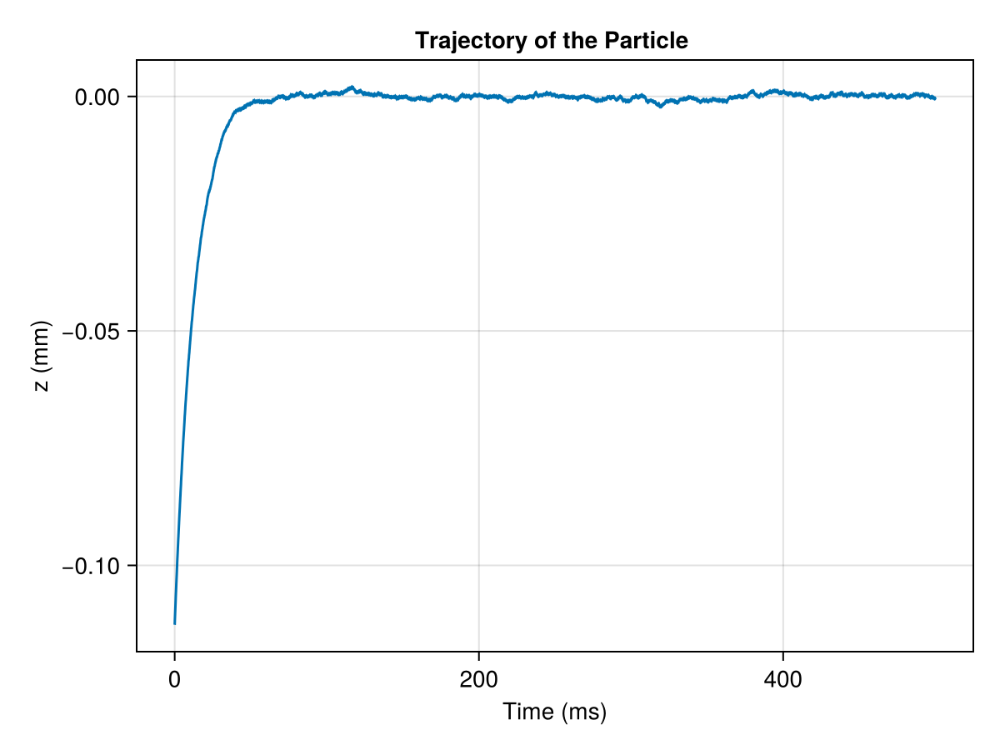

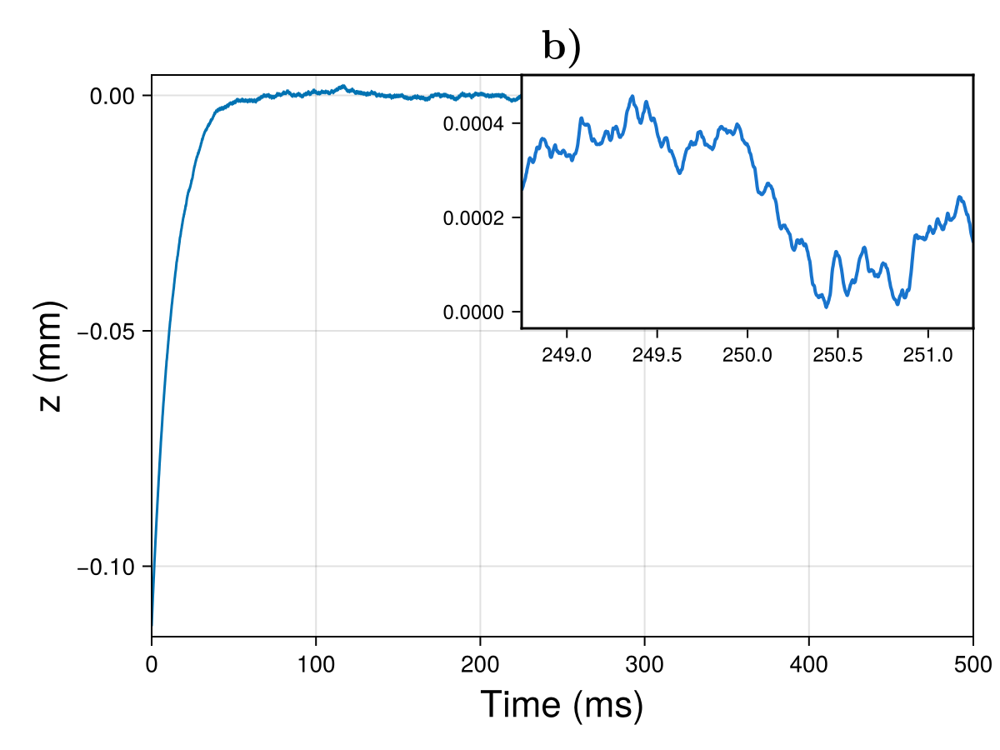

SystemError: SystemError: opening file "c:\\Users\\chris\\OneDrive\\Proyectos\\trap\\reports\\figures\\z_traj_zoom.png": No such file or directory

In [117]:
fig, ax = plot1dTraj(r_t[:,3], ts; step=10, dim="z")
ax.title = L"\textbf{b)}"
ax.titlesize = 24
ax.xlabelsize = 22
ax.ylabelsize = 22
ax.xticklabelsize = 14
ax.yticklabelsize = 14

n_points = length(ts)
center_idx = div(n_points, 2) 
span = 2500

idx_min = max(1, center_idx - span)
idx_max = min(n_points, center_idx + span)

t_z = ts[idx_min:idx_max].*1e3
y_z = r_t[idx_min:idx_max, 3].*1e3

tz_min, tz_max = t_z[1], t_z[end]
yz_min, yz_max = minimum(y_z), maximum(y_z)
y_margin = (yz_max - yz_min) * 0.1

color_ref = :red

lines!(ax, 
    [tz_min, tz_max, tz_max, tz_min, tz_min], 
    [yz_min-y_margin, yz_min-y_margin, yz_max+y_margin, yz_max+y_margin, yz_min-y_margin],
    color = color_ref, linewidth = 2.5, linestyle = :dash
)

x_main_max = ts[end].*1e3
x_main_min = ts[1].*1e3

data_max = maximum(r_t[:,3].*1e3)
data_min = minimum(r_t[:,3].*1e3)
data_span = data_max - data_min

y_limit_max = data_max + data_span * 0.02
y_limit_min = data_min - data_span * 0.02

limits!(ax, x_main_min, x_main_max, y_limit_min, y_limit_max)

rel_height = 0.45
rel_width = 0.55

x_span = x_main_max - x_main_min
y_span = y_limit_max - y_limit_min

x_inset_left = x_main_max - (x_span * rel_width)
y_inset_bottom = y_limit_max - (y_span * rel_height)

lines!(ax, [tz_max, x_inset_left], [yz_max+y_margin, y_limit_max], 
    color = (:red, 0.5), linewidth = 1.5, linestyle = :dot)

lines!(ax, [tz_max, x_inset_left+5500], [yz_min-y_margin, y_inset_bottom], 
    color = (:red, 0.5), linewidth = 1.5, linestyle = :dot)

ax_zoom = Axis(fig[1, 1],
    width = Relative(rel_width),
    height = Relative(rel_height),
    halign = :right,
    valign = :top,
    backgroundcolor = :white,
    xticklabelsize = 12, 
    yticklabelsize = 12,
    xgridvisible = true, 
    ygridvisible = true,
    xminorgridvisible = false,
    spinewidth = 1.5,
    bottomspinecolor = :black, 
    topspinecolor = :black,
    leftspinecolor = :black, 
    rightspinecolor = :black,
    xlabel = "", 
    ylabel = ""
)

lines!(ax_zoom, t_z, y_z, color = :dodgerblue3, linewidth = 2)

limits!(ax_zoom, tz_min, tz_max, yz_min - y_margin, yz_max + y_margin)

translate!(ax_zoom.scene, 0, 0, 10)
translate!(ax_zoom.elements[:background], 0, 0, 9)

display(fig)
save("../reports/figures/z_traj_zoom.png", fig; px_per_unit=4)

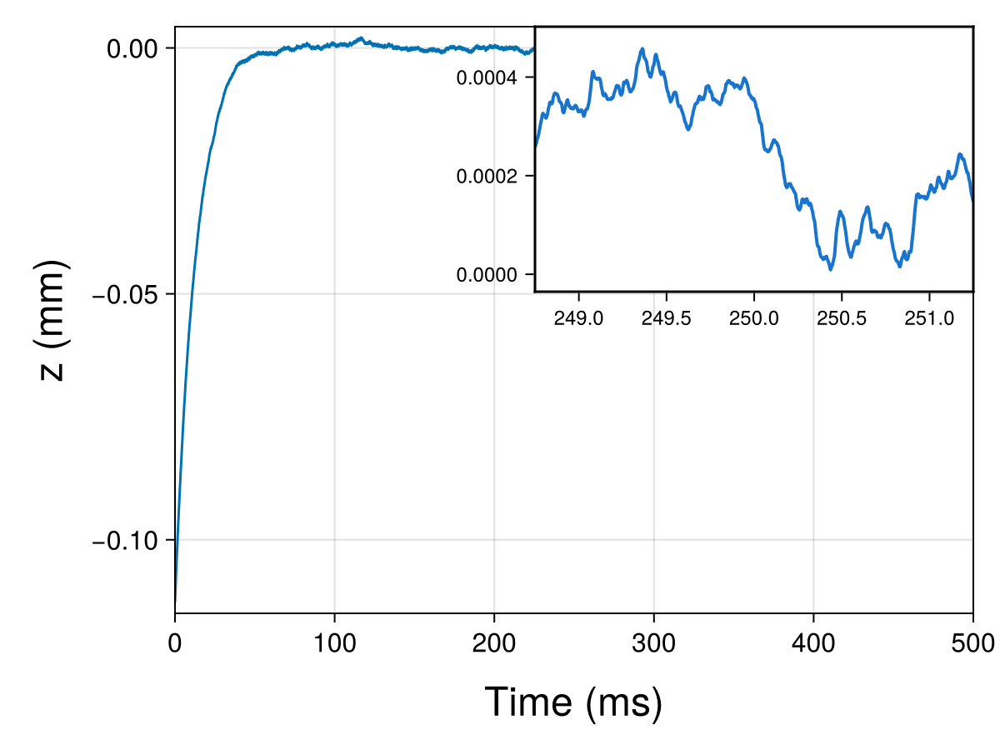

SystemError: SystemError: opening file "c:\\Users\\chris\\OneDrive\\Proyectos\\trap\\reports\\figures\\Q_M_est.png": No such file or directory

In [118]:
ax.title = ""
ax.xlabelsize = 24
ax.ylabelsize = 24
ax.xticklabelsize = 16
ax.yticklabelsize = 16
ax.xlabelpadding = 12
ax.ylabelpadding = 12

display(fig)
save("../reports/figures/Q_M_est.png", fig; px_per_unit=4)

In [119]:
τ_est3, fig, ax = getEstimatedτ("../analysis/exp3/eq_3.txt"; t_min=12.42, offset=4.3e-3); @show sqrt(γ/(M*τ_est3))

ax.title = "" 
ax.xlabel = "Time (s)" 
ax.ylabel = "Amplitude (mm)"
ax.xlabelsize = 24
ax.ylabelsize = 24
ax.xgridstyle = :dash
ax.ygridstyle = :dash
ax.xgridcolor = (:black, 0.15)
ax.ygridcolor = (:black, 0.15)
ax.spinewidth = 1.5
ax.xtickwidth = 1.5
ax.ytickwidth = 1.5

sim_plot = lines!(ax, ts, z_comsol .* 1e3, 
    label = "FEM Simulation",
    color = (:forestgreen, 0.7), 
    linewidth = 2.5, 
    linestyle = :dash 
)

translate!(sim_plot, 0, 0, -5)

if length(ax.scene.plots) >= 1
    translate!(ax.scene.plots[1], 0, 0, 5)
end

if length(ax.scene.plots) >= 3 
    if hasproperty(ax.scene.plots[1], :label)
        ax.scene.plots[1].label = "Experimental Data"
    end
    if hasproperty(ax.scene.plots[2], :label)
        ax.scene.plots[2].label = "Exponential Fit"
    end
end

axislegend(ax; 
    position = :rt, 
    labelsize = 18,
    backgroundcolor = :white,
    framevisible = true,
    framewidth = 1.0,
    padding = (10, 10, 10, 10)
)

display(fig)
save("../reports/figures/omega_est.png", fig; px_per_unit=4)

ArgumentError: ArgumentError: "../analysis/exp3/eq_3.txt" is not a valid file or doesn't exist

### Parameters

In [120]:
# Trap parameters microdiamonds
V_RF = 900 
f = 0.6e3 
Ω = 2*π*f
V_EC = 30   

# Trap geometry
# r_e = 3.985e-3
r_0 = 1e-3
z_0 = 2e-3
# κ = 1
# η = 1
ϵ = 1/2

# Particle characteristics (microdiamonds)
e⁻ = 1.60217663e-19 # Charge of the electron [C]
# Q = 10^4 * e⁻
ρ = 3520  # Density [kg/m³]
R = 5e-6 # Radius of the particle [m]
Vol = 4/3 * π * R^3
M = ρ * Vol
Q = M * 4e-3 # approx to yield 2 mC/kg

# Gas characteristics
k_b = 1.38e-23 # Boltzmann constant [J/K]
ηᵥ = 1.8e-5 # Air viscosity [kg/m*s] [Pa·s]
T = 273.15 # Ambient temperature [K]
P = 10e-7  * 100 # Pressure [Pa]       
d = 0.37e-9 # Diameter of air molecule [m]
λₘfₚ = k_b*T / (sqrt(2)*π*d^2*P) # Mean free path
Kₙ = λₘfₚ / R # 
γ = 6*π*ηᵥ*R * 0.619/(0.619+Kₙ) * (1 + (0.31*Kₙ)/(0.785+1.152*Kₙ+Kₙ^2)) # Damping coefficient [kg/s]

8.472123978005811e-17

In [ ]:
# Trap parameters microparticles silica
V_RF = 5000.0
f = 5e3 
Ω = 2*π*f
V_EC = 30.0

# Trap geometry
# r_e = 3.985e-3
r_0 = 1e-3
z_0 = 2e-3
# κ = 1
# η = 1
ϵ = 1/2

# Particle characteristics (microdiamonds)
e⁻ = 1.60217663e-19 # Charge of the electron [C]
# Q = 10^4 * e⁻
ρ = 3520  # Density [kg/m³]
R = 0.5e-6 # Radius of the particle [m]
Vol = 4/3 * π * R^3
M = ρ * Vol
# Q = M * 0.011546913073395382 # approx to yield 11 mC/kg (100e for a 1 um silica crystal)
Q = 1000e⁻

# Gas characteristics
k_b = 1.38e-23 # Boltzmann constant [J/K]
ηᵥ = 1.8e-5 # Air viscosity [kg/m*s] [Pa·s]
T = 273.15 # Ambient temperature [K]
P = 0.01  * 100 # Pressure [Pa]       
d = 0.37e-9 # Diameter of air molecule [m]
λₘfₚ = k_b*T / (sqrt(2)*π*d^2*P) # Mean free path
Kₙ = λₘfₚ / R # 
γ = 6*π*ηᵥ*R * 0.619/(0.619+Kₙ) * (1 + (0.31*Kₙ)/(0.785+1.152*Kₙ+Kₙ^2)) # Damping coefficient [kg/s]

8.47191297281725e-15

In [ ]:
# Trap parameters 40Ca⁺
V_RF = 1000.0
f = 23.5e6 
Ω = 2*π*f
V_EC = 30.0

# Trap geometry
# r_e = 3.985e-3
r_0 = 0.8e-3
z_0 = 1e-3
# κ = 1
# η = 1
ϵ = 1/2

# Particle characteristics (40Ca⁺)
e⁻ = 1.60217663e-19 # Charge of the electron [C]
# Q = 10^4 * e⁻
M = 6.636e-26
Q = 1e⁻

# https://trapsensor.ugr.es/pages/trabajos/tfm_joaquin_berrocal/! 
# page 15
plotf_secvsV_RF((1.5e6, 4.5e6), (400, 1.5e3), Q/M, 1, 1, r_0, z_0, V_EC, V_RF, f; 
            interactive=true, Q╱M_range=(1e⁻:1e⁻:2e⁻)*1e3/M, V_EC_range=(0:1:1000))


#### Estimate $\eta$ and $\kappa$

##### Import scalar field

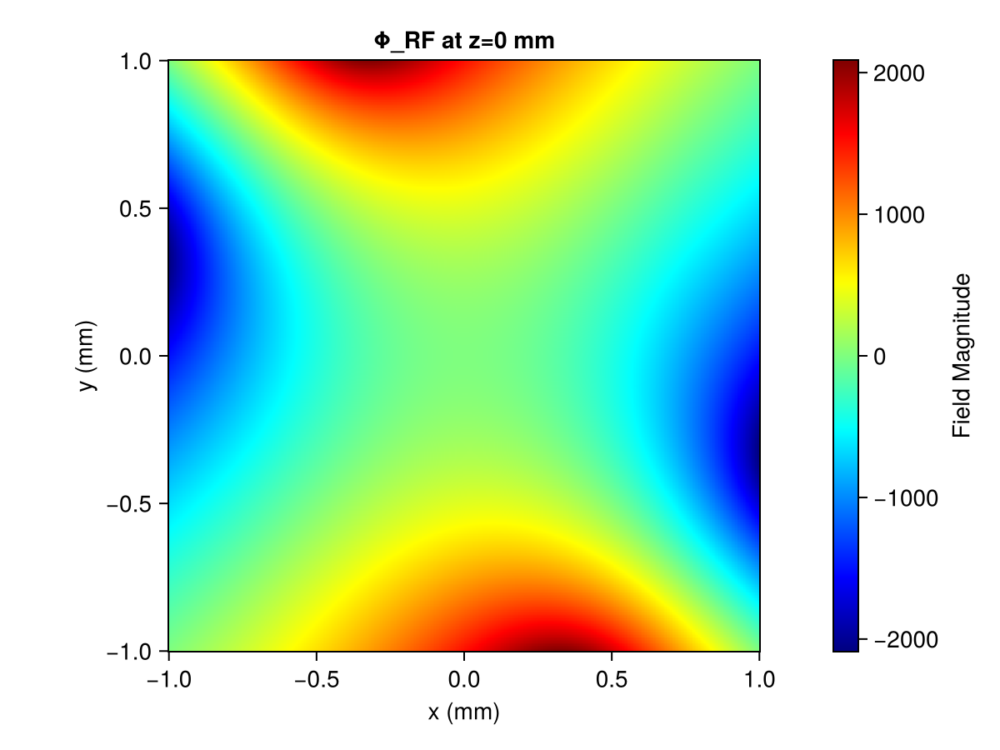

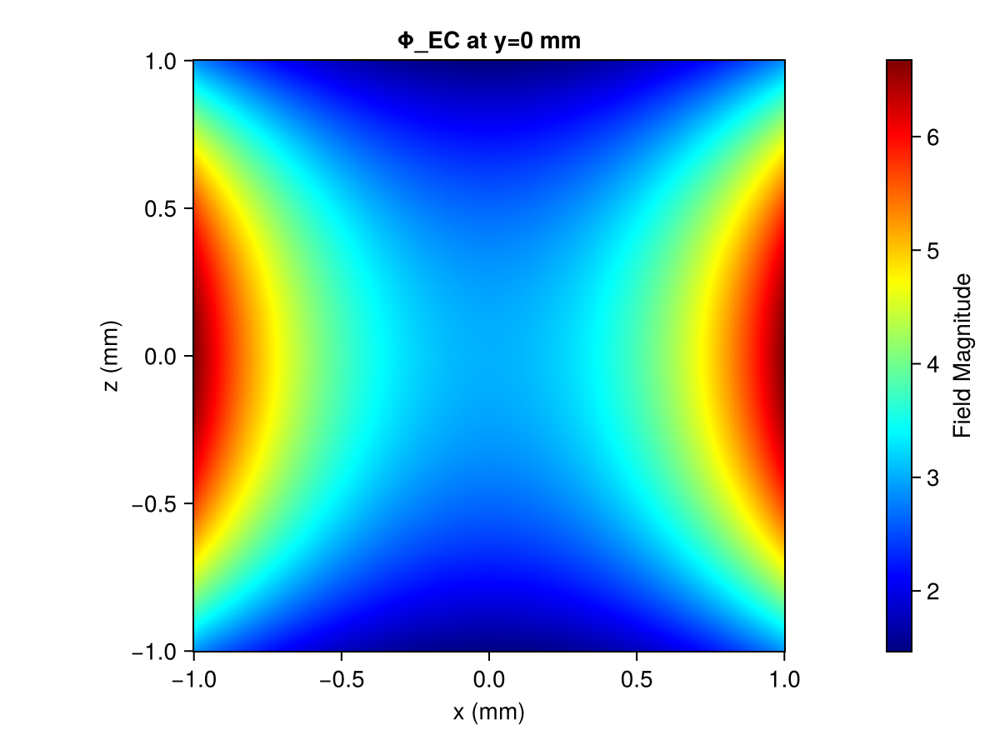

In [571]:
xs = LinRange(-1e-3, 1e-3, 500); nx = size(xs, 1); Δx = step(xs);
ys = LinRange(-1e-3, 1e-3, 500); ny = size(ys, 1); Δy = step(ys);
zs = LinRange(-1e-3, 1e-3, 500); nz = size(zs, 1); Δz = step(zs);

Φs_grid  = importComsolField3D(nx, ny, nz, "Phis.txt", 2)
    Φ_RF_grid = V_RF/2 .* Φs_grid[:,:,:,1]
    Φ_EC_grid = V_EC .* Φs_grid[:,:,:,2]

plotFieldSlice(xs, ys, Φ_RF_grid[:,:,ceil(Int,nz/2)]; 
    title="Φ_RF at z=0 mm", xlabel="x (mm)", ylabel="y (mm)",
    colormap=:jet);
plotFieldSlice(xs, ys, Φ_EC_grid[:,ceil(Int,ny/2),:]; 
    title="Φ_EC at y=0 mm", xlabel="x (mm)", ylabel="z (mm)",
    colormap=:jet);

Φs_z = Φ_EC_grid[ceil(Int,nx/2) , ceil(Int,ny/2) , :             ]
Φs_x = Φ_RF_grid[:              , ceil(Int,ny/2) , ceil(Int,nz/2)]
Φs_y = Φ_RF_grid[ceil(Int,nx/2) , :              , ceil(Int,nz/2)];

##### Calculate $\eta$ and $\kappa$

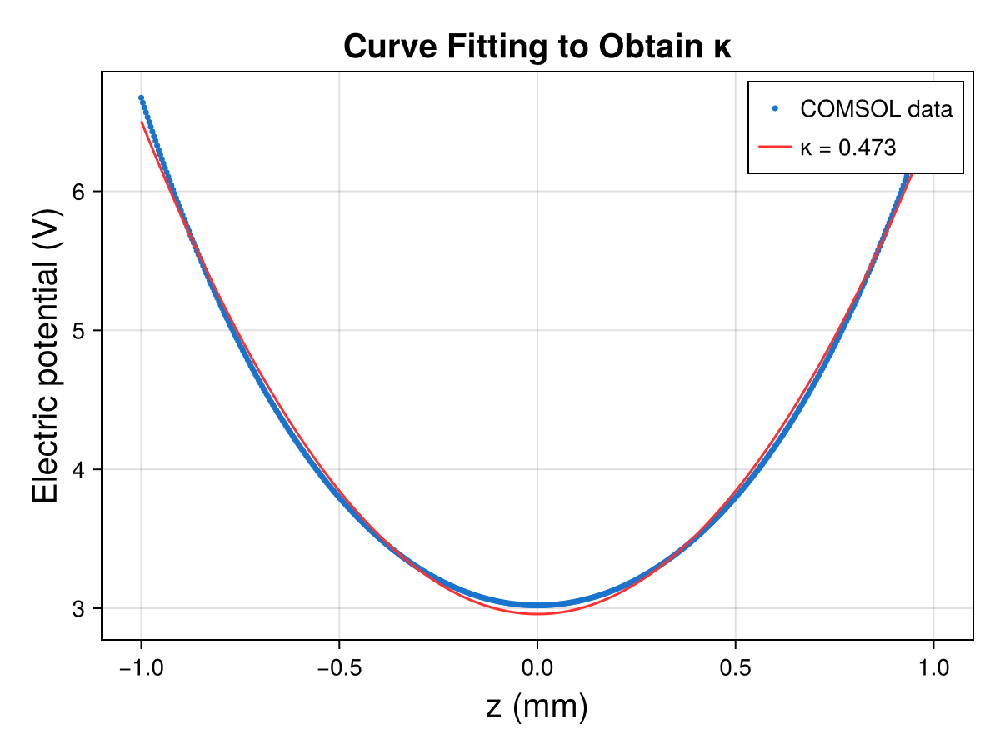

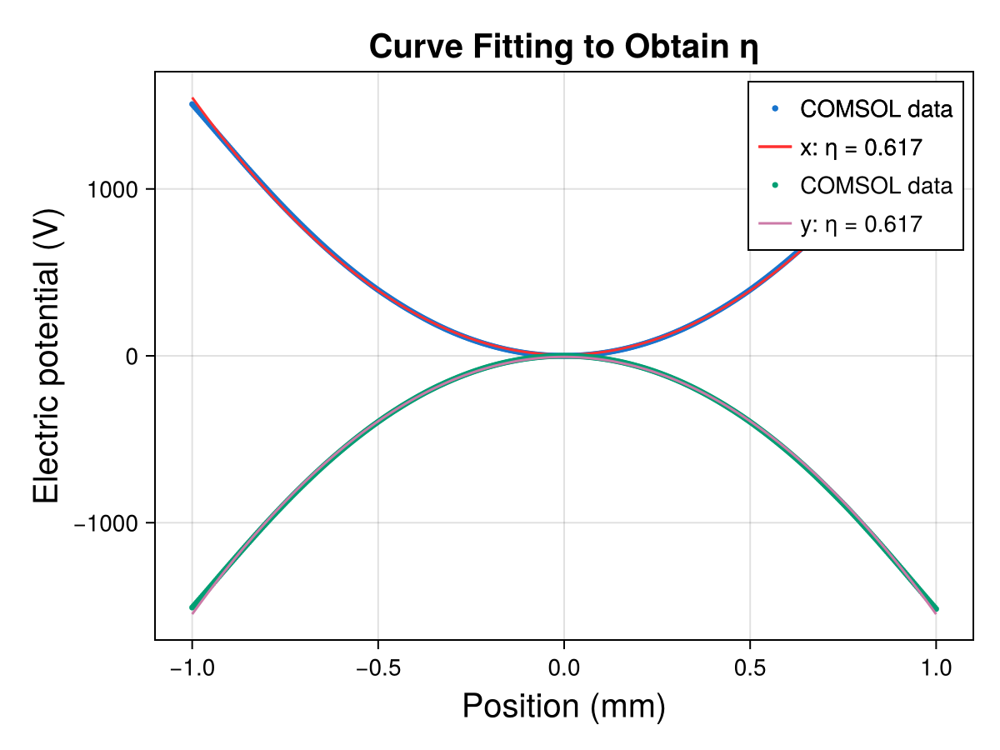

In [572]:
κ, fig, ax = getEfficiencyFactor("κ", V_EC, collect(zs), Φs_z, z_0, return_fig=true); save("kappa_fit.png", fig; px_per_unit=10) 
η, fig, ax = getEfficiencyFactor("η", V_RF, [collect(xs),collect(ys)], [Φs_x, Φs_y], r_0, return_fig=true); save("eta_fit.png", fig; px_per_unit=10) 

In [595]:
D_r = (Q*V_RF^2*η^2)/(4*M*Ω^2*r_0^2)-κ*V_EC/2*r_0^2/z_0^2;
@show("D_r = $(D_r) V", "U_r = $(Q*D_r*6.2415e18) eV")

"U_r = 207515.9093317023 eV"

### Stability

#### Stability parameters

In [576]:
a_x = -(8*Q*V_EC*κ*ϵ)/(M*Ω^2*z_0^2)
a_y = a_x*(1/ϵ-1) 
a_z = -a_x/ϵ

q_x = -(2*Q*V_RF*η)/(M*Ω^2*r_0^2)
q_y = -q_x
q_z = 0 

display(
    DataFrame(
    Parameter = ["a_x", "a_y", "a_z", "q_x", "q_y", "q_z"],
    Value     = [a_x, a_y, a_z, q_x, q_y, q_z]
    )
)

ω_x = Ω/2*sqrt(a_x + q_x^2/2)
ω_y = Ω/2*sqrt(a_y + q_y^2/2)
ω_z = Ω/2*sqrt(a_z)

display(
    DataFrame(
    Parameter = ["ω_x", "ω_y", "ω_z", "γ/2M"],
    Value     = [ω_x, ω_y, ω_z, γ/2M]
    )
)
@show Q_factor = ω_x/(γ/M)

Row,Parameter,Value
,String,Float64
1,a_x,-0.00124927
2,a_y,-0.00124927
3,a_z,0.00249853
4,q_x,-0.543085
5,q_y,0.543085
6,q_z,0.0


Row,Parameter,Value
,String,Float64
1,ω_x,6006.56
2,ω_y,6006.56
3,ω_z,785.168
4,γ/2M,2.29832


1306.728509260559

#### Stability region

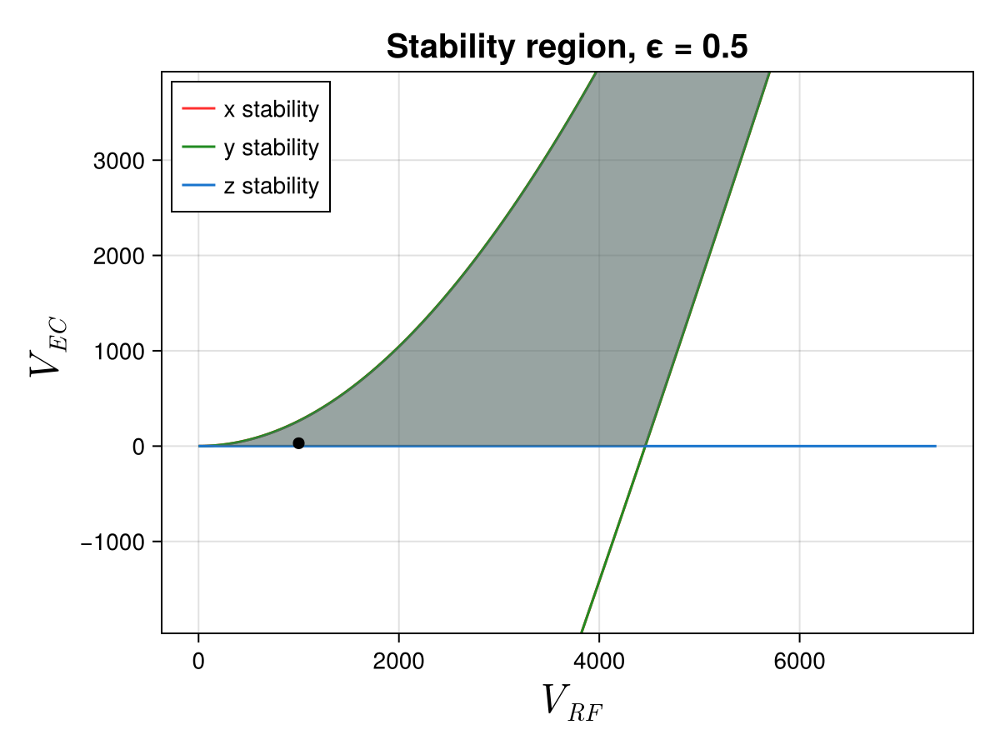

CairoMakie.Screen{IMAGE}


In [12]:
fig, ax = plotStabilityRegion(V_RF, V_EC; M=M, Ω=Ω, z₀=z_0, r₀=r_0, Q=Q, κ=κ, η=η, ϵ=ϵ); 
display(GLMakie.Screen(), fig.scene); display(fig); 
# fig, ax = plotStabilityRegion(M=M, Ω=1.5Ω, z₀=z_0, r₀=r_0, Q=Q, κ=κ, η=η, ϵ=ϵ); display(fig)

#### Parameter map

In [594]:
plotfvsV_RF((0.05e3, 10e3), (10, 8e3), Q/M, η, κ, r_0, z_0, V_EC, V_RF, f; 
            interactive=true, Q╱M_range=(1e⁻:1e⁻:2000e⁻)*1e3/M)  
plotf_secvsV_RF((0.05e3, 2e3), (10, 6e3), Q/M, η, κ, r_0, z_0, V_EC, V_RF, ω_x/2π; 
            interactive=true, Q╱M_range=(1e⁻:1e⁻:2000e⁻)*1e3/M)      

GLMakie.Screen(...)

### Stochastic simulation

#### Params

In [ ]:
g = 9.81 # gravitational acceleration
ĝ = normalize([-1.0, -1.0, 0.0])
W = M*g

function F_theory(r, t) 
    x = r[1]; y = r[2]; z = r[3];
    Fx = -M * (Ω^2/4*(a_x - 2*q_x*cos(Ω*t))*x) + W*ĝ[1]
    Fy = -M * (Ω^2/4*(a_y - 2*q_y*cos(Ω*t))*y) + W*ĝ[2]
    Fz = -M * (Ω^2/4*(a_z)*z) + W*ĝ[3]
    return [Fx, Fy, Fz]
end

n_t = 1000000 # time steps
t_total = 500 / 1000 # total time in seconds
ts = LinRange(0, t_total, n_t); Δt = step(ts)
r₀ = (0.5*r_0)*rand()^(1/3) * normalize(randn(3))
# thermal eq
# v₀ = rand(Normal(0,sqrt(k_b*T/M)), 3)
# falling
v₀ = (W/γ)*ĝ*0;
@show(v₀, r₀, Δt)

5.000005000005e-7

#### Run

In [356]:
success = false
max_tries = 10; tries = 0
r_lim2 = (r_0 - R)^2
while !success && tries < max_tries
    global r_t, v_t, r₀
    r₀ = (0.9*r_0)*rand()^(1/3) * normalize(randn(3))
    r_t, v_t = simulate(ts, t_total, r₀, v₀, γ, M, k_b, T, F_theory);
    if all(sum(r_t[:, 1:2].^2, dims=2) .< r_lim2)
        success = true
        break
    else
        println("Particle escaped trap, retrying...")
        tries += 1
    end
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:03


In [172]:
r_t, v_t = simulate(ts, t_total, r₀, v₀, γ, M, k_b, T, F_theory); 

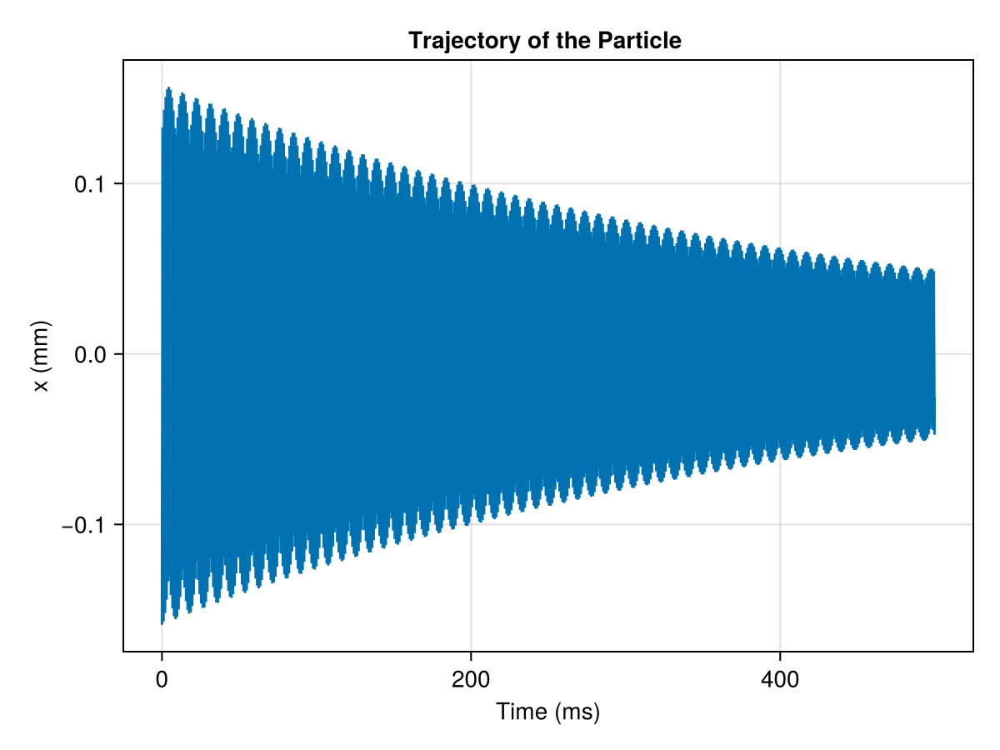

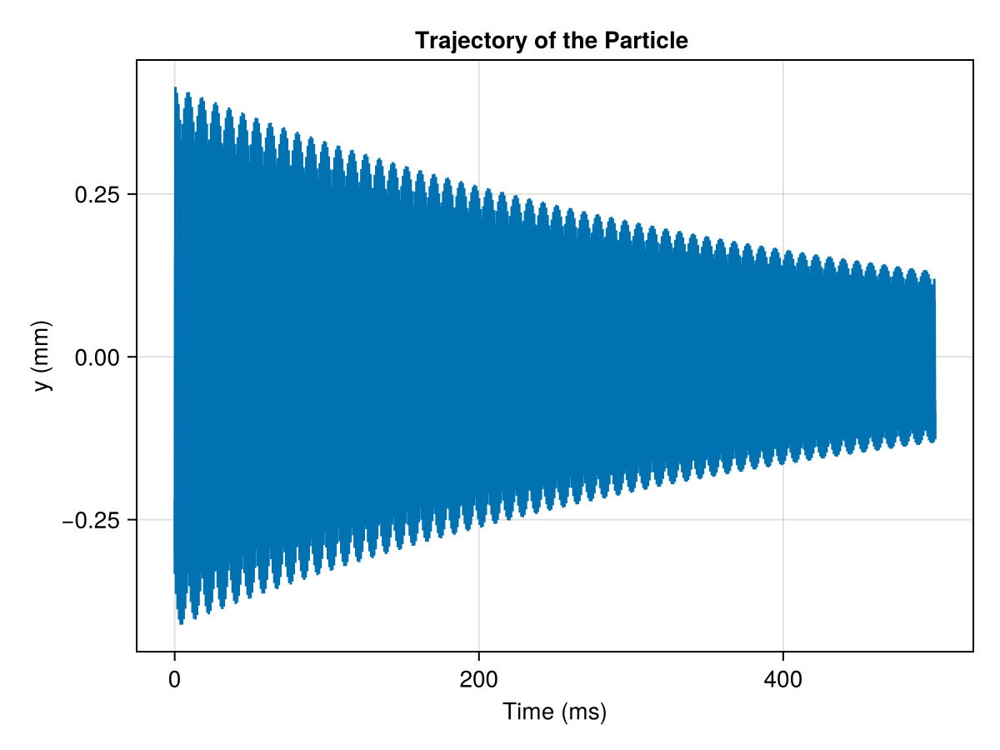

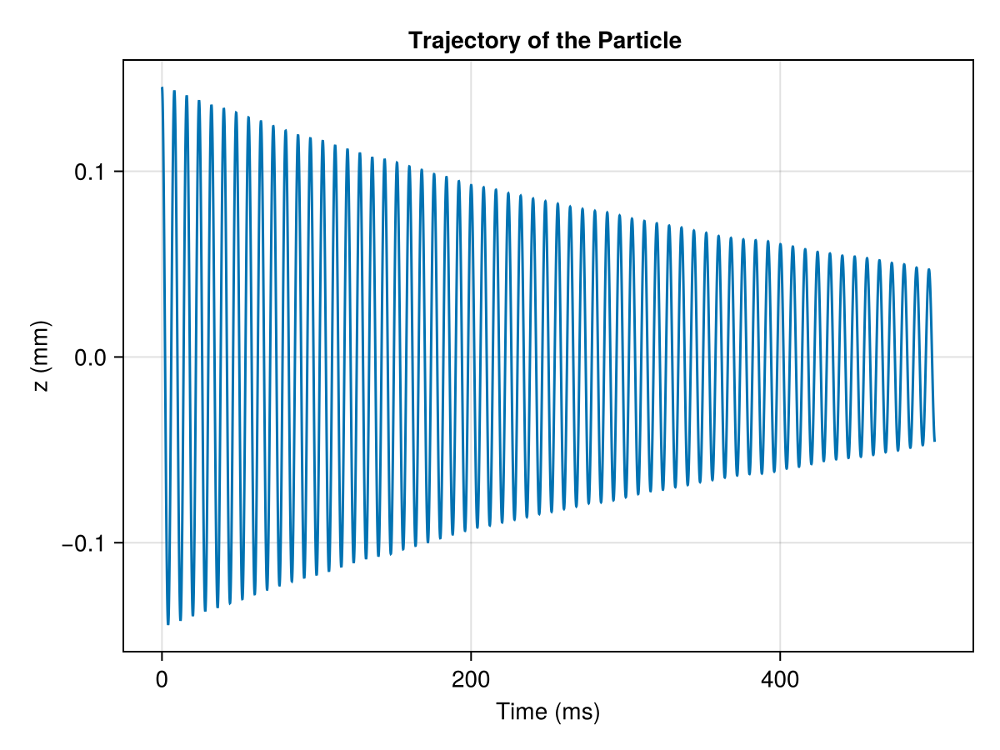

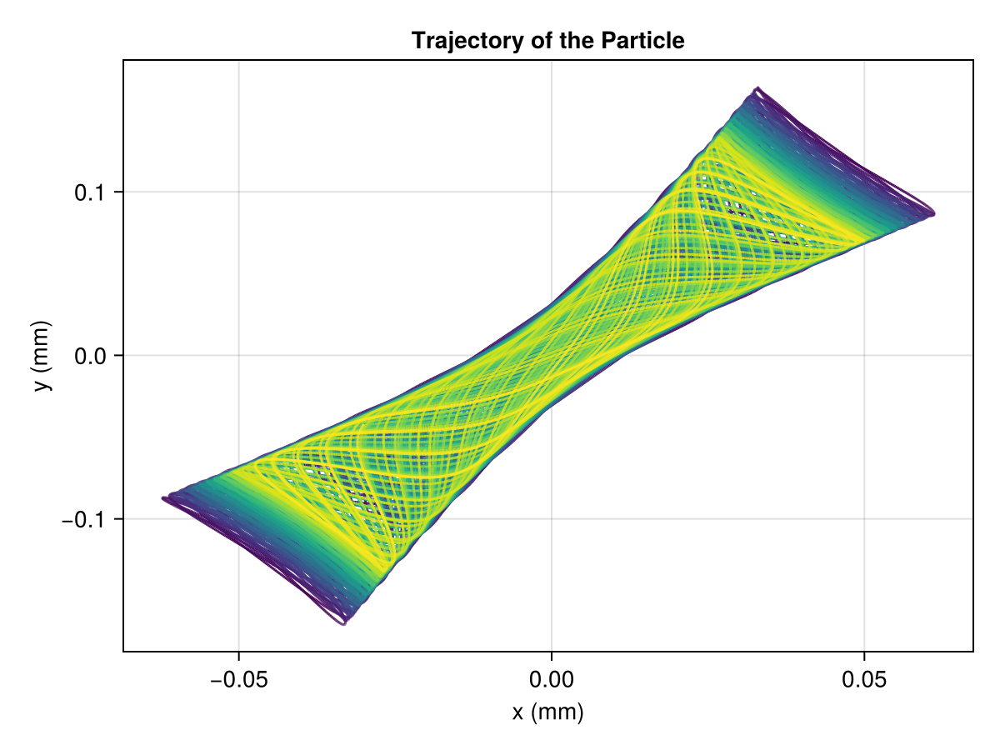

In [173]:
# plot3dTraj(r_t; step=100, r₀=r₀, showTrap=true, trap_path="trap_v1.1.stl");
plot1dTraj(r_t[:,1], ts; step=100, dim="x");
plot1dTraj(r_t[:,2], ts; step=100, dim="y");
plot1dTraj(r_t[:,3], ts; step=100, dim="z");
plot2dTraj(r_t[end-n_t÷5:end,:], ts[end-n_t÷5:end], (1, 2); step=1, dimx="x", dimy="y");

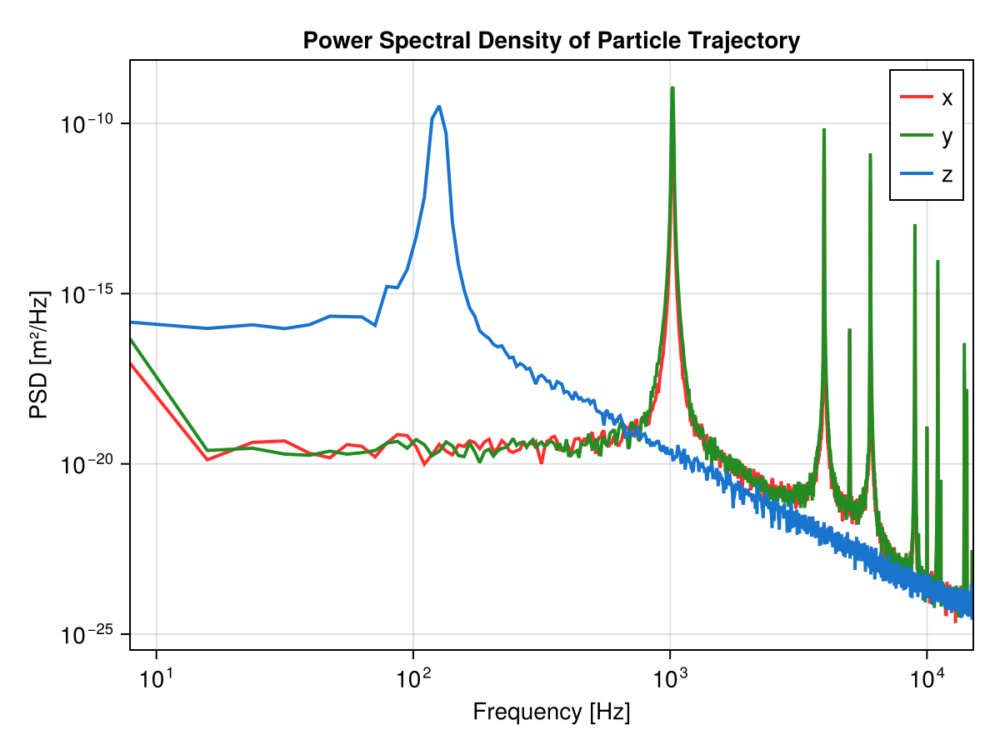

GLMakie.Screen(...)

In [175]:
freqs, psds = getPSD(r_t, Δt; fs_obj=30e3, winlen=n_t÷2)
fig, ax = plotPSD(freqs, psds; step=1)
display(GLMakie.Screen(), fig.scene)

## Simulation with COMSOL potential

#### Import

In [379]:
xs = LinRange(-3e-3, 3e-3, 500); nx = size(xs, 1); Δx = step(xs); iˣ(x) = Integer(div(x,Δx)+div(nx,2))
ys = LinRange(-3e-3, 3e-3, 500); ny = size(ys, 1); Δy = step(ys); iʸ(y) = Integer(div(y,Δy)+div(ny,2))
zs = LinRange(-3e-3, 3e-3, 500); nz = size(zs, 1); Δz = step(zs); iᶻ(z) = Integer(div(z,Δz)+div(nz,2))

E_RF_grid  = importComsolField3D(nx, ny, nz, "E_RF.txt")
    Ex_RF_grid = E_RF_grid[:,:,:,1] 
    Ey_RF_grid = E_RF_grid[:,:,:,2]
    Ez_RF_grid = E_RF_grid[:,:,:,3] 
E_EC_grid = importComsolField3D(nx, ny, nz, "E_EC.txt")
    Ex_EC_grid = E_EC_grid[:,:,:,1]
    Ey_EC_grid = E_EC_grid[:,:,:,2]
    Ez_EC_grid = E_EC_grid[:,:,:,3]
# E_EC2_grid = importComsolField3D(nx, ny, nz, "comsol/sim3/E_EC2.txt")
#     Ex_EC2_grid = E_EC2_grid[:,:,:,1]
#     Ey_EC2_grid = E_EC2_grid[:,:,:,2]
#     Ez_EC2_grid = E_EC2_grid[:,:,:,3]
# E_BTT_grid = importComsolField3D(nx, ny, nz, "comsol/sim3/E_BTT.txt")
#     Ex_BTT_grid = E_BTT_grid[:,:,:,1]
#     Ey_BTT_grid = E_BTT_grid[:,:,:,2]
#     Ez_BTT_grid = E_BTT_grid[:,:,:,3]
# E_RHT_grid = importComsolField3D(nx, ny, nz, "comsol/sim3/E_RHT.txt")
#     Ex_RHT_grid = E_RHT_grid[:,:,:,1]
#     Ey_RHT_grid = E_RHT_grid[:,:,:,2]
#     Ez_RHT_grid = E_RHT_grid[:,:,:,3]
# #

E_RF_norm = sqrt.(Ex_RF_grid.^2 .+ Ey_RF_grid.^2 .+ Ez_RF_grid.^2);
E_EC_norm = sqrt.((Ex_EC_grid).^2 .+ (Ey_EC_grid).^2 .+ (Ez_EC_grid).^2);
# E_EX_norm = sqrt.((Ex_BTT_grid+Ex_RHT_grid).^2 .+ (Ey_BTT_grid+Ey_RHT_grid).^2 .+ (Ez_BTT_grid+Ez_RHT_grid).^2);

500×500×500 Array{Float64, 3}:
[:, :, 1] =
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  …  NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  …  NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
   ⋮                        ⋮            ⋱              ⋮                 
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN

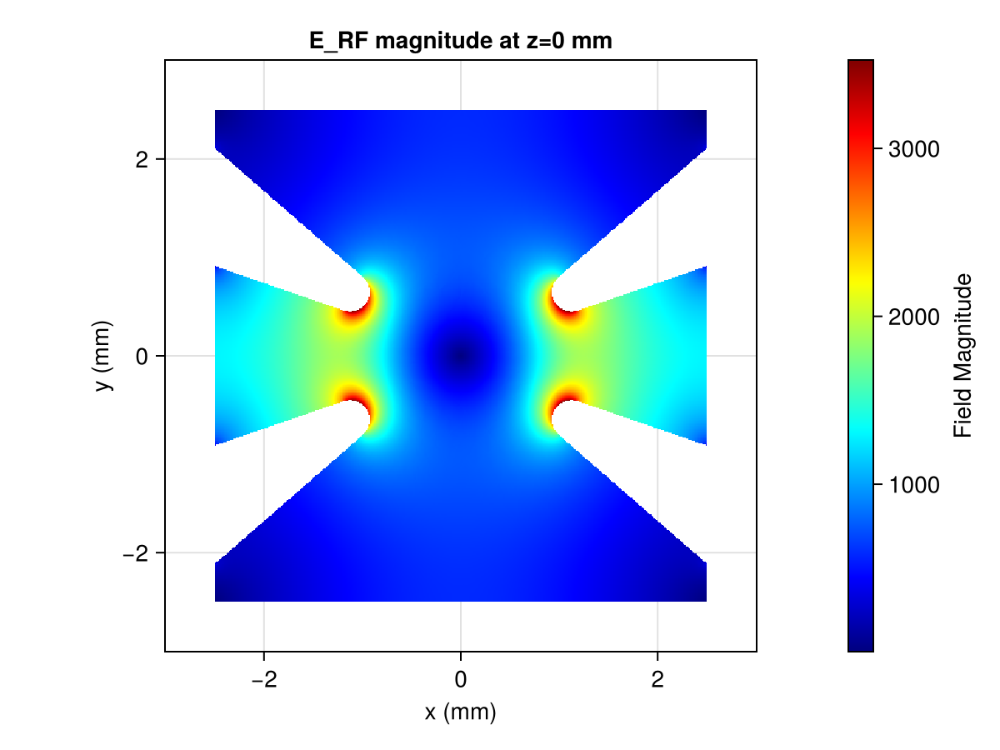

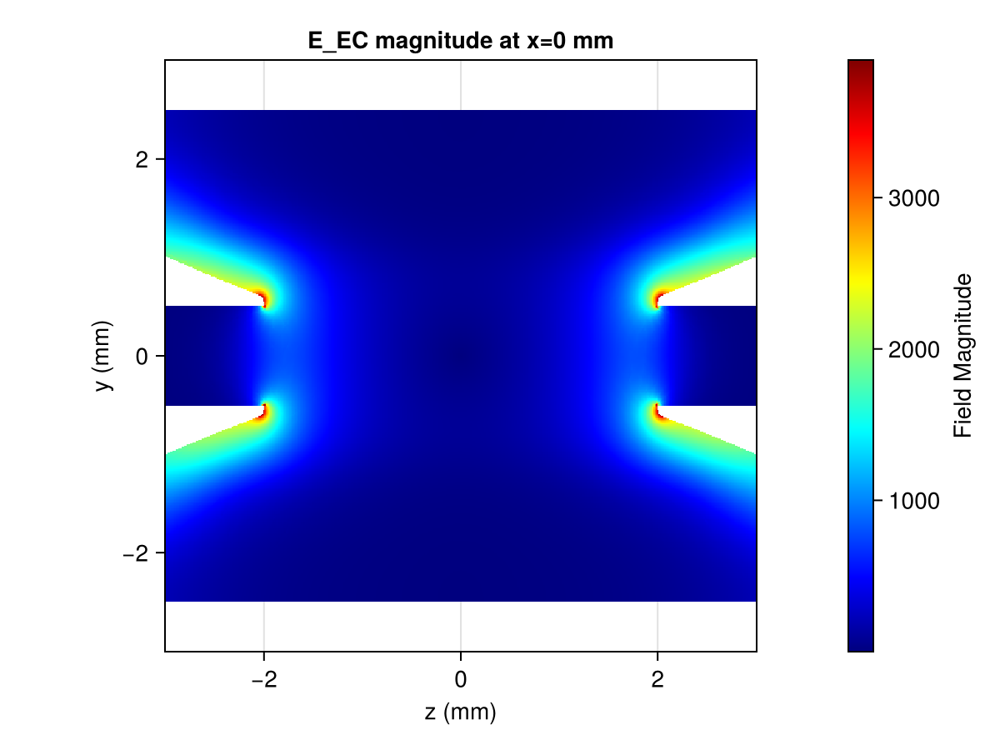

(Scene(2 children, 0 plots), Axis (1 plots))

In [382]:
plotFieldSlice(xs, ys, E_RF_norm[:,:,iᶻ(0)]; 
    title="E_RF magnitude at z=0 mm", xlabel="x (mm)", ylabel="y (mm)",
    colormap=:jet);
plotFieldSlice(xs, ys, E_EC_norm[iˣ(0),:,:]; 
    title="E_EC magnitude at x=0 mm", xlabel="z (mm)", ylabel="y (mm)",
    colormap=:jet)

#### Params

In [109]:
Ex_RF = Interpolations.scale(interpolate(Ex_RF_grid, BSpline(Linear())), xs, ys, zs);
Ey_RF = Interpolations.scale(interpolate(Ey_RF_grid, BSpline(Linear())), xs, ys, zs);
Ez_RF = Interpolations.scale(interpolate(Ez_RF_grid, BSpline(Linear())), xs, ys, zs);

Ex_EC = Interpolations.scale(interpolate(Ex_EC_grid, BSpline(Linear())), xs, ys, zs);
Ey_EC = Interpolations.scale(interpolate(Ey_EC_grid, BSpline(Linear())), xs, ys, zs);
Ez_EC = Interpolations.scale(interpolate(Ez_EC_grid, BSpline(Linear())), xs, ys, zs);

# Ex_EC2 = Interpolations.scale(interpolate(Ex_EC2_grid, BSpline(Linear())), xs, ys, zs);
# Ey_EC2 = Interpolations.scale(interpolate(Ey_EC2_grid, BSpline(Linear())), xs, ys, zs);
# Ez_EC2 = Interpolations.scale(interpolate(Ez_EC2_grid, BSpline(Linear())), xs, ys, zs);

# Ex_BTT = Interpolations.scale(interpolate(Ex_BTT_grid, BSpline(Linear())), xs, ys, zs);
# Ey_BTT = Interpolations.scale(interpolate(Ey_BTT_grid, BSpline(Linear())), xs, ys, zs);
# Ez_BTT = Interpolations.scale(interpolate(Ez_BTT_grid, BSpline(Linear())), xs, ys, zs);

# Ex_RHT = Interpolations.scale(interpolate(Ex_RHT_grid, BSpline(Linear())), xs, ys, zs);
# Ey_RHT = Interpolations.scale(interpolate(Ey_RHT_grid, BSpline(Linear())), xs, ys, zs);
# Ez_RHT = Interpolations.scale(interpolate(Ez_RHT_grid, BSpline(Linear())), xs, ys, zs);

# function F_comsol(r, t) 
#     x = r[1]; y = r[2]; z = r[3];
#     Fx = Q * (Ex_EC1(x, y, z)*V_EC1 + Ex_EC2(x, y, z)*(V_EC2 + V_EC2_p*sin(2*π*f_ec*t)) + Ex_RF(x, y, z)*V_RF/2*sq(t) + Ex_BTT(x, y, z).*(V_BTT + V_BTT_p*sin(2*π*f_btt*t)) + Ex_RHT(x, y, z).*(V_RHT + V_RHT_p*sin(2*π*f_rht*t))) + W*ĝ[1]
#     Fy = Q * (Ey_EC1(x, y, z)*V_EC1 + Ey_EC2(x, y, z)*(V_EC2 + V_EC2_p*sin(2*π*f_ec*t)) + Ey_RF(x, y, z)*V_RF/2*sq(t) + Ey_BTT(x, y, z).*(V_BTT + V_BTT_p*sin(2*π*f_btt*t)) + Ey_RHT(x, y, z).*(V_RHT + V_RHT_p*sin(2*π*f_rht*t))) + W*ĝ[2]
#     Fz = Q * (Ez_EC1(x, y, z)*V_EC1 + Ez_EC2(x, y, z)*(V_EC2 + V_EC2_p*sin(2*π*f_ec*t)) + Ez_RF(x, y, z)*V_RF/2*sq(t) + Ez_BTT(x, y, z).*(V_BTT + V_BTT_p*sin(2*π*f_btt*t)) + Ez_RHT(x, y, z).*(V_RHT + V_RHT_p*sin(2*π*f_rht*t))) + W*ĝ[3]
#     return [Fx, Fy, Fz]
# end

500×500×500 scale(interpolate(::Array{Float64, 3}, BSpline(Linear())), (LinRange{Float64}(-0.003, 0.003, 500), LinRange{Float64}(-0.003, 0.003, 500), LinRange{Float64}(-0.003, 0.003, 500))) with element type Float64:
[:, :, 1] =
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  …  NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  …  NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN     NaN  NaN  NaN  NaN  NaN  

In [ ]:
g = 9.81 # gravitational acceleration
ĝ = normalize([0.0, -1.0, 0.0])
W = M*g
# sq(t) = sign(cos(Ω*t))
# sq(t) = tanh(100*cos(Ω*t)) # smooth square wave

# square wave potential
function F_comsol(r, t) 
    x = r[1]; y = r[2]; z = r[3];
    Fx = Q * (Ex_EC(x, y, z)*V_EC + Ex_RF(x, y, z)*V_RF/2*cos(Ω*t)) + W*ĝ[1]
    Fy = Q * (Ey_EC(x, y, z)*V_EC + Ey_RF(x, y, z)*V_RF/2*cos(Ω*t)) + W*ĝ[2]
    Fz = Q * (Ez_EC(x, y, z)*V_EC + Ez_RF(x, y, z)*V_RF/2*cos(Ω*t)) + W*ĝ[3]
    return [Fx, Fy, Fz]
end

n_t = 1000000 # time steps
t_total = 1000 / 1000 # total time in seconds
ts = LinRange(0, t_total, n_t); Δt = step(ts)
r₀ = (0.5*r_0)*rand()^(1/3) * normalize(randn(3))
# thermal eq
# v₀ = rand(Normal(0,sqrt(k_b*T/M)), 3)
# falling
v₀ = (W/γ)*ĝ*0;
@show(v₀, r₀, Δt)

v₀ = [0.0, -0.0, 0.0]
r₀ = [2.7916008682337077e-6, -0.00023667987364023774, -0.0002681552410600116]
Δt = 1.000001000001e-6


1.000001000001e-6

#### Run

In [360]:
r_t, v_t = simulate(ts, t_total, r₀, v₀, γ, M, k_b, T, F_comsol);

Progress: 100%|█████████████████████████████████████████| Time: 0:00:04


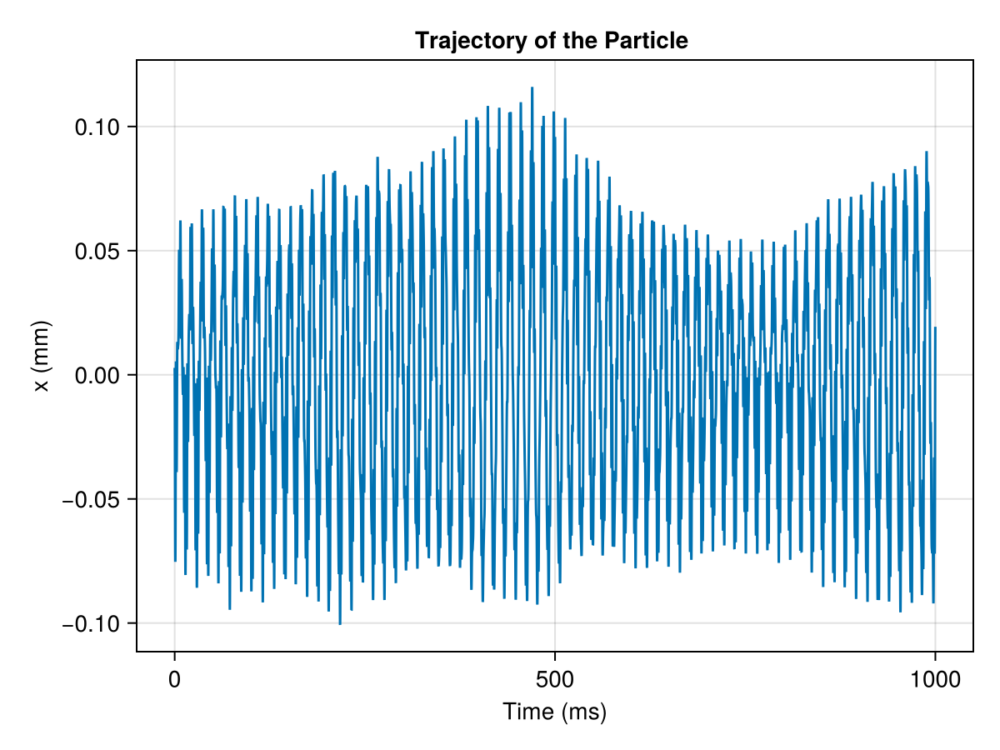

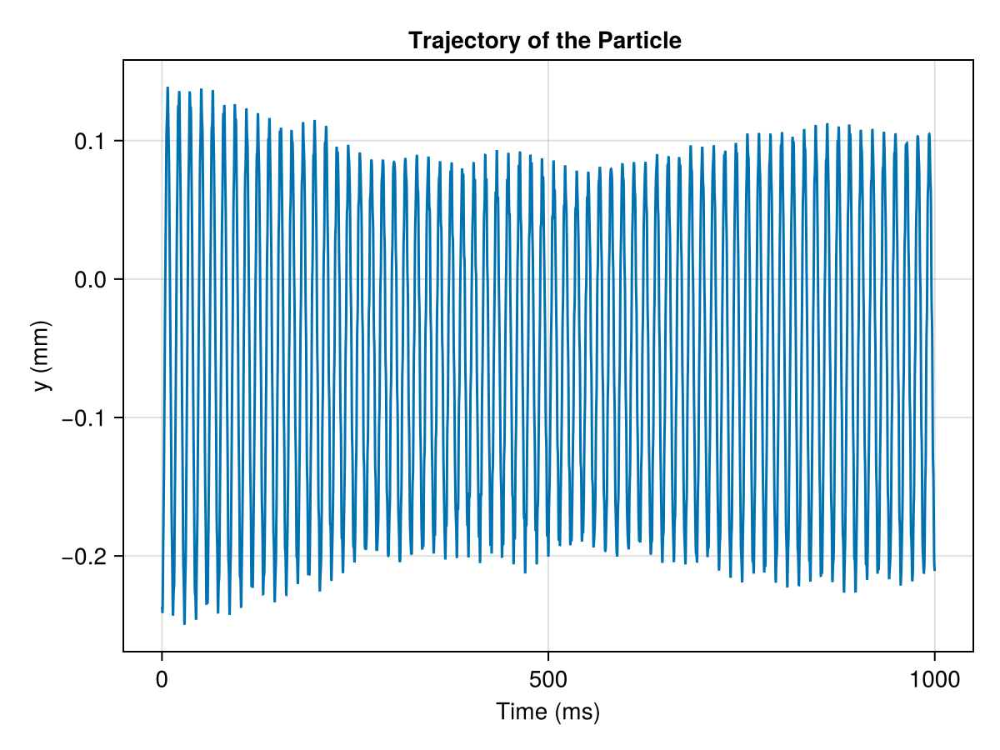

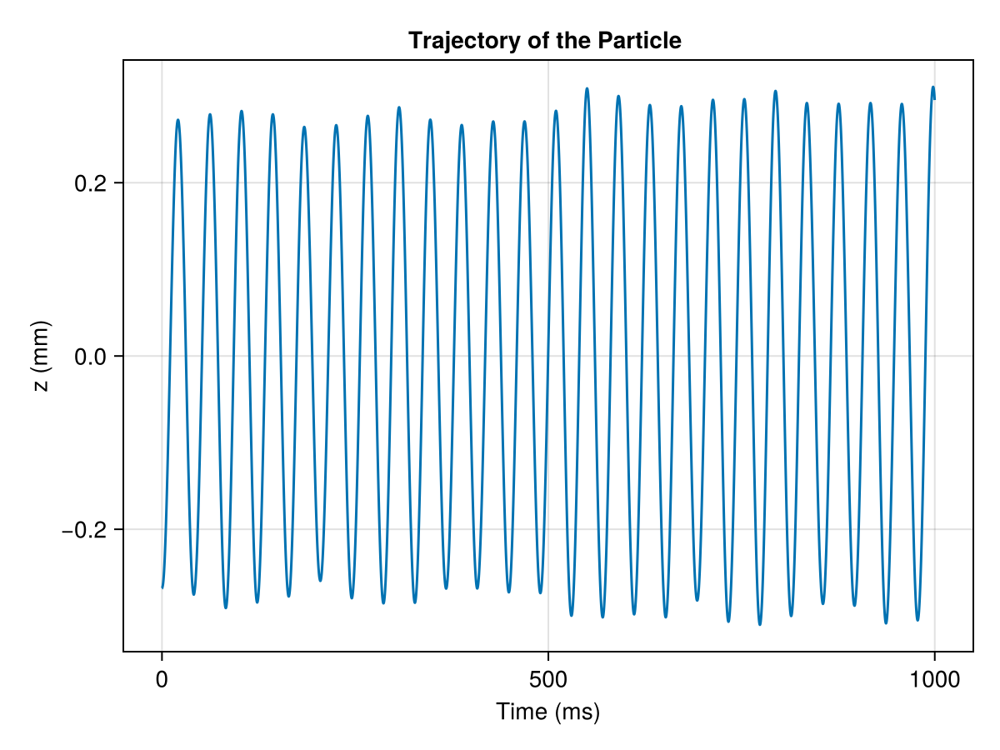

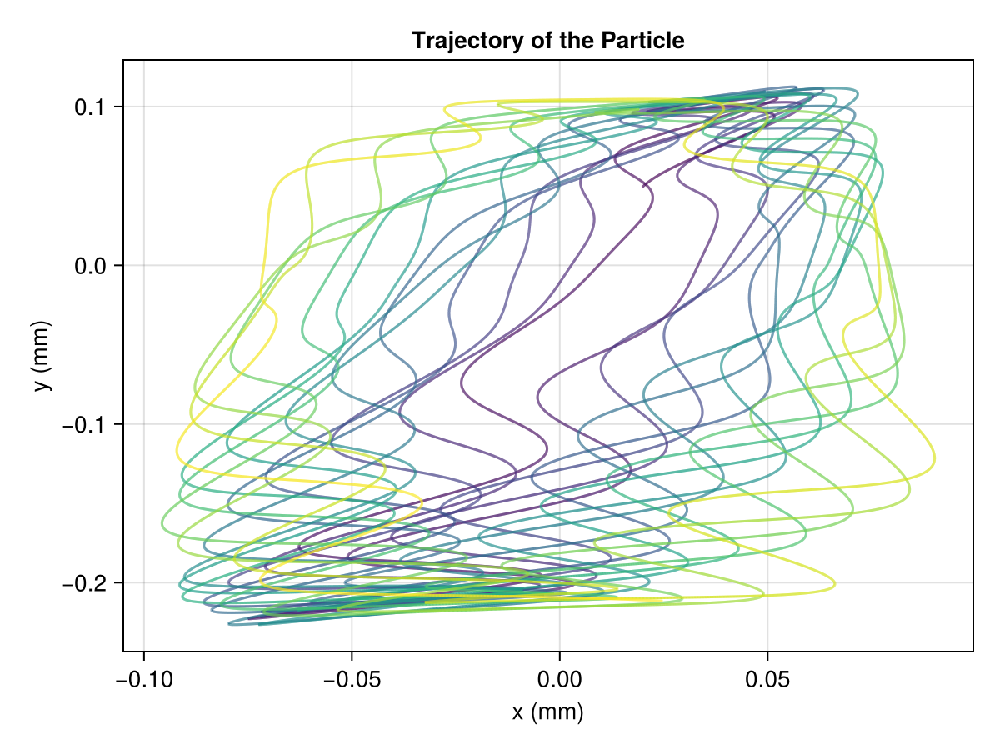

In [365]:
plot3dTraj(r_t; step=100, r₀=r₀, showTrap=true, trap_path="trap_v1.1.stl");
plot1dTraj(r_t[:,1], ts; step=100, dim="x");
plot1dTraj(r_t[:,2], ts; step=100, dim="y");
plot1dTraj(r_t[:,3], ts; step=100, dim="z");
plot2dTraj(r_t[end-n_t÷5:end,:], ts[end-n_t÷5:end], (1, 2); step=1, dimx="x", dimy="y");

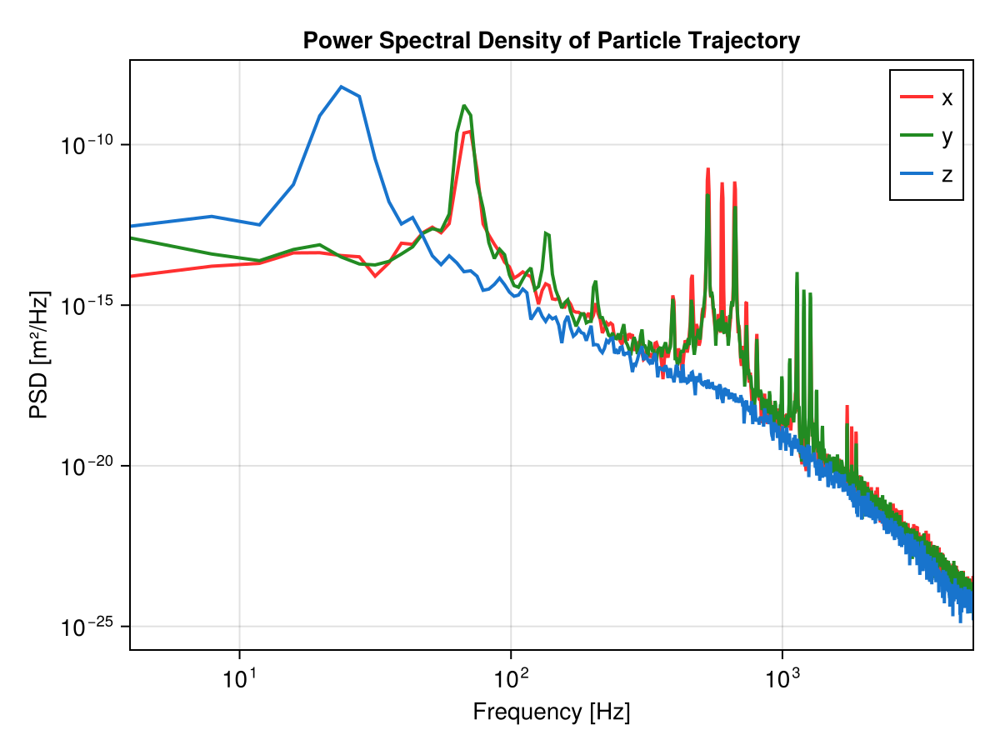

Δf = 1.000 Hz | N_total = 10102 | N_used = 10102 | método = welch


GLMakie.Screen(...)

In [366]:
freqs, psds = getPSD(r_t, Δt; fs_obj=10e3, winlen=n_t÷5)
fig, ax = plotPSD(freqs, psds; step=1)
display(GLMakie.Screen(), fig.scene)

In [ ]:
# Export trajectory data to CSV
trajectory_df = DataFrame(
    time = ts,
    x = r_t[:, 1],
    y = r_t[:, 2], 
    z = r_t[:, 3]
)

CSV.write("trajectory.csv", trajectory_df)

In [163]:
KE_avg = 1/2 * M * mean(sum(v_t.^2, dims=2))
theoretical_KE = 3/2 * k_b * T

KE_avg, theoretical_KE

(1.8920611332023002e-16, 5.654204999999999e-21)

## Micro + Secular motion (approx)

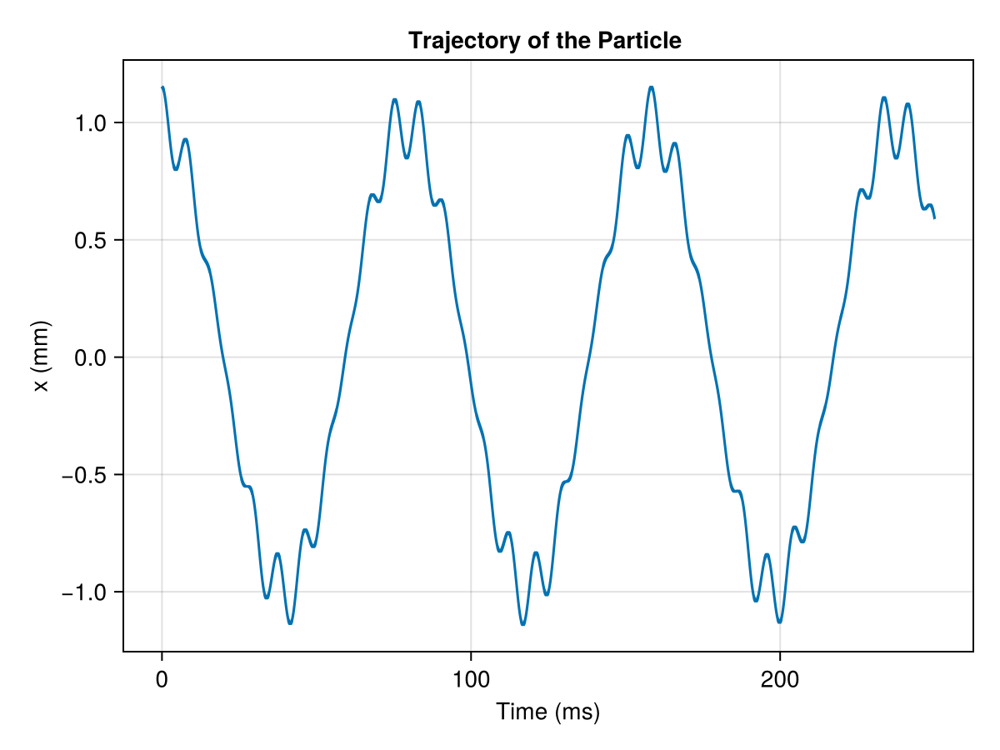

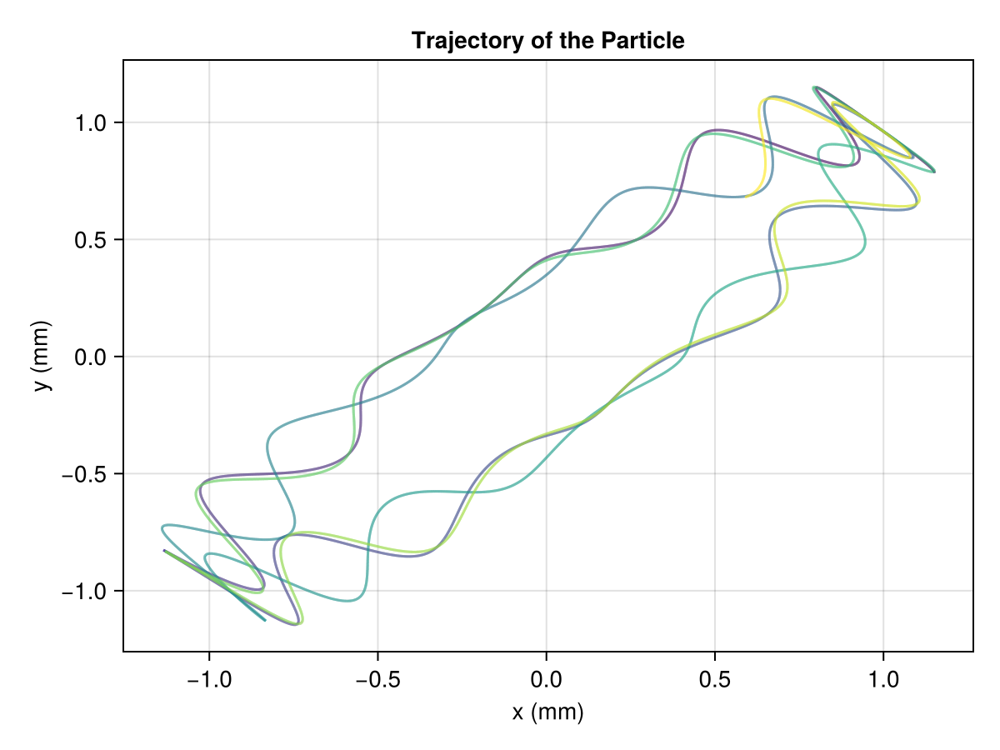

In [65]:
x₀ = 1e-3
y₀ = 1e-3
z₀ = 1e-3
ϕ_x = 0
ϕ_y = pi/8
ϕ_z = 0

x(t) = x₀*cos(ω_x*t-ϕ_x)*(1-q_x/2*cos(Ω*t))
y(t) = y₀*cos(ω_y*t-ϕ_y)*(1-q_y/2*cos(Ω*t))
z(t) = z₀*cos(ω_z*t-ϕ_z)

nt = 1000000
ts = LinRange(0, 250e-3, nt)
rt = zeros(nt, 3)

rt[:, 1] = [x(t) for t in ts]
rt[:, 2] = [y(t) for t in ts]
rt[:, 3] = [z(t) for t in ts]

plot1dTraj(rt[:,1], ts; step=1, dim="x");
plot2dTraj(rt[:, 1:2], ts; step=10, dimx="x", dimy="y");
plot3dTraj(rt; step=10, r₀=r₀, showTrap=true, r_0=r_0, r_e=r_e);

## Z Oscillation Data Analysis

### Import E field from driving endcap

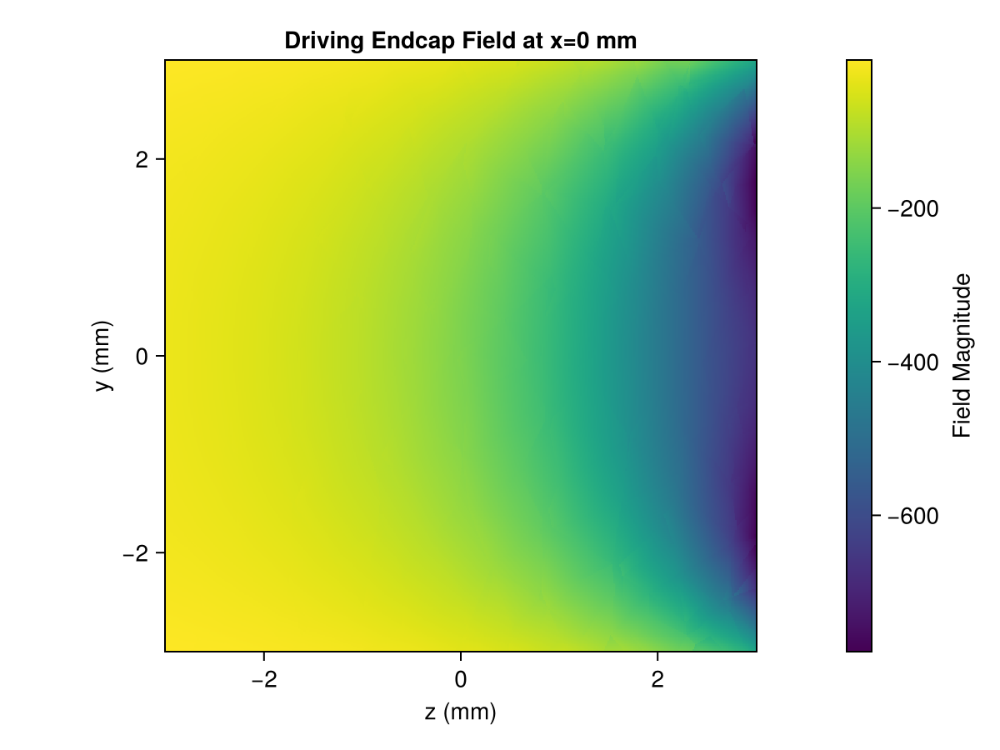

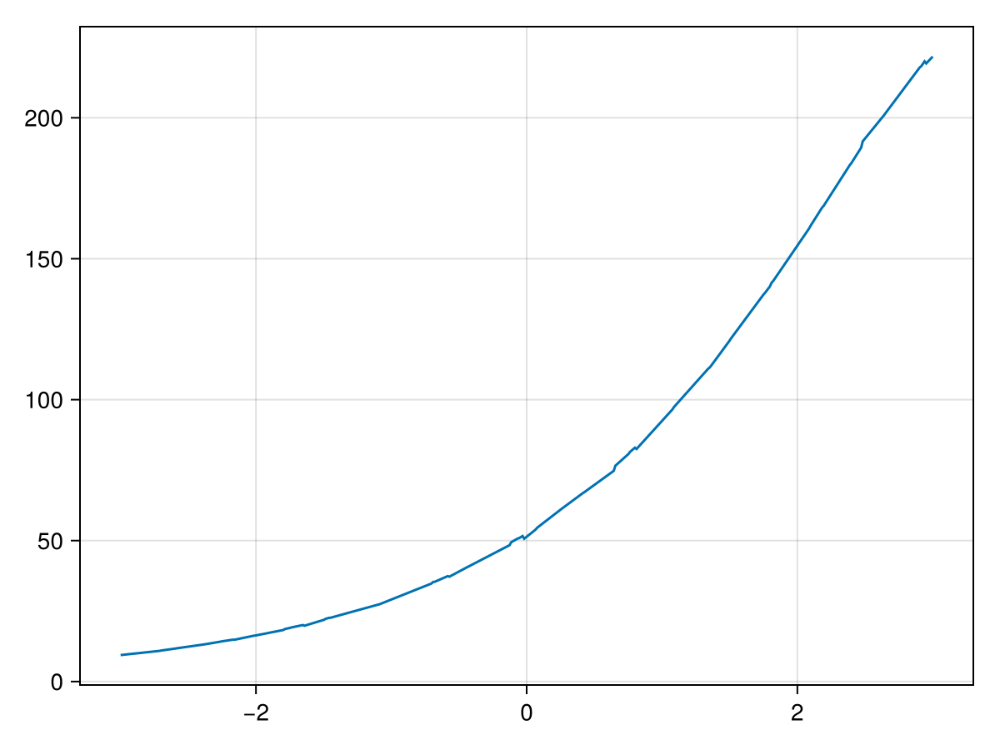

In [11]:
E_drive = abs.(Ez_EC1_grid[iˣ(0), iʸ(0), :]);
plotFieldSlice(xs, zs, V_EC2_p*Ez_EC1_grid[iˣ(0),:,:]; 
    title="Driving Endcap Field at x=0 mm", xlabel="z (mm)", ylabel="y (mm)");
lines(zs.*1e3, E_drive)

### Exp1

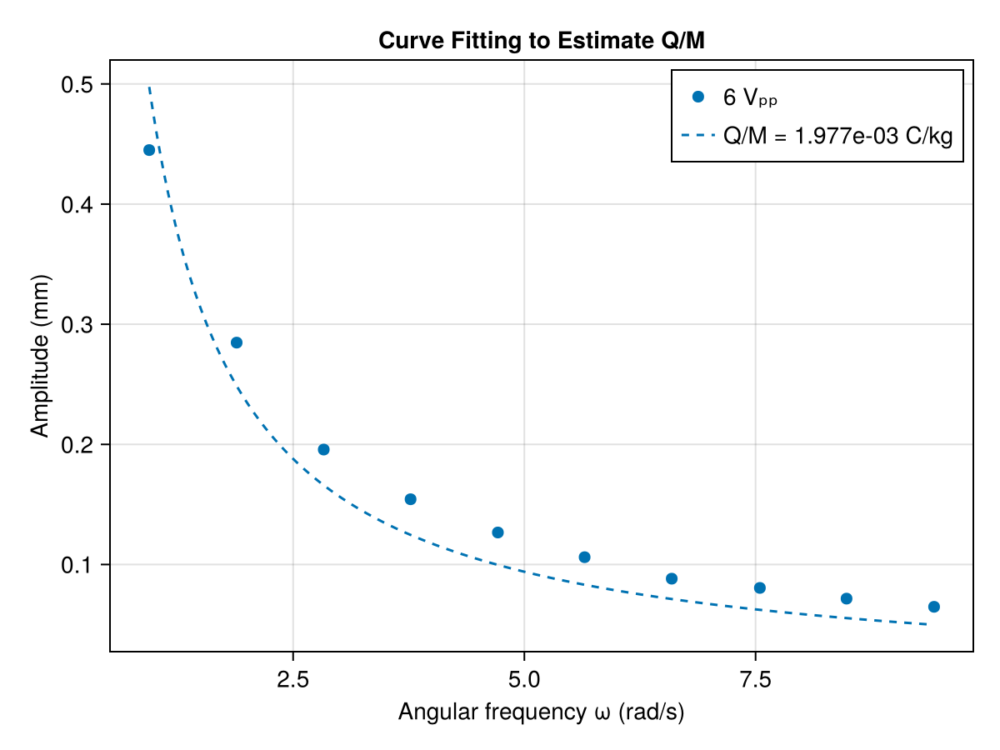

means = [-0.00014451128454710905, 0.000272909791782581, 8.578297244456906e-5, 0.00020186404445646277, -0.00013686872430081413, 1.989719922615388e-5, 6.747128308538229e-5, 3.354006417521505e-6, 0.0008582686155435404, 1.357483022264126e-6]
mean(means) = 0.0001229525387130552
iᶻ(mean(means)) = 260
E = 167.75937263928026
(Q╱M_est / 1.60217663e-19) * M = 88966.7213436865


88966.7213436865

In [428]:
# w(n, N) = 0.5 .- 0.5.*cos.(2π*n/(N-1)); # Hanning window
a₀ = 0.21557895;  a₁ = 0.41663158; a₂ = 0.277263158; 
a₃ = 0.083578947; a₄ = 0.006947368
w(n, N) = a₀ .- a₁.*cos.(2π*n/N) .+ a₂.*cos.(4π*n/N) .- a₃.*cos.(6π*n/N) .+ a₄.*cos.(8π*n/N) # Flattop window
Nₘ = 10; freqs, amps, means = processZOscData(150, 150, Nₘ; path="exp1/", post_filename="_mHz", show_fft=true, show_traj=true, mov_mean=true, returnFigures=true, window=w); 
E = V_EC2_p*E_drive[iᶻ(mean(means))]; @show(means, mean(means), iᶻ(mean(means)), E)

iₚₖ = [argmax(amp) for amp in amps]
ωs, As = 2π.*[freqs[i][iₚₖ[i]] for i in 1:Nₘ], [amps[i][iₚₖ[i]] for i in 1:Nₘ]
Q╱M_est, fig, ax = getEstimatedQ╱M(ωs, As, E, R, ρ, ηᵥ, V_EC2_p, [3.5e-3])
# lines(0:99, w(0:99,100)) # Window plot
@show Q╱M_est/(1.60217663e-19)*M

### Exp3

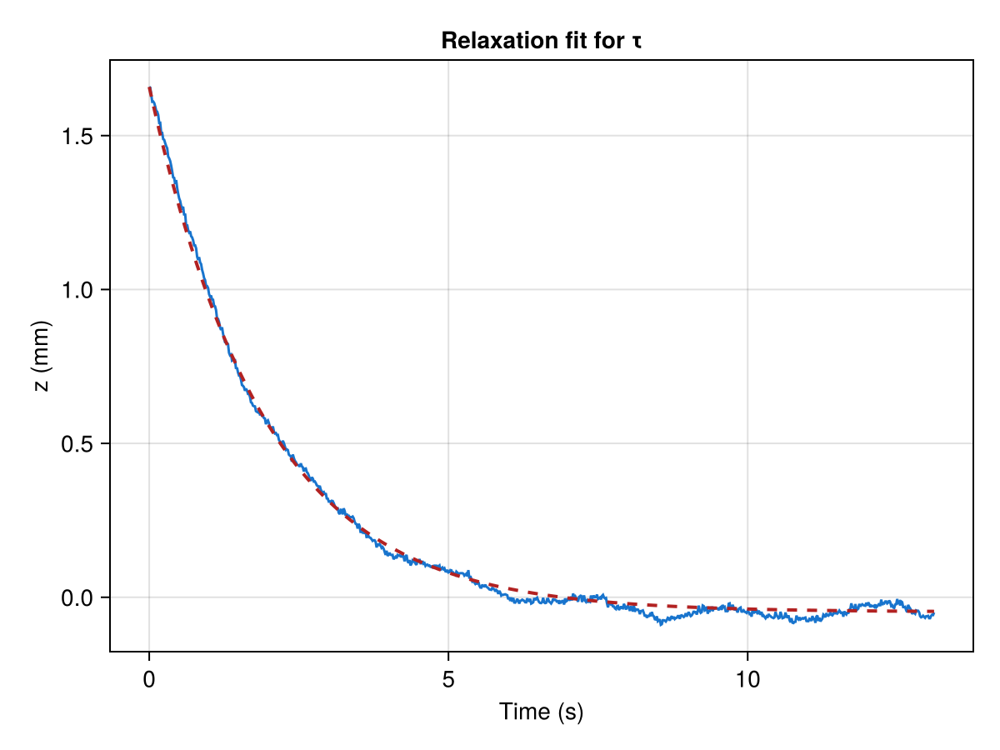

time range: [0, 13.114559999999999] s, initial z: 1.6582840000000003 mmω_z = 25.311950681792407
sqrt((γ / M) / τ_est3) = 19.086337036709267
(Ω / 2) * sqrt(((a_z * M) / Q) * Q╱M_est) = 20.455681086380537
τ_est3 = 1.9279765263217559



In [495]:
# τ_est1, fig, ax = getEstimatedτ("../analysis/exp3/eq_1.txt"; t_min=14.765, offset=4.3e-3);
# @show ω_z sqrt(γ/M/τ_est1) Ω/2*sqrt(a_z*M/Q*Q╱M_est) τ_est1; println()
# τ_est2, fig, ax = getEstimatedτ("../analysis/exp3/eq_2.txt"; t_min=11.948, offset=4.3e-3);
# @show ω_z sqrt(γ/M/τ_est2) Ω/2*sqrt(a_z*M/Q*Q╱M_est) τ_est2; println()
τ_est3, fig, ax = getEstimatedτ("../analysis/exp3/eq_3.txt"; t_min=12.42, offset=4.3e-3);
@show ω_z sqrt(γ/M/τ_est3) Ω/2*sqrt(a_z*M/Q*Q╱M_est) τ_est3; 
println()
# τ_est = mean([τ_est1, τ_est2])
# @show ω_z sqrt(γ/M/τ_est) Ω/2*sqrt(a_z*M/Q*Q╱M_est) τ_est;

### Exp2

In [ ]:
freqs, amps, means = processZOscData(150, 150, Nₘ; path="exp2/", filename="4_", offset = 9.6e-3 / 2, show_fft=true, show_traj=true, mov_mean=true, window=w, k=2); 

┌ Warning: Found 1 missing lines in ../analysis/exp2/5_300.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:207
┌ Warning: Found 5 missing lines in ../analysis/exp2/5_450.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:207
┌ Warning: Found 6 missing lines in ../analysis/exp2/5_600.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:207
┌ Warning: Found 11 missing lines in ../analysis/exp2/5_1050.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:207
┌ Warning: Found 1 missing lines in ../analysis/exp2/5_1200.txt. Filled by linear interpolation.
└ @ Main 

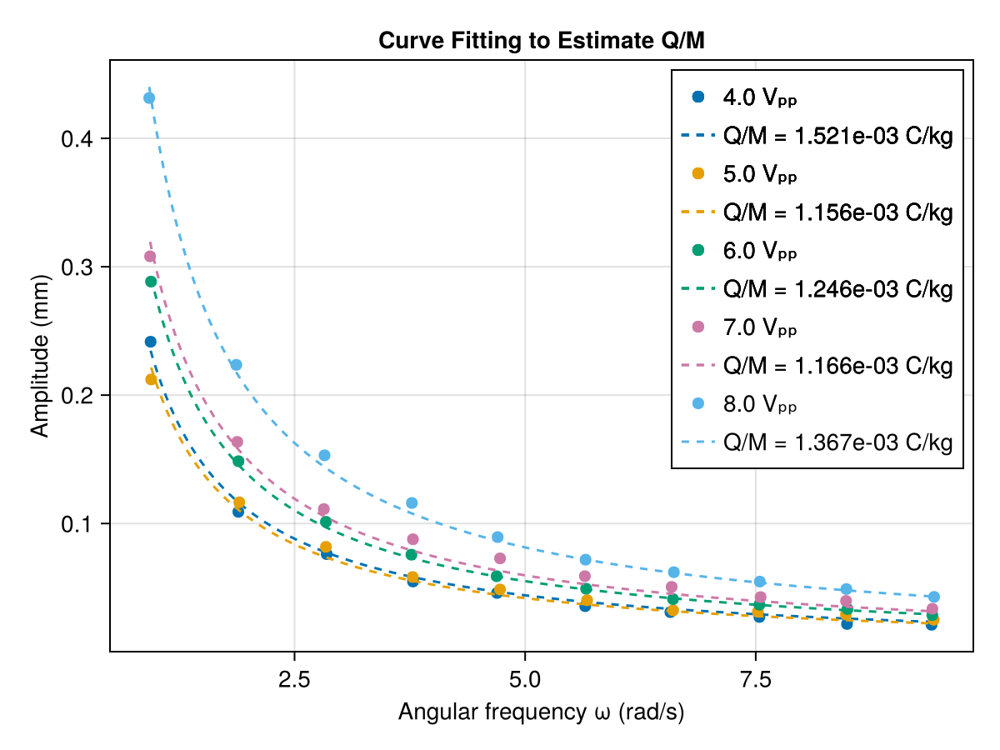

Q╱M_est = mean(Q╱Ms) = 0.0012911659758749624
(Q╱M_est / 1.60217663e-19) * M = 58103.76078409065


58103.76078409065

In [500]:
a₀ = 0.21557895;  a₁ = 0.41663158; a₂ = 0.277263158; 
a₃ = 0.083578947; a₄ = 0.006947368
w(n, N) = a₀ .- a₁.*cos.(2π*n/N) .+ a₂.*cos.(4π*n/N) .- a₃.*cos.(6π*n/N) .+ a₄.*cos.(8π*n/N) # Flattop window

Q╱Ms = Array{Float64}(undef, 5)
Vpps = [4, 5, 6, 7, 8]

Nₘ = 10; freqs, amps, means = processZOscData(150, 150, Nₘ; path="exp2/", filename="$(Vpps[1])_", offset = 9.6e-3 / 2, show_fft=false, show_traj=false, mov_mean=true, window=w, k=2); 
E = Vpps[1]/2*E_drive[iᶻ(mean(means))]; #@show(means, mean(means), iᶻ(mean(means)), E)

iₚₖ = [argmax(amp) for amp in amps]
ωs, As = 2π.*[freqs[i][iₚₖ[i]] for i in 1:Nₘ], [amps[i][iₚₖ[i]] for i in 1:Nₘ]
Q╱M_est, fig, ax = getEstimatedQ╱M(ωs, As, E, R, ρ, ηᵥ, Vpps[1]/2, [3.5e-3]; show_plot=false)

Q╱Ms[1] = Q╱M_est
for i in 2:5
    freqs, amps, means = processZOscData(150, 150, Nₘ; path="exp2/", filename="$(Vpps[i])_", offset = 9.6e-3 / 2, mov_mean=true, window=w, k=2); 
    # @show(means, mean(means), iᶻ(mean(means)), E)
    E = Vpps[i]/2*E_drive[iᶻ(mean(means))]

    iₚₖ = [argmax(amp) for amp in amps]
    ωs, As = 2π.*[freqs[i][iₚₖ[i]] for i in 1:Nₘ], [amps[i][iₚₖ[i]] for i in 1:Nₘ]
    Q╱M_est, fig, ax = getEstimatedQ╱M(ωs, As, E, R, ρ, ηᵥ, Vpps[i]/2, [3.5e-3]; hold=true, fig=fig, ax=ax, show_plot=false)

    Q╱Ms[i] = Q╱M_est
end

display(fig); display(GLMakie.Screen(), fig.scene)
@show Q╱M_est=mean(Q╱Ms)
@show Q╱M_est/(1.60217663e-19)*M

In [ ]:
58103.76078409065

# Tests

## FFT

In [ ]:
function getFFT(ts, rs; N = nothing, fs_obj = nothing, show_details=false, window=w(n,N)=1.0.+0.0.*n*N)   
    Δt = (ts[2] - ts[1])
    fs_real = 1/Δt

    if fs_obj === nothing
        fs_obj = fs_real
    elseif fs_obj > fs_real
        @warn "fs_obj ($fs_obj Hz) > fs_real ($fs_real Hz). Using fs_real instead."
        fs_obj = fs_real
    end
    
    step = floor(Int, fs_real / fs_obj)
    fs = fs_real / step

    rs = rs[1:step:end]
    n_available = size(rs, 1)
    
    if N === nothing
        N = n_available
    elseif N > n_available
        @warn "Window ($N) > available points ($n_available). Using $n_available"
        N = n_available
    end

    w = window(0:N-1, N)
    CG = sum(w) / N  # coherent gain
    r_fft = fft(w .* rs[end-N+1:end])
    freqs = (0:div(N,2))*(fs/N)
    amps  = abs.(r_fft[1:div(N,2)+1]).*2/N ./ CG
    if show_details
        println("fs_real = $fs_real Hz (Nyquist = $(fs_real/2) Hz)")
        println("fs_effective = $fs Hz (Nyquist = $(fs/2) Hz)")
        println("window = $N points")
        println("freq. resolution = $(fs/N) Hz")
    end
    return freqs, amps
end

sadad(0:9, 1) = StepRangeLen(1.0, 0.0, 10)


StepRangeLen(1.0, 0.0, 10)

### test 1

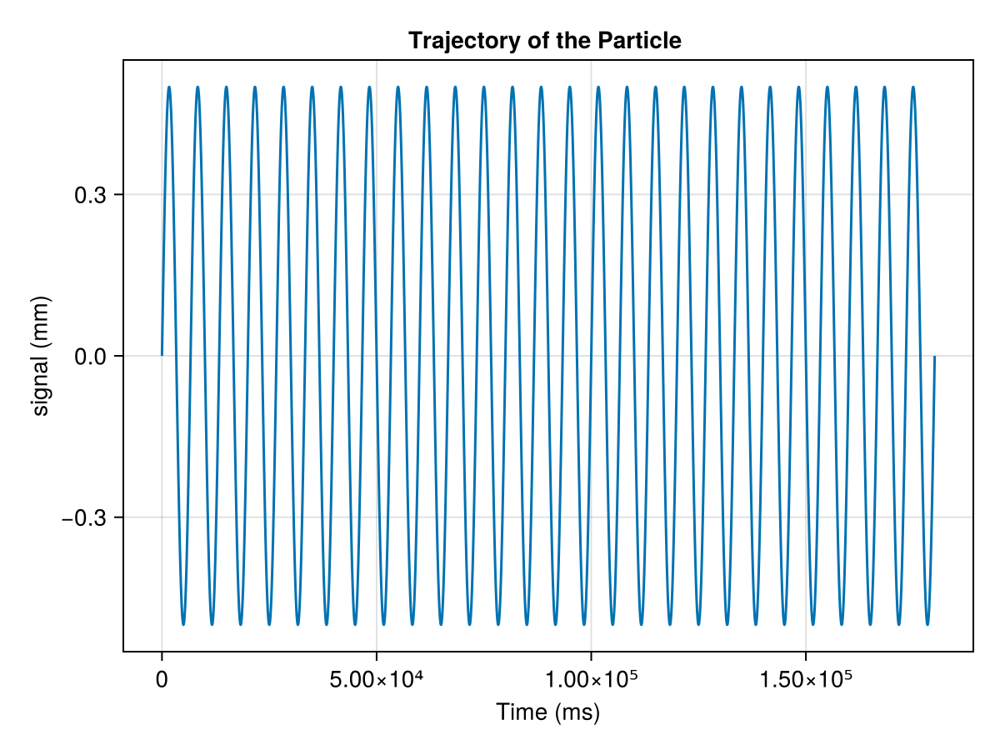

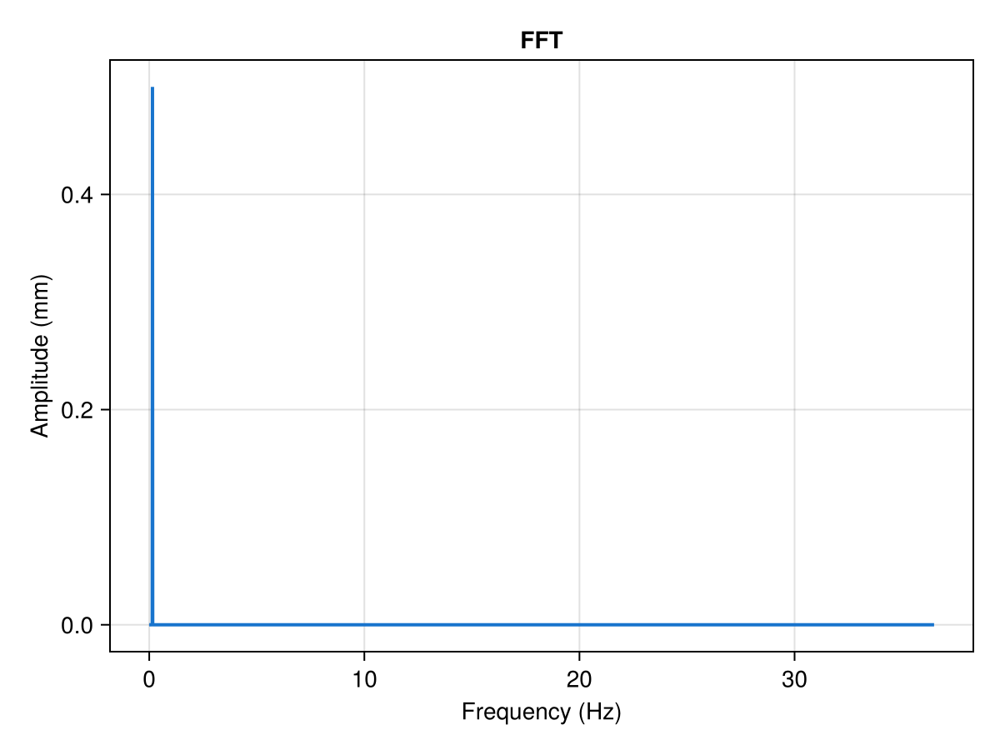

Float64[]

In [111]:
ts = LinRange(0.0, 180, 13136)
signal = 0.5e-3*sin.(2π*(0.15)*ts)
fs_obj = 2.5 * (2 * 30)
plot1dTraj(signal, ts; step=1, dim="signal")
freqs, amps = getFFT(ts, signal)
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
peaks = findall(x -> x .> 0.1, amps)
display(freqs[peaks])

### test 2

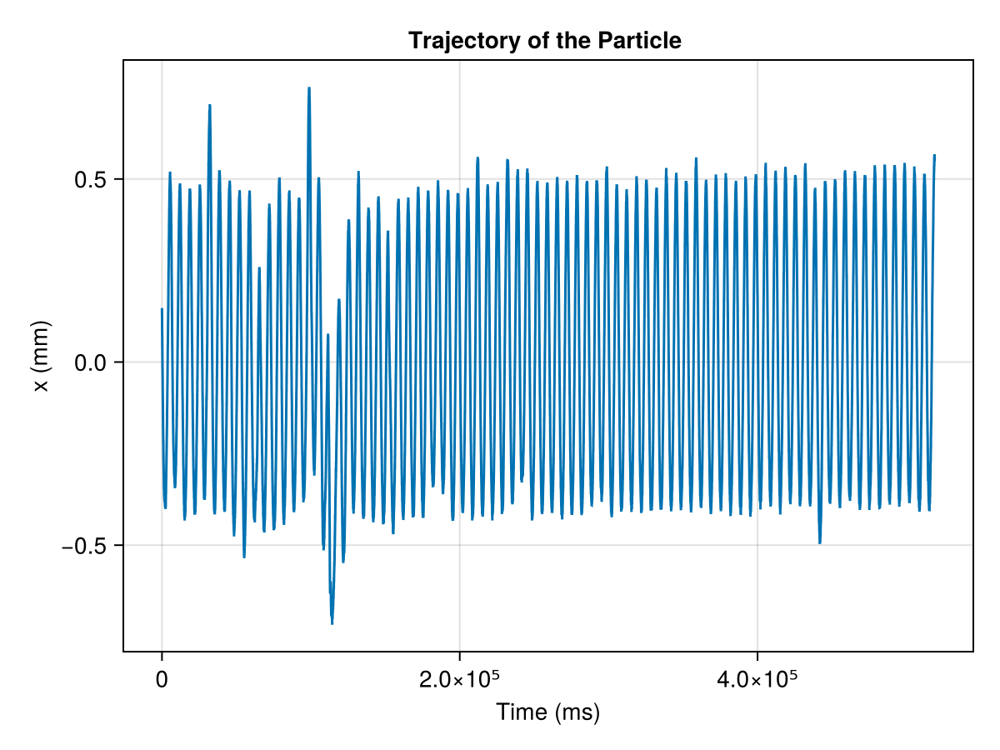

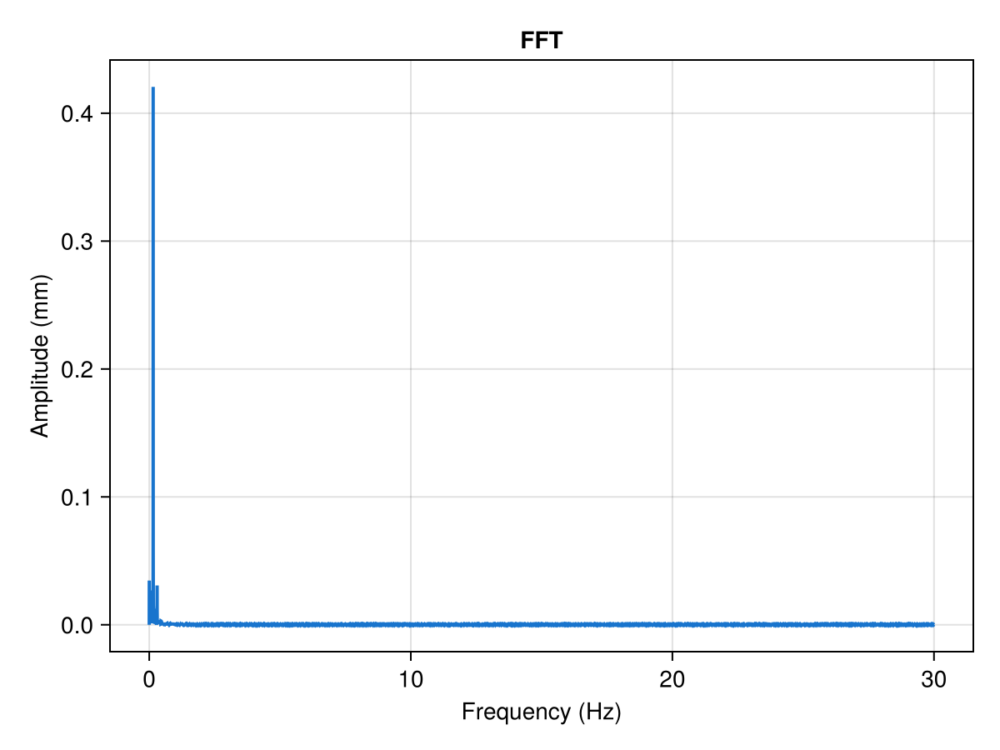

fs_real = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
fs_effective = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
window = 31145 points
freq. resolution = 0.001926788171653889 Hz


(0.15028947738900333, 0.00042059965647022905)

In [207]:
ts, rs = importTrackerData("../analysis/150_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[3], amps_[3] = freqs[argmax(amps)], maximum(amps)

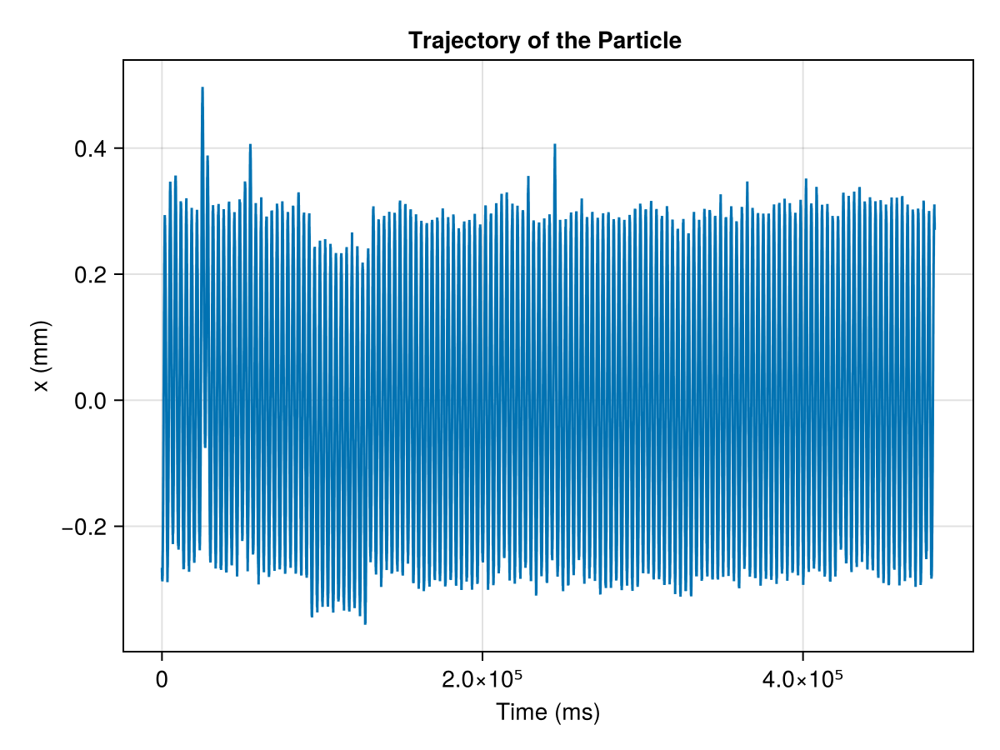

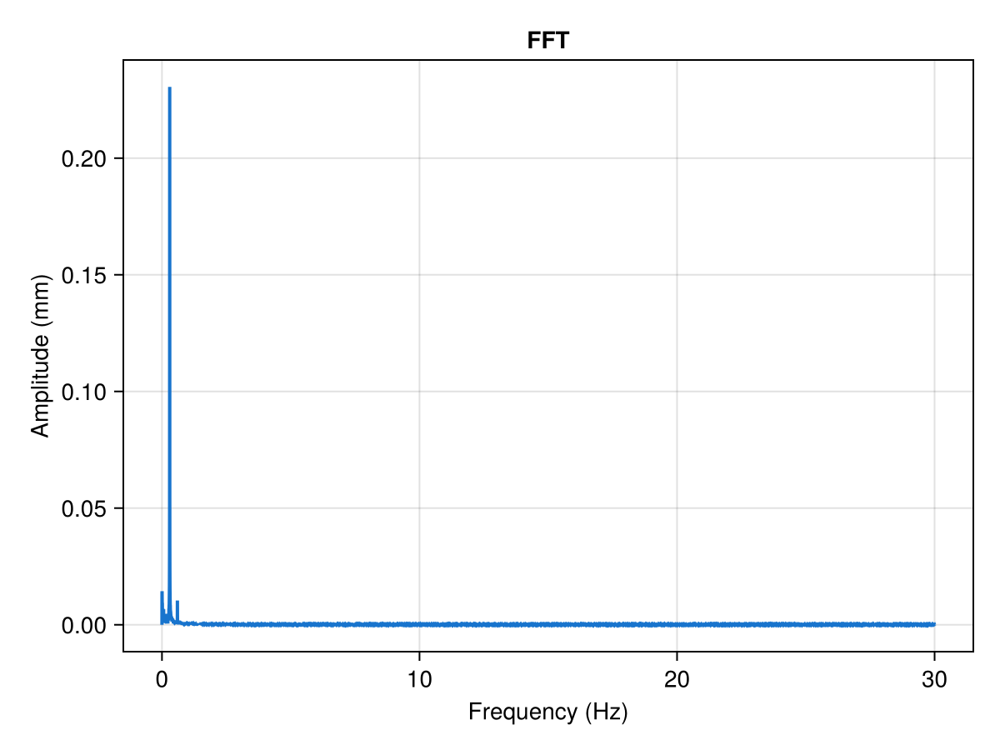

fs_real = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
fs_effective = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
window = 28935 points
freq. resolution = 0.002073952569765349 Hz


(0.3007231226159756, 0.0002305409623490211)

In [181]:
ts, rs = importTrackerData("../analysis/300_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[3], amps_[3] = freqs[argmax(amps)], maximum(amps)

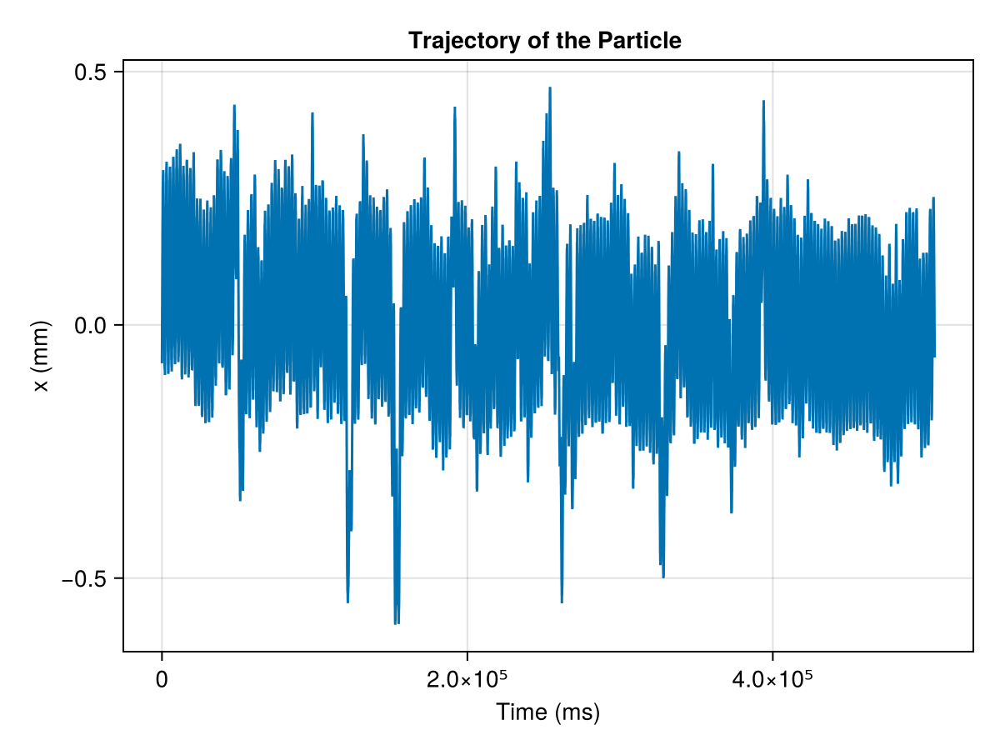

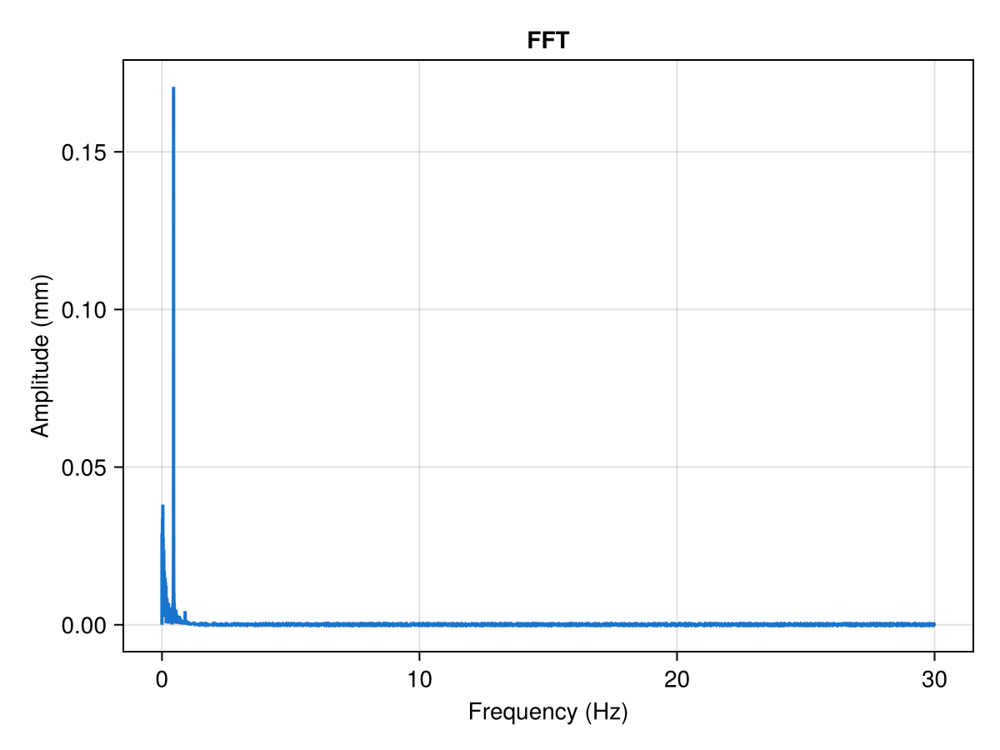

fs_real = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
fs_effective = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
window = 30366 points
freq. resolution = 0.001976217401243508 Hz


(0.45057756748351985, 0.00017059699212551652)

In [121]:
ts, rs = importTrackerData("../analysis/450_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[3], amps_[3] = freqs[argmax(amps)], maximum(amps)

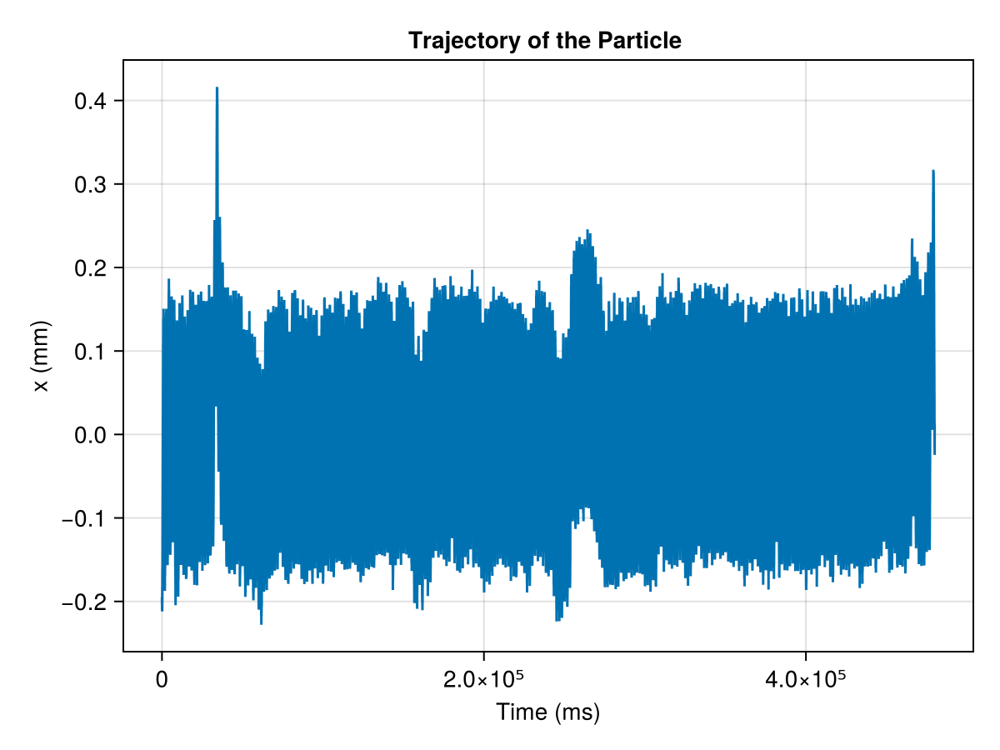

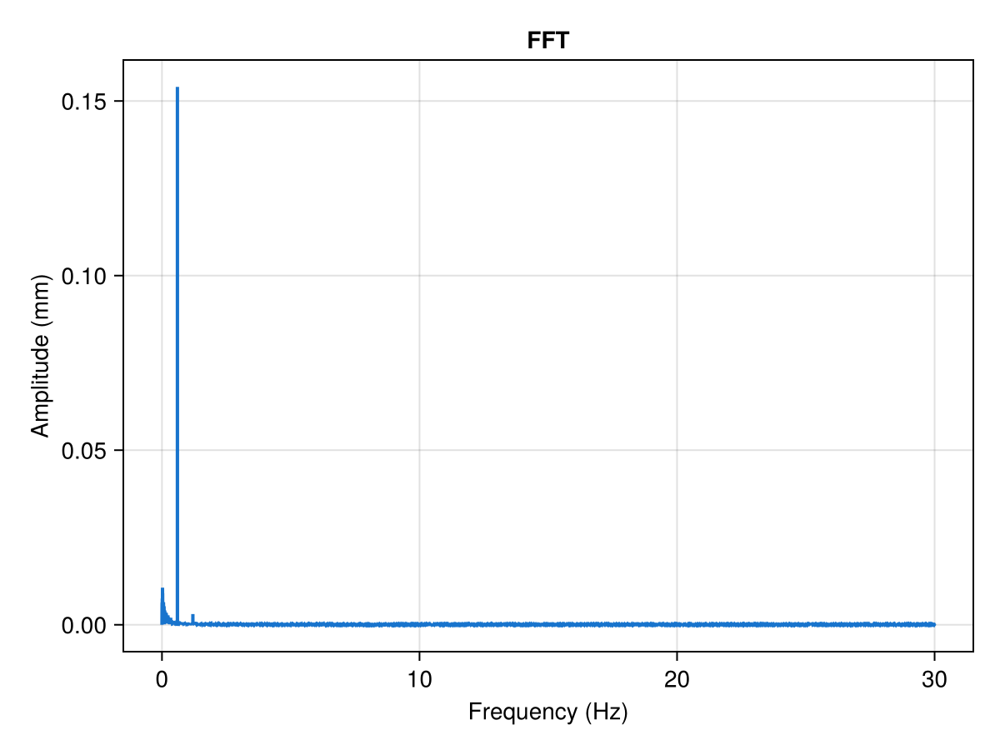

fs_real = 60.00927743429134 Hz (Nyquist = 30.00463871714567 Hz)
fs_effective = 60.00927743429134 Hz (Nyquist = 30.00463871714567 Hz)
window = 28805 points
freq. resolution = 0.0020832937835199216 Hz


(0.5999886096537375, 0.00015404238835581266)

In [122]:
ts, rs = importTrackerData("../analysis/600_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[4], amps_[4] = freqs[argmax(amps)], maximum(amps)

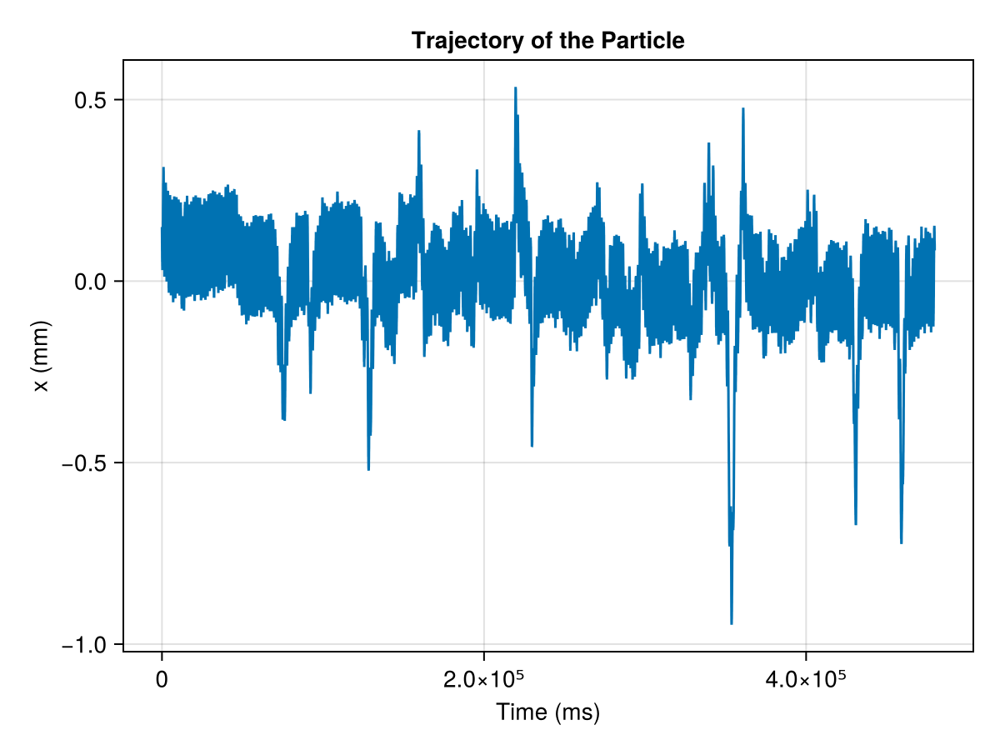

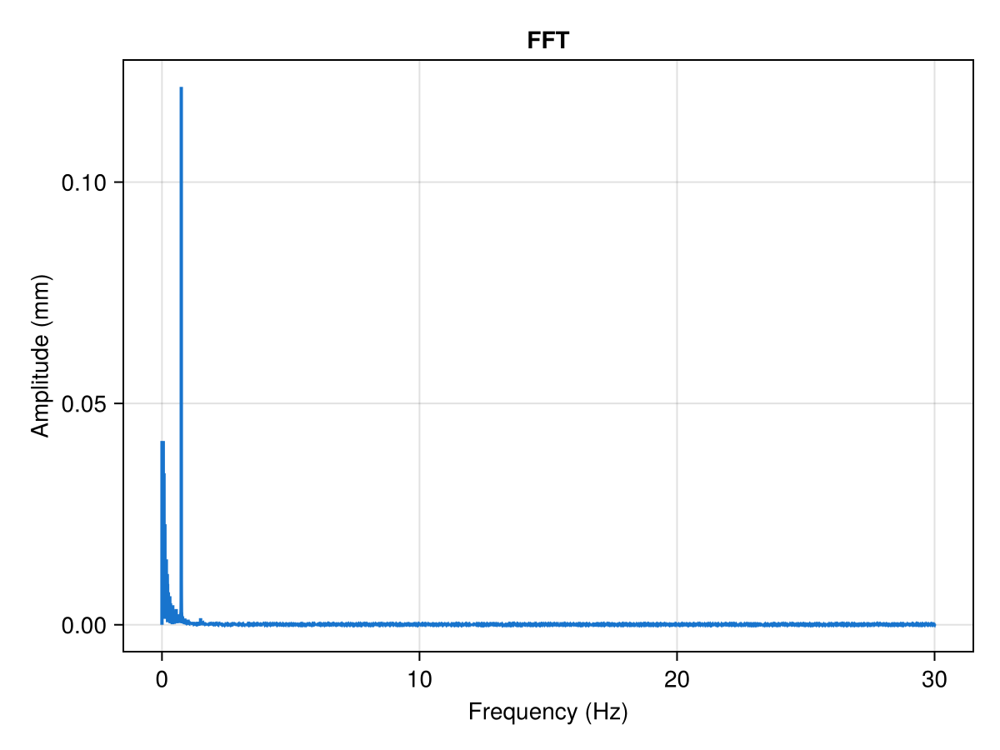

fs_real = 60.00927743429134 Hz (Nyquist = 30.00463871714567 Hz)
fs_effective = 60.00927743429134 Hz (Nyquist = 30.00463871714567 Hz)
window = 28796 points
freq. resolution = 0.0020839449032605687 Hz


(0.7502201651738047, 0.00012151801771629936)

In [80]:
ts, rs = importTrackerData("../analysis/750_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[5], amps_[5] = freqs[argmax(amps)], maximum(amps)

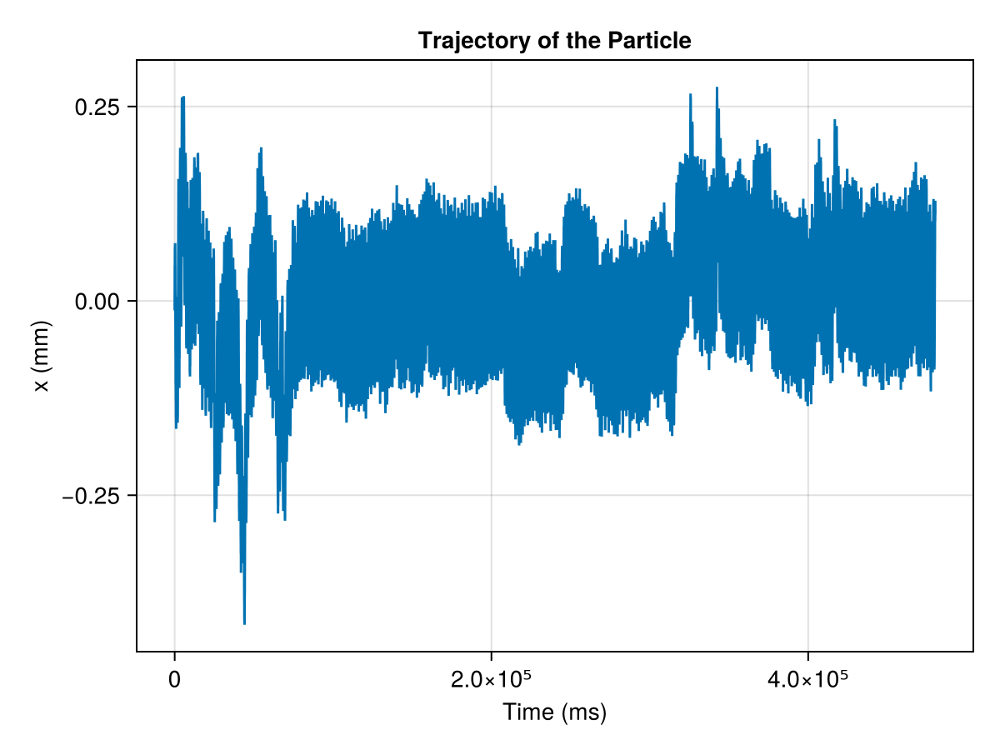

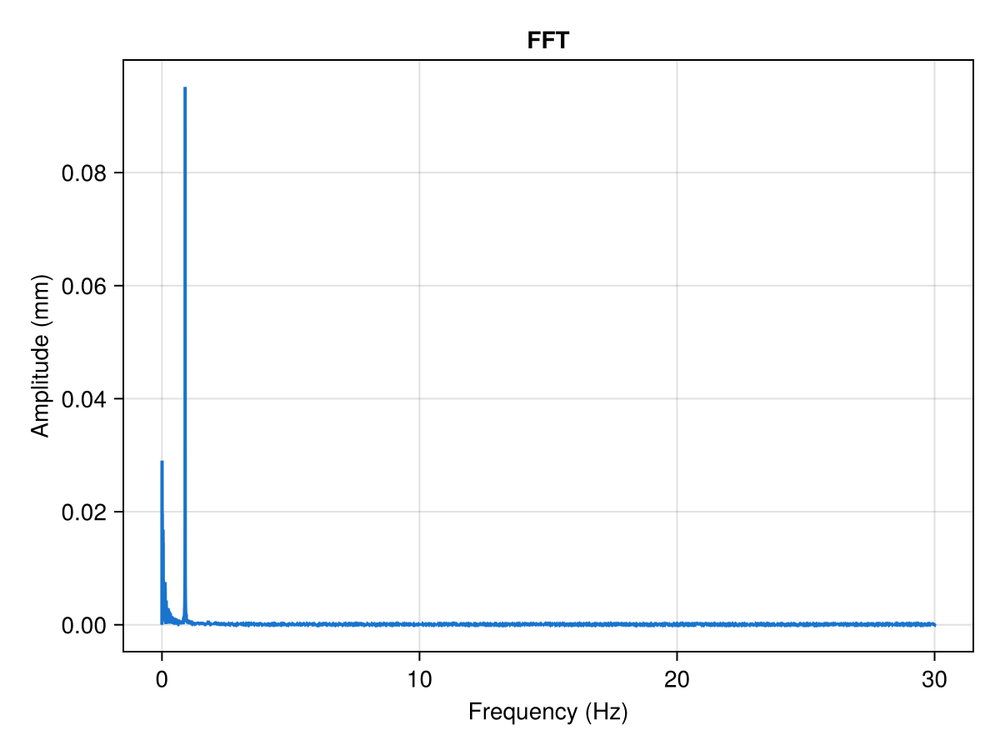

fs_real = 60.00927743429134 Hz (Nyquist = 30.00463871714567 Hz)
fs_effective = 60.00927743429134 Hz (Nyquist = 30.00463871714567 Hz)
window = 28821 points
freq. resolution = 0.0020821372413965976 Hz


(0.8994832882833301, 9.516501492172663e-5)

In [81]:
ts, rs = importTrackerData("../analysis/900_mHz.txt"); rs = rs .- mean(rs);
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[6], amps_[6] = freqs[argmax(amps)], maximum(amps)

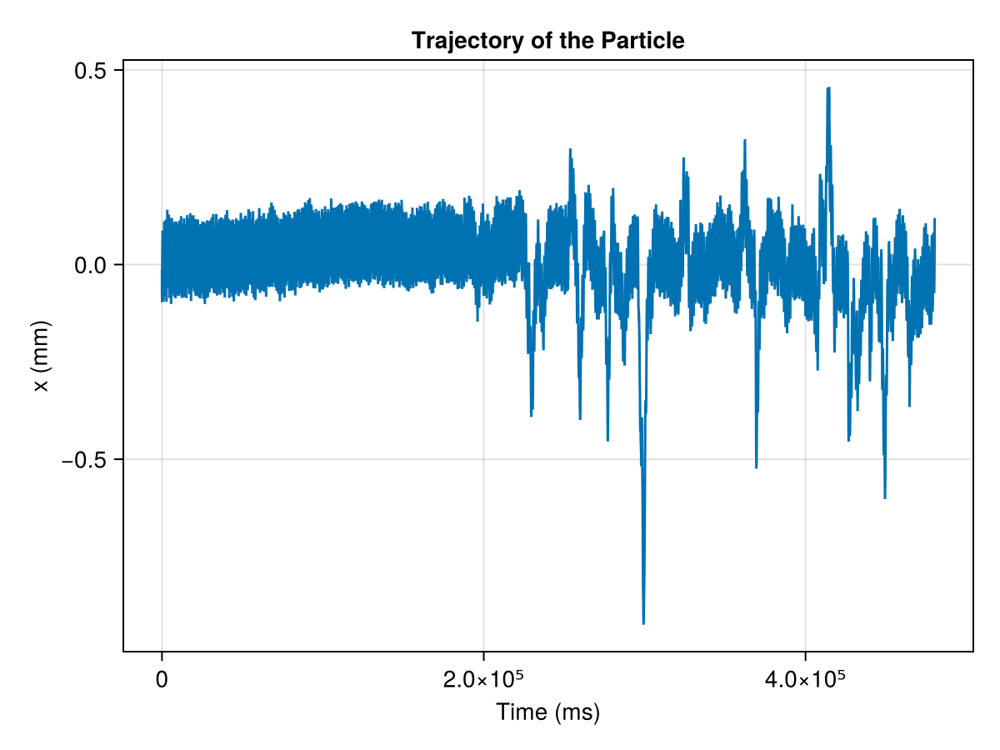

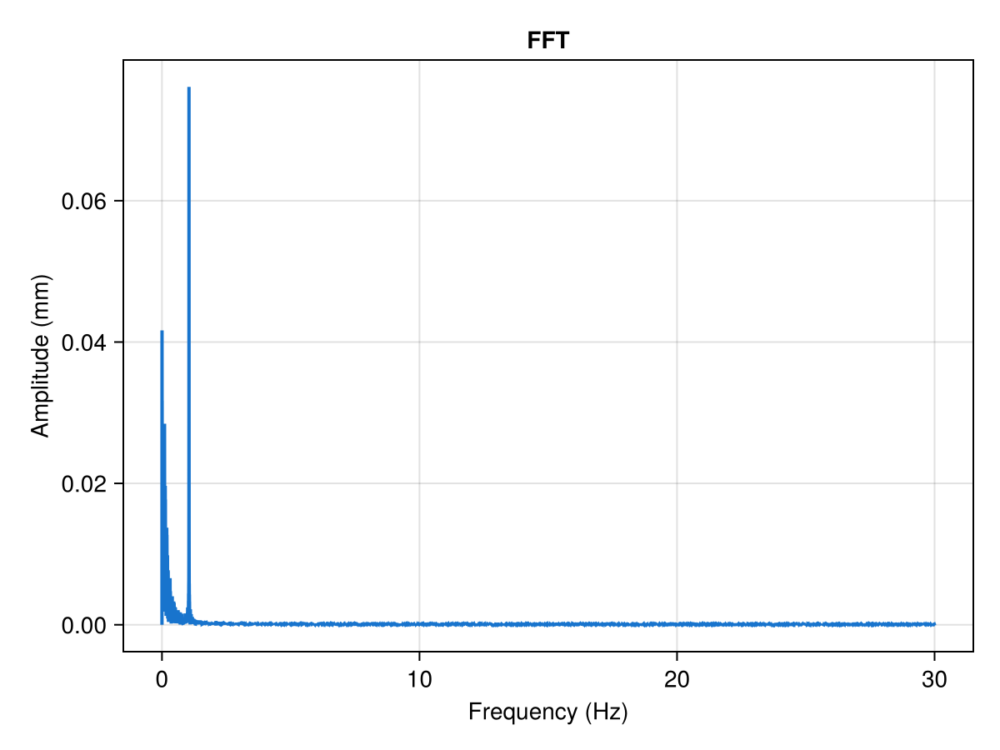

fs_real = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
fs_effective = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
window = 28822 points
freq. resolution = 0.002082083741800027 Hz


(1.0493702058672136, 7.610162789597306e-5)

In [82]:
ts, rs = importTrackerData("../analysis/1050_mHz.txt"); rs = rs .- mean(rs);
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[7], amps_[7] = freqs[argmax(amps)], maximum(amps)

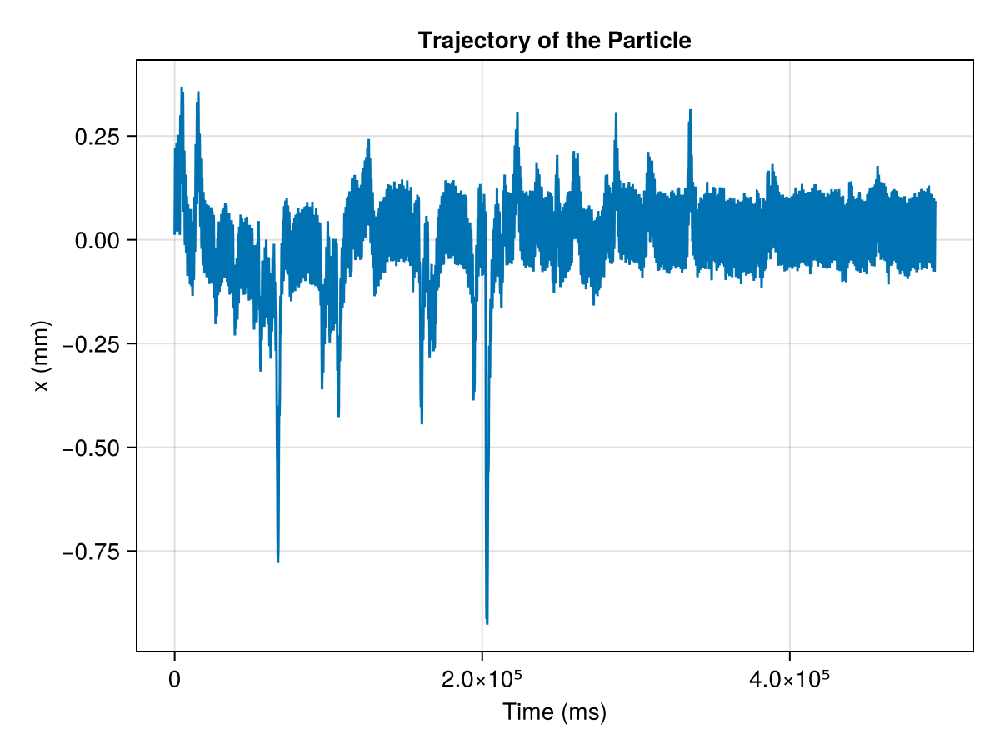

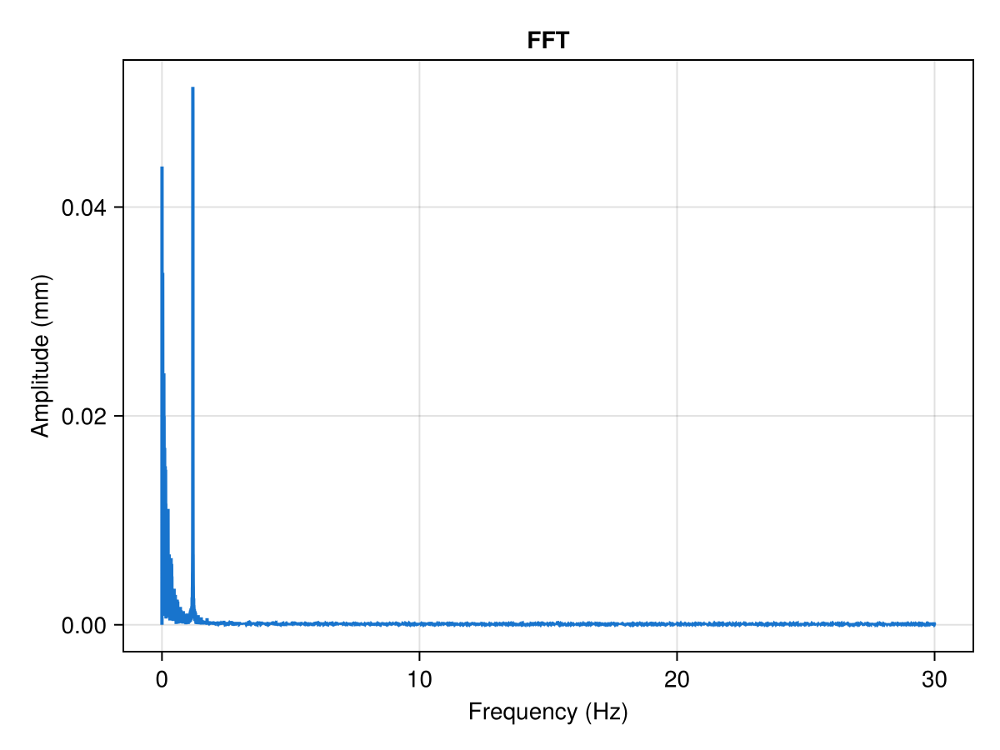

fs_real = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
fs_effective = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
window = 29679 points
freq. resolution = 0.002021962249609501 Hz


(1.199023614018434, 5.150676647518649e-5)

In [83]:
ts, rs = importTrackerData("../analysis/1200_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[8], amps_[8] = freqs[argmax(amps)], maximum(amps)

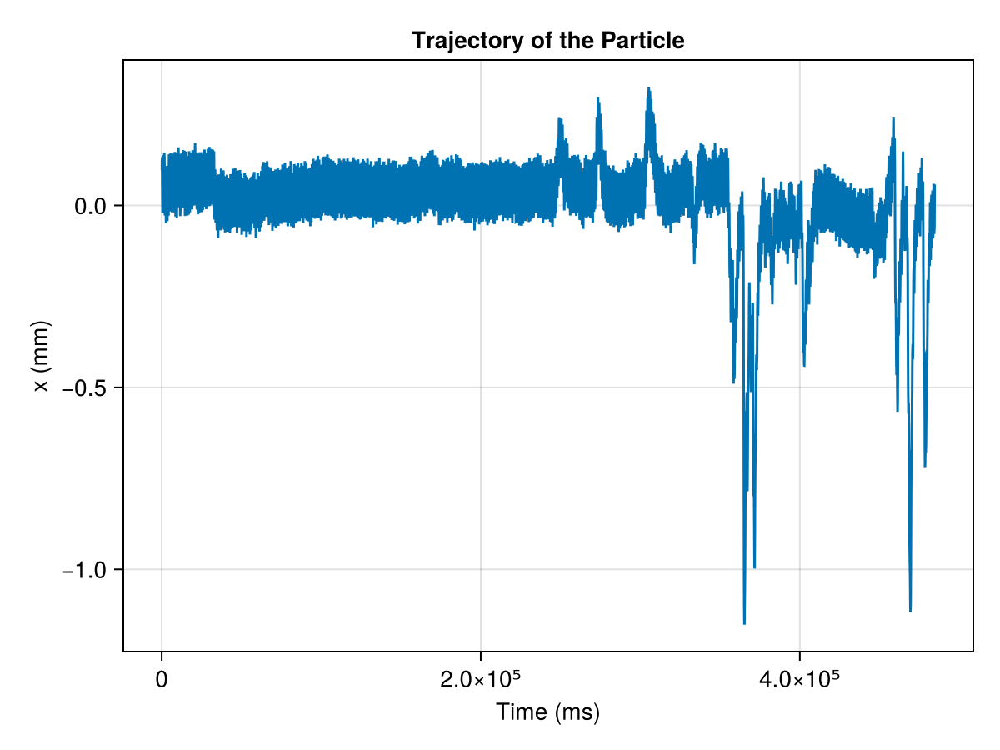

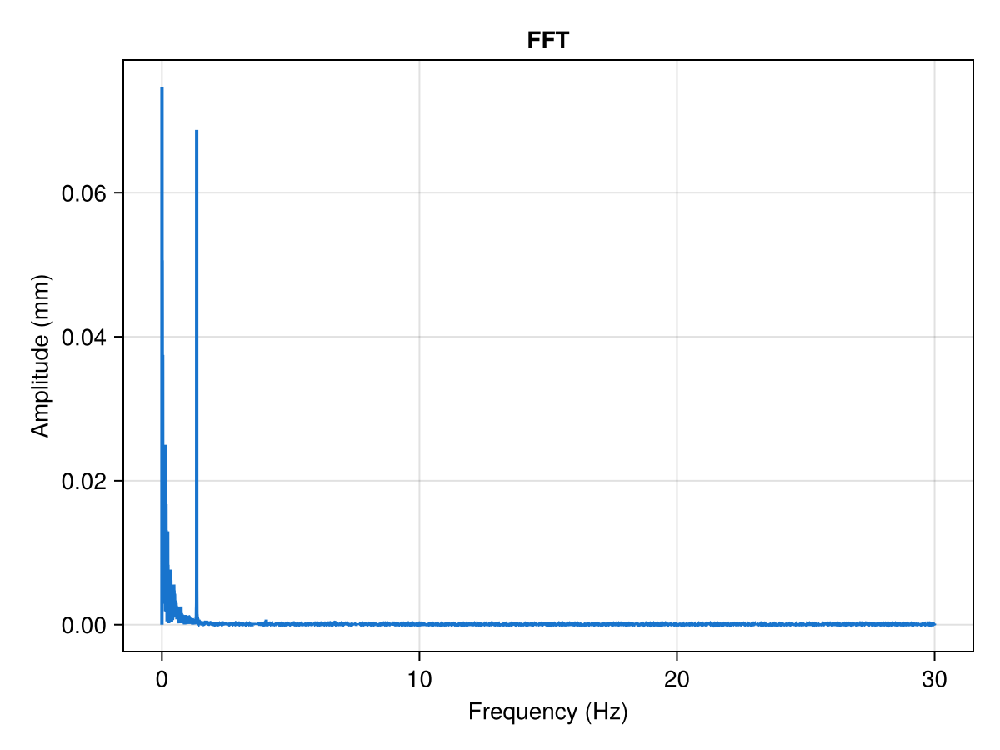

fs_real = 60.00924142317911 Hz (Nyquist = 30.004620711589556 Hz)
fs_effective = 60.00924142317911 Hz (Nyquist = 30.004620711589556 Hz)
window = 29067 points
freq. resolution = 0.0020645144467326903 Hz


(0.0020645144467326903, 7.468642720857579e-5)

In [84]:
ts, rs = importTrackerData("../analysis/1350_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[9], amps_[9] = freqs[argmax(amps)], maximum(amps)

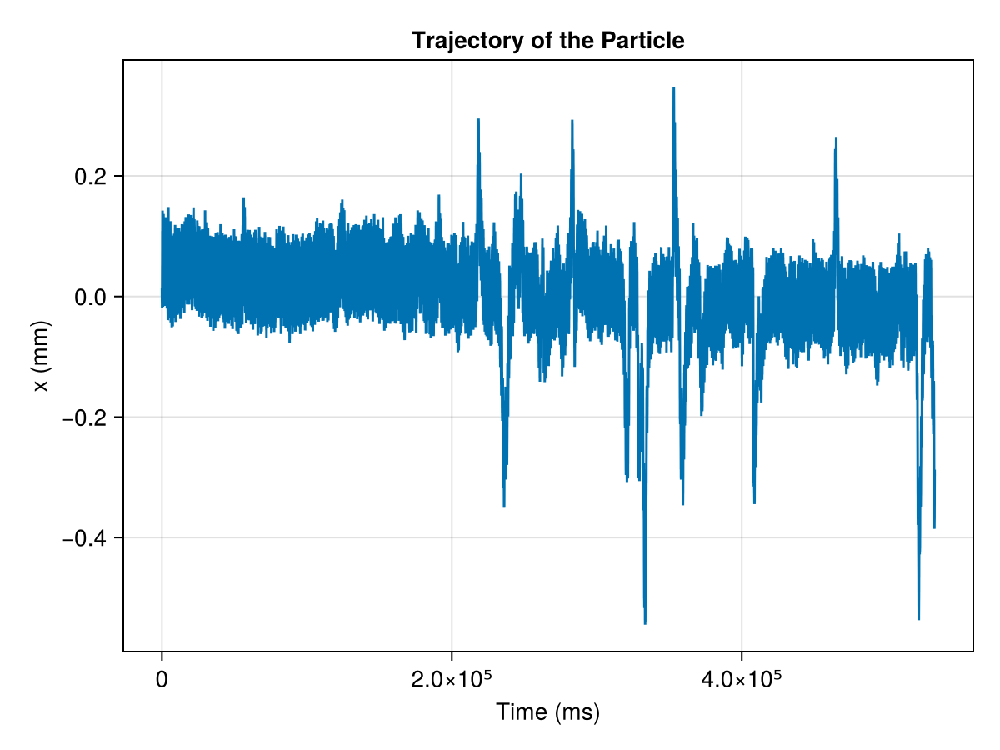

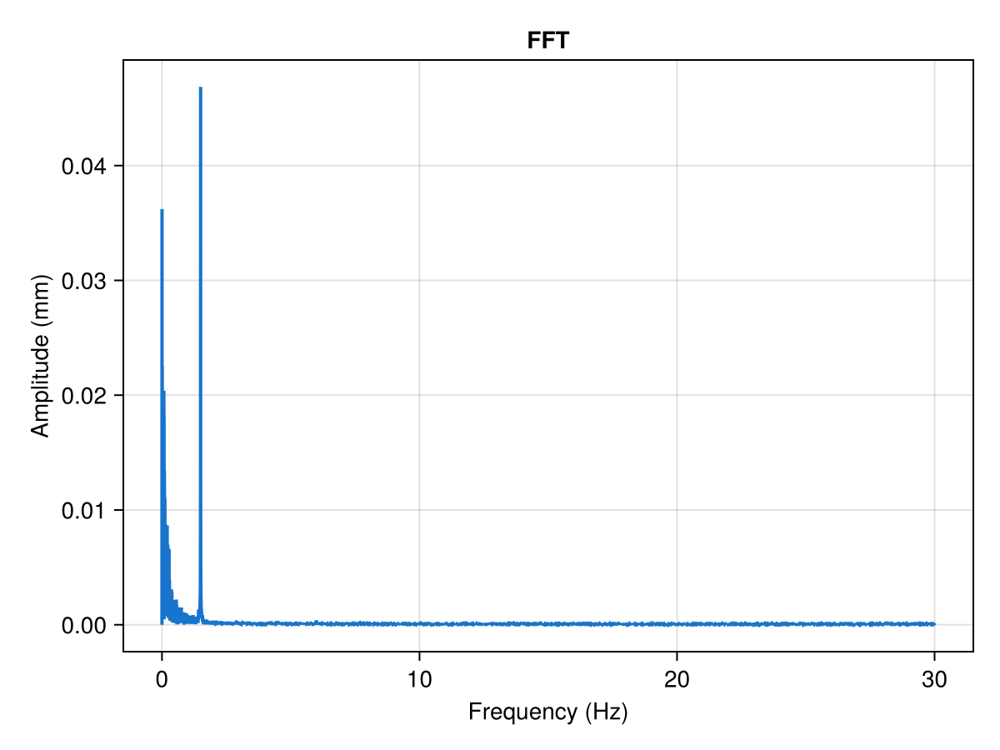

fs_real = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
fs_effective = 60.009817606160375 Hz (Nyquist = 30.004908803080188 Hz)
window = 31988 points
freq. resolution = 0.001876010304056533 Hz


(1.5008082432452263, 4.6855193973545266e-5)

In [93]:
ts, rs = importTrackerData("../analysis/1500_mHz.txt"); rs = rs .- mean(rs)
fs_obj = 2.5 * (2 * 1)
fig, ax = plot1dTraj(rs, ts; step=1, dim="x"); display(GLMakie.Screen(), fig.scene);
freqs, amps = getFFT(ts, rs; )
fig, ax = plotFFT(freqs, amps); display(GLMakie.Screen(), fig.scene);
freqs_[10], amps_[10] = freqs[argmax(amps)], maximum(amps)

### z Osc test

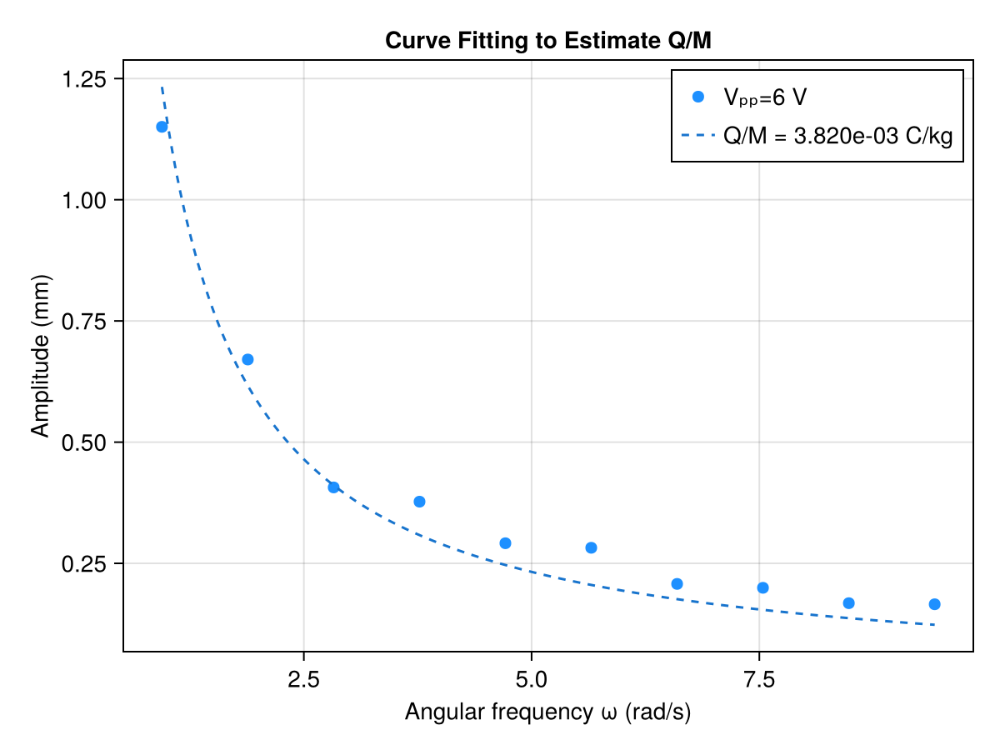

0.003819617329307211

In [35]:
ρ = 510; E = abs(mean(3Ez_EC1_grid[iˣ(0), iʸ(0), iᶻ(0):iᶻ(1e-3)]))
ωs = 2π*collect(150e-3:150e-3:1.5)
nsy_As = [Q/M * (2R^2 * ρ * E)/(9ηᵥ * ω) + rand()*1e-4 for ω in ωs]
Q╱M_est = getEstimatedQ╱M(ωs, nsy_As, E, R, ρ, ηᵥ, [3.5e-3])

In [ ]:
Nₘ = 10; freqs, amps = processZOscData(150, 150, Nₘ; path="exp2/", filename="6_", offset = 9.6e-3/2; show_fft=true, show_traj=true, mov_mean=true); 

┌ Warning: Found 5 missing lines in ../analysis/exp2/6_150.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:186
┌ Warning: Found 47 missing lines in ../analysis/exp2/6_300.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:186
┌ Warning: Found 11 missing lines in ../analysis/exp2/6_450.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:186
┌ Warning: Found 11 missing lines in ../analysis/exp2/6_750.txt. Filled by linear interpolation.
└ @ Main c:\Users\chris\Proyectos\EI-AD25-140\simulations\jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W4sZmlsZQ==.jl:186
┌ Warning: Found 14 missing lines in ../analysis/exp2/6_900.txt. Filled by linear interpolation.
└ @ Main